# PCLab#5 - Group 4 - Claas Boumans Giuliano Ciaramella Theodor Nissen-Meyer

**20598 – Finance with Big Data, PC Lab #5: Hackathon, NGO Press Campaigns and Responsible Investment**

*Time required: approximately >10 hours (mostly due to extra work, beyond the required scope). Difficulty: 8 out of 10.*

## 0. Setup
Libraries, the chart theme of the previous labs and the shared helpers (`show`, `vertical_grid`, `annotate` from PC Lab #4, `ols` from PC Lab #3, first built in PC Lab #2). The few constants used everywhere stand in the setup cell, all others where they are first needed. All data files are read from this folder. The Fama French factors are downloaded, so a run needs internet. Task #3 also downloads two language models, if `torch` and `transformers` are installed. Without them it is skipped and the rest of the notebook still runs, but our markdown comments assume the completion of Task #3.

In [490]:
import glob
import html
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS

pd.set_option("display.float_format", "{:,.4f}".format)
# Hide pandas' notice on its new stack() implementation
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42  # fixed random seed, so every run gives the same results
Z_95 = 1.96  # half width of a 95% interval, in standard errors
ALPHA = 0.05  # significance level of our tests

In [491]:
# Chart theme inspired by The Economist: white background, horizontal gridlines,
# bold left-aligned titles, red rule on top, the magazine's blue/teal palette.
ECONOMIST_RED = "#E3120B"
ECONOMIST_COLORS = ["#006BA2", "#3EBCD2", "#379A8B", "#EBB434", "#B4BA39",
                    "#9A607F", "#D1B07C", "#758D99", "#DB444B"]
ECONOMIST_BLUES = LinearSegmentedColormap.from_list("economist_blues", ["#C5E4F0", "#3EBCD2", "#006BA2", "#0C2A4A"])
DARK, GREY, LIGHT_GREY = "#333333", "#758D99", "#C9D3D9"      # text and reference lines; benchmarks
GRID = "#D0D0D0"

plt.rcParams.update({
    "figure.figsize": (14, 6),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=ECONOMIST_COLORS),
    "axes.grid": True,
    "axes.grid.axis": "y",              # horizontal gridlines only
    "grid.color": GRID,
    "axes.axisbelow": True,             # gridlines behind the data
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelcolor": DARK,
    "xtick.color": DARK,
    "ytick.color": DARK,
    "ytick.left": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

In [492]:
# Chart helpers, shared by every figure of the notebook
WHITE_BOX = {"facecolor": "white", "edgecolor": "none", "pad": 0.5}    # behind a label that crosses a line, improve readability


def show(title=None):
    '''Add the headline, the red rule and the tag on top of the current figure, then display it.'''
    fig = plt.gcf()
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout()
    fig.add_artist(plt.Line2D([0, 1], [1.02, 1.02], transform=fig.transFigure, color=ECONOMIST_RED, lw=1.5))
    fig.add_artist(plt.Rectangle((0, 1.02), 0.035, 0.015, transform=fig.transFigure, color=ECONOMIST_RED,
                                 clip_on=False))
    plt.show()


def vertical_grid(ax):
    '''Vertical gridlines only, for charts read along the x-axis.'''
    ax.grid(False, axis="y")
    ax.grid(True, axis="x", color=GRID)


def annotate(ax, text, xy, offset=(9, 0), **kwargs):
    '''
    Produce a text next to the point x|y, shifted by `offset` (in points): to its right for a positive horizontal shift,
    to its left for a negative one, centred on it for none. Other arguments go to ax.annotate.
    '''
    dx = offset[0]
    style = {"ha": "left" if dx > 0 else "right" if dx < 0 else "center", "va": "center", "fontsize": 9.5,
             "color": DARK}
    ax.annotate(text, xy, xytext=offset, textcoords="offset points", **{**style, **kwargs})


def ols(y, x, hac_lags=0, clusters=None):
    '''
    OLS of y on a constant and x, estimated with statsmodels (as in PC Lab #2).
    hac_lags > 0 returns Newey-West standard errors, clusters returns standard errors clustered by that group.
    '''
    model = sm.OLS(np.asarray(y, dtype=float), sm.add_constant(np.asarray(x, dtype=float)))
    if clusters is not None:
        return model.fit(cov_type="cluster", cov_kwds={"groups": np.asarray(clusters)})
    if hac_lags:
        return model.fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
    return model.fit()

## Day 1 – Explore the NGO data
Before we look at any price, we need one clean list of events. Day 1 turns the reports of Sigwatch from 2010 to 2018 into a table with **one row per bank and day**, which we call an event: bank, date, NGO, sentiment (the tone towards the bank), prominence (where the report names it), NGO power (the geographic reach of the NGO) and issue. Task #5 merges this table with the prices, so every cleaning step here decides which events we can test.

### D1.1 Import the data and sanity check
Sigwatch delivers one Stata file per year. One row is one firm named in one NGO action, so a report naming three firms gives three rows, and one row can carry up to five NGOs (Koenig, 2017).

In [493]:
SIGWATCH_FILES = "sigwatch_data/*_data_sigwatch.dta"  # one file per year


def load_sigwatch():
    '''Append the yearly Sigwatch files into one table.'''
    paths = sorted(glob.glob(SIGWATCH_FILES))
    tables = [pd.read_stata(path) for path in paths]
    return pd.concat(tables, ignore_index=True)


raw = load_sigwatch()

We trim the text, because names such as "Van Lanschot " end in a space, and we turn empty text into missing values.

In [494]:
text_columns = raw.select_dtypes("object").columns
raw[text_columns] = raw[text_columns].apply(lambda text: text.str.strip())
# Stata stores missing text as an empty string
raw = raw.replace("", np.nan)
raw["date"] = pd.to_datetime(raw["date"])
row_year = raw["date"].dt.year

print(f"Rows: {len(raw):,}, columns: {raw.shape[1]}")
print(f"From {raw['date'].min():%d %b %Y} to {raw['date'].max():%d %b %Y}")
print(raw.groupby(row_year).size().to_string())

Rows: 73,094, columns: 94
From 04 Jan 2010 to 19 Dec 2018
date
2010     3439
2011     6030
2012     7366
2013     8488
2014     8761
2015     8547
2016     8582
2017     9307
2018    12574


**Sanity check.** The Sigwatch note (Koenig, 2017) and the do file of the course, the Stata cleaning script that comes with the data, warn of several traps, so we count them first.

**Check 1 – Duplicates and the US label.**

In [495]:
print("Exact duplicate rows:", raw.duplicated().sum())

# Trap: the US is "US" up to 2015 and "USA" from 2016
us_rows = raw[raw["company_parent_country"].isin(["US", "USA"])]
print(pd.crosstab(us_rows["company_parent_country"], us_rows["date"].dt.year))

Exact duplicate rows: 0
date                    2010  2011  2012  2013  2014  2015  2016  2017  2018
company_parent_country                                                      
US                      1136  1969  2611  2675  2952  2991     0     0     0
USA                        0     0     0     0     0     0  2929  3235  4321


**Check 2 – NGO names and NGO power.**

In [496]:
spellings = raw.groupby("ngo_code1")["ngo_name1"].nunique()
power_values = raw.groupby("ngo_code1")["ngo_power1"].nunique()
# Two values in one year would be noise, across years a re-rating
yearly_values = raw.groupby(["ngo_code1", row_year])["ngo_power1"].nunique()

two_spellings = (spellings > 1).sum()
changing_power = (power_values > 1).sum()
two_values = (yearly_values > 1).sum()

print(f"NGO codes with two spellings: {two_spellings} of {len(spellings):,}")
print(f"NGOs whose power changes: {changing_power} of {len(power_values):,}")
print(f"NGO years with two powers: {two_values} of {len(yearly_values):,}")

NGO codes with two spellings: 78 of 3,010
NGOs whose power changes: 205 of 3,010
NGO years with two powers: 0 of 7,236


**Check 3 – Undefined prominence and missing parents.**

In [497]:
is_subsidiary = raw["company_type"] == "Subsidiary"
no_parent = raw.loc[is_subsidiary, "company_parent"].isna()

# Prominence runs from 1 to 4, so 0 has no defined meaning
print("Rows with prominence 0:", (raw["prominence"] == 0).sum())
print(f"Subsidiaries without parent: {no_parent.sum()} of {len(no_parent):,}")

Rows with prominence 0: 44
Subsidiaries without parent: 24 of 10,018


**Comments – D1.1**
* **The files append cleanly:** 73,094 rows, 94 columns, no exact duplicates. Rows rise from 3,439 in 2010 to 12,574 in 2018.
* **The US has two labels:** "US" up to 2015 and "USA" from 2016. A filter on one label would lose years of data, so we merge them.
* **NGO names are not unique:** 78 of 3,010 NGO codes have two spellings. We count NGOs by code.
* **NGO power is a rating, not noise:** 205 NGOs change value, but none of the 7,236 NGO years holds two values. So Sigwatch re-rates NGOs between years. It could mix with the split around COP21, the Paris climate conference of December 2015, hence **each NGO keeps its most frequent value.**
* **Parents are well recorded:** only 24 of 10,018 subsidiary rows have no parent, so the rule of D1.2 can rely on them.

### D1.2 Keep the bank campaigns
Sigwatch's Finance sector also holds insurers, pension funds and development banks, so we select banks by name: a firm is in our study only if it is a bank with a Datastream price series.

Three rules decide who is who:
* **Own name first.** A firm with its own price series stays itself. Natixis and CaixaBank are subsidiaries of unlisted groups, so their parents have no prices.
* **Otherwise the parent.** Sigwatch records the parent of a subsidiary: Santander UK is Grupo Santander, NatWest is RBS, Halifax is Lloyds.
* **Country is the parent's country.** Euro area, Sweden, UK and US. We leave out Norway and Switzerland.

One exception: Sigwatch records Smithfield Foods and Shuanghui under Goldman Sachs. Those are pig welfare campaigns against a food firm, so we drop these rows. Owned firms where the bank is a fair target stay, such as Third Energy (fracking) under Barclays.

The do file of the course (`example_name_cleaning.txt`) holds a list of names, which we translate into a dictionary from the Sigwatch name in lower case to the Datastream column. We remove its wrong renames (Pinnacle West, Berkshire Hathaway, Lloyd's of London, Generali, Virgin Group, ACE, Allianz).

In [498]:
# Sigwatch name in lower case: Datastream column
DO_FILE_NAMES = {
    "abn amro bank n.v.": "ABN AMRO BANK",
    "bank of america": "BANK OF AMERICA",
    "bank of ireland": "BANK OF IRELAND GROUP",
    "bank of new york mellon / bny mellon": "BANK OF NEW YORK MELLON",
    "banco sabadell": "BANCO DE SABADELL",
    "bankia": "BANKIA",
    "barclays bank": "BARCLAYS",
    "bbva group / banco bilbao vizcaya argentaria": "BBV.ARGENTARIA",
    "bnp paribas": "BNP PARIBAS",
    "caixabank": "CAIXABANK",
    "citigroup": "CITIGROUP",
    "citizens financial group": "CITIZENS FINANCIAL GROUP",
    "comerica": "COMERICA",
    "commerzbank": "COMMERZBANK",
    "credit agricole": "CREDIT AGRICOLE",
    "deutsche bank": "DEUTSCHE BANK",
    "discover card": "DISCOVER FINANCIAL SVS.",
    "discover financial services": "DISCOVER FINANCIAL SVS.",
    "erste group": "ERSTE GROUP BANK",
    "fifth third bank": "FIFTH THIRD BANCORP",
    "grupo santander": "BANCO SANTANDER",
    "hsbc": "HSBC HOLDINGS",
    "huntington bank": "HUNTINGTON BCSH.",
    "ing": "ING GROEP",
    "intesa sanpaolo": "INTESA SANPAOLO",
    "kbc bank": "KBC GROUP",
    "keycorp": "KEYCORP",
    "liberbank": "LIBERBANK",
    "lloyds banking group plc": "LLOYDS BANKING GROUP",
    "m&t bank": "M&T BANK",
    "metro bank": "METRO BANK",
    "monte dei paschi di siena bank / bmps": "BANCA MONTE DEI PASCHI",
    "natixis": "NATIXIS",
    "nibc": "NIBC HOLDING",
    "nordea": "NORDEA BANK",
    "allied irish banks p.l.c. (aib)": "AIB GROUP",
    "permanent tsb": "PERMANENT TSB GHG.",
    "pnc bank": "PNC FINL.SVS.GP.",
    "rbs": "ROYAL BANK OF SCTL.GP.",
    "rbs group": "ROYAL BANK OF SCTL.GP.",
    "royal bank of scotland (rbs)": "ROYAL BANK OF SCTL.GP.",
    "societe generale": "SOCIETE GENERALE",
    "standard chartered bank": "STANDARD CHARTERED",
    "svb financial": "SVB FINANCIAL GROUP",
    "swedbank ab": "SWEDBANK A",
    "synovus financial": "SYNOVUS FINANCIAL",
    "tcf bank": "TCF FINANCIAL",
    "umweltbank": "UMWELTBANK",
    "unicaja": "UNICAJA BANCO",
    "unicredit": "UNICREDIT",
    "us bancorp": "US BANCORP",
    "van lanschot": "VAN LANSCHOT KEMPEN",
    "virgin money": "VIRGIN MONEY UK",
    "wells fargo & wachovia": "WELLS FARGO & CO",
    "zions bank": "ZIONS BANCORP.",
}

We add the names that the do file misses or misspells.

In [499]:
MISSING_NAMES = {
    "bankinter, s.a.": "BANKINTER 'R'",
    "goldman sachs group, inc.": "GOLDMAN SACHS GP.",
    "handelsbanken": "SVENSKA HANDELSBANKEN A",
    "jp morgan chase": "JP MORGAN CHASE & CO.",
    # Two spellings
    "skandinaviska enskilda banken ab (seb)": "SKANDINAVISKA ENSKILDA BANKEN A",
    "skandinaviska enskilda banken ab / seb": "SKANDINAVISKA ENSKILDA BANKEN A",
}

Sigwatch also records some of our banks under another name.

In [500]:
OTHER_NAMES = {
    "allied irish banks aib": "AIB GROUP",
    "ally financial": "ALLY FINANCIAL",
    "bank of new york mellon": "BANK OF NEW YORK MELLON",
    "berkshire bank": "BERKSHIRE HILLS BANCORP",
    "bny mellon": "BANK OF NEW YORK MELLON",
    # Truist is BB&T renamed, so its series is the history of BB&T
    "branch banking and trust bb&t": "TRUIST FINANCIAL",
    "comerzbank": "COMMERZBANK",  # misspelt in Sigwatch
    "keybank": "KEYCORP",
    "mediobanca": "MEDIOBANCA BC.FIN",
    "millenium bcp": "BANCO COMR.PORTUGUES 'R'",  # misspelt in Sigwatch
    "people's united bank": "PEOPLES UNITED FINANCIAL",
    "regions bank": "REGIONS FINL.NEW",
    "u.s. bank": "US BANCORP",
}

BANK_NAMES = DO_FILE_NAMES | MISSING_NAMES | OTHER_NAMES

Now we apply the three rules to every row.

In [501]:
# Euro area countries in Datastream, then Sweden, the UK and the US
COUNTRIES = [
    "Austria", "Belgium", "Cyprus", "Estonia", "Finland", "France", "Germany",
    "Greece", "Ireland", "Italy", "Lithuania", "Malta", "Netherlands",
    "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden", "UK", "US",
]

# Recorded under Goldman Sachs, but the campaigns are about food firms
FOOD_FIRMS = ["Smithfield Foods", "Shuanghui International Holdings"]


def match_banks(raw):
    '''Keep the rows on our banks, matched by own name, else by parent.'''
    own_name = raw["company"].str.lower()
    parent_name = raw["company_parent"].str.lower()
    is_subsidiary = raw["company_type"] == "Subsidiary"

    # Own name first: a parent counts only for a subsidiary
    own_bank = own_name.map(BANK_NAMES)
    parent_bank = parent_name.map(BANK_NAMES).where(is_subsidiary)

    rows = raw.copy()
    rows["bank"] = own_bank.fillna(parent_bank)
    rows["through_parent"] = own_bank.isna()
    # One label for the US
    rows["country"] = raw["company_parent_country"].replace("USA", "US")

    has_bank = rows["bank"].notna()
    in_country = rows["country"].isin(COUNTRIES)
    is_food_firm = rows["company"].isin(FOOD_FIRMS)
    return rows[has_bank & in_country & ~is_food_firm].copy()


bank_rows = match_banks(raw)

Every name of the dictionary must exist in the price files, to ensure Task #5 does not lose that bank without any warning.

In [502]:
MAIN_PRICES = "banks_data_bocconi/banks_ri.xlsm"
# Sweden has its own file
NORDIC_PRICES = "banks_data_bocconi/scandinavian_banks_ri.xlsm"
RI_TAIL = " - TOT RETURN IND"  # Datastream adds this to every column name


def read_sheets(main_file, nordic_file, rows=None):
    '''Read the country sheets of a Datastream file, Sweden included.'''
    sheets = pd.read_excel(main_file, sheet_name=None, nrows=rows)
    sheets.pop("REQUEST_TABLE")  # a log of the download, not prices
    sheets["SD"] = pd.read_excel(nordic_file, sheet_name="SD", nrows=rows)
    return sheets


def datastream_banks():
    '''Read the firm names in the Datastream return files of our countries.'''
    sheets = read_sheets(MAIN_PRICES, NORDIC_PRICES, rows=0)  # headers only

    headers = set()
    for sheet in sheets.values():
        headers.update(sheet.columns)
    headers.discard("Name")  # the date column

    return {header.replace(RI_TAIL, "") for header in headers}

In [503]:
price_columns = datastream_banks()
targets = set(BANK_NAMES.values())
found = len(targets & price_columns)
print(f"Dictionary names found in Datastream: {found} of {len(targets)}")

Dictionary names found in Datastream: 64 of 64


The sample that this leaves us with:

In [504]:
through_parent = bank_rows["through_parent"].sum()
named_directly = len(bank_rows) - through_parent
bank_share_of_rows = len(bank_rows) / len(raw)

print(f"Rows on our banks: {len(bank_rows):,} ({bank_share_of_rows:.1%})")
print(f"Named directly: {named_directly:,}")
print(f"Through the parent: {through_parent:,}")
print(f"Sigwatch reports: {bank_rows['uid_archive'].nunique():,}")
print("Banks:", bank_rows["bank"].nunique())
print("Rows with prominence 0:", (bank_rows["prominence"] == 0).sum())

Rows on our banks: 3,197 (4.4%)
Named directly: 2,906
Through the parent: 291
Sigwatch reports: 1,280
Banks: 64
Rows with prominence 0: 0


Who is left out? In the same countries, these firms of the Finance sector have the most rows without a match.

In [505]:
is_finance = raw["corp_industry_sector1"] == "Finance"
parent_country = raw["company_parent_country"].replace("USA", "US")
finance = raw[is_finance & parent_country.isin(COUNTRIES)]

# errors="ignore": a bank row need not lie in the Finance sector
unmatched = finance.drop(index=bank_rows.index, errors="ignore")
matched_share = finance.index.isin(bank_rows.index).mean()

print(f"Finance rows in our countries: {len(finance):,}")
print(f"Of which matched: {matched_share:.1%}")
print(unmatched["company"].value_counts().head(12).to_string())

Finance rows in our countries: 6,226
Of which matched: 51.2%
company
World Bank                               239
EBRD                                      95
Rabobank                                  94
AXA                                       65
Morgan Stanley                            64
IFC International Finance Corporation     64
Triodos Bank                              55
BlackRock                                 42
Allianz Group / Allianz SE                42
Aegon Bank                                39
Allianz SE                                38
World Bank Group                          36


**Comments – D1.2**
* **Banks are a small corner of Sigwatch:** 3,197 of 73,094 rows (4.4%), from 1,280 reports, on 64 banks.
* **The dictionary is safe:** all 64 target names exist in the price files, so no bank can get lost through a spelling in Task #5.
* **The parent rule matters:** 291 rows reach a bank only through its parent, such as NatWest or Santander UK.
* **Half of the Finance sector stays out, mostly for good reasons:** only 51.2% of its 6,226 rows match. The rest are development banks (World Bank 239, EBRD 95), insurers (AXA 65, Allianz, Aegon), unlisted banks (Rabobank 94, Triodos 55) and asset managers (BlackRock 42).
* **Our largest real loss is Morgan Stanley (64 rows):** a listed bank, but not in our price files. We leave it out and download no extra prices, as for UBS and Credit Suisse.
* **The undefined prominence does not touch us:** none of the 44 rows with prominence 0 is on our banks.

### D1.3 From rows to events
A bank can appear in many rows without being hit many times. We follow the do file of the course and Krüger (2015), the event study of corporate social responsibility news on which our method is built, in this order:

| Step | Rule | Why |
|---|---|---|
| 1 | Same NGO, same bank, same day: one row | the same action, recorded twice |
| 2 | Same NGO, same bank, less than 30 days apart: keep the first | a follow up adds little for the market |
| 3 | Positive and negative event on the same bank on the same day: drop both | the price reaction could not be read (Krüger, 2015) |
| 4 | Same bank, same day: one event | the market sees one bank day |

Steps 1 and 4 keep the worst sentiment and the highest prominence. The order matters: step 4 comes last because it erases what steps 2 and 3 need. A merged bank day no longer shows which NGO acted, and keeping the worst sentiment would hide a positive event on that day. Neutral events stay in the charts of Day 1 and we leave them out of the tests.

The do file widens step 3 to 5 days. That costs many positive events, so we keep the same day rule of Krüger (2015) and use the 5 days only as a robustness check in Task #6.

**Step 1 – One row per NGO, bank and day.**

In [506]:
def merge_rows(rows, keys):
    '''Keep one row per key, with the worst sentiment and top prominence.'''
    # Worst sentiment first
    ordered = rows.sort_values(["sentiment", "prominence"],
                               ascending=[True, False])
    # The top prominence can sit on another row than the worst sentiment
    top_prominence = ordered.groupby(keys)["prominence"].transform("max")
    ordered["prominence"] = top_prominence
    return ordered.drop_duplicates(keys)


ngo_days = merge_rows(bank_rows, ["bank", "ngo_code1", "date"])
print(f"Rows: {len(bank_rows):,} to {len(ngo_days):,}")

Rows: 3,197 to 3,081


**Step 2 – Only the first event of a run by the same NGO.** As in the do file, we count calendar days from the previous event of the pair.

In [507]:
REPEAT_DAYS = 30  # calendar days, as in the do file


def drop_repeats(rows):
    '''Keep the first event of each run by the same NGO on the same bank.'''
    ordered = rows.sort_values(["bank", "ngo_code1", "date"])
    pairs = ordered.groupby(["bank", "ngo_code1"])["date"]
    days_since_last = pairs.diff().dt.days
    # The first event of a pair has no gap (NaN), and this form keeps it
    return ordered[~(days_since_last < REPEAT_DAYS)]


first_events = drop_repeats(ngo_days)
print(f"Rows: {len(ngo_days):,} to {len(first_events):,}")

Rows: 3,081 to 2,773


**Step 3 – No opposite signs on the same day.** We compare every signed event of a bank with all its other signed events, in calendar days.

In [508]:
OPPOSITE_DAYS = 0  # the same day, as in Krüger (2015)


def find_conflicts(rows, window):
    '''Find the rows with an event of opposite sign within `window` days.'''
    columns = ["bank", "date", "sentiment"]
    # Index: the rows to drop
    signed = rows.loc[rows["sentiment"] != 0, columns].reset_index()
    # Every signed event of a bank meets all its other signed events
    pairs = signed.merge(signed, on="bank", suffixes=("", "_other"))

    days_apart = (pairs["date"] - pairs["date_other"]).dt.days.abs()
    is_close = days_apart <= window
    is_opposite = pairs["sentiment"] * pairs["sentiment_other"] < 0

    return pairs.loc[is_close & is_opposite, "index"].unique()


same_day_conflicts = find_conflicts(first_events, OPPOSITE_DAYS)
no_conflicts = first_events.drop(same_day_conflicts)
print(f"Rows: {len(first_events):,} to {len(no_conflicts):,}")

Rows: 2,773 to 2,727


The 5 day rule of the do file drops nothing here. We only flag the rows it would drop, so that Task #6 can rerun our tests without them.

In [509]:
ROBUST_DAYS = 5  # do file, calendar days

five_day_conflicts = find_conflicts(first_events, ROBUST_DAYS)
# Flag only: the main sample keeps the same day rule
is_flagged = no_conflicts.index.isin(five_day_conflicts)
no_conflicts["conflict_5_days"] = is_flagged
print(f"Rows flagged: {is_flagged.sum():,} of {len(no_conflicts):,}")

Rows flagged: 209 of 2,727


**Step 4 – One event per bank and day.**

In [510]:
bank_days = merge_rows(no_conflicts, ["bank", "date"])
print(f"Rows: {len(no_conflicts):,} to {len(bank_days):,}")

Rows: 2,727 to 2,631


Next we prepare the variables of the final table. A row can name up to five NGOs, so we count all five slots.

In [511]:
# A row holds up to five NGOs
NGO_SLOTS = [f"ngo_code{slot}" for slot in range(1, 6)]


def count_ngos(rows):
    '''Count the different NGOs per bank day, over all five NGO slots.'''
    slots = rows.melt(id_vars=["bank", "date"], value_vars=NGO_SLOTS,
                      value_name="ngo")
    slots = slots.dropna(subset="ngo")
    return slots.groupby(["bank", "date"])["ngo"].nunique().rename("n_ngos")

The issue groups for Task #6 come from Sigwatch's labels. The first group that matches wins. Climate uses the keywords of the do file, so it is wide on purpose.

In [ ]:
# Keywords of the do file, as regular expressions
CLIMATE_WORDS = [
    "carbon", "climate", "coal", "mining", "oilsands", "logging", "oil",
    "fossil", "pipelines?", "gas", "drilling", "refiner", "shale", "fracking",
    "arctic", "ghg", "lng", "greenwashing", "renewable", "plastics", "methane",
    "land.grabbing",
]
CONSUMER_WORDS = [
    "consumer", "customer", "lending abuses", "excessive charges",
    "mis-selling",
]

# The order matters: the first match wins. \b makes a keyword start a word, so "soil" does not count as "oil"
ISSUE_GROUPS = {
    "Climate and fossil fuels": r"\b(?:" + "|".join(CLIMATE_WORDS) + ")",
    "Tax": r"\btax",
    "Consumer protection": "|".join(CONSUMER_WORDS),
    "Arms": r"\barms\b|weapon",  # \b keeps "farms" out
}

In [513]:
ISSUE_LABELS = ["issue_name1", "issue_name2", "issue_name3"]


def issue_group(rows):
    '''Give each row the first issue group that matches its labels.'''
    # One text per row, so a keyword can match any of the three labels
    label_text = rows[ISSUE_LABELS].fillna("").agg(" | ".join, axis=1)
    label_text = label_text.str.lower()

    groups = pd.Series("Other", index=rows.index)
    # Reversed: the first group of the list is written last, so it wins
    for group, keywords in reversed(ISSUE_GROUPS.items()):
        groups[label_text.str.contains(keywords)] = group
    return groups

NGO power changes between years (D1.1), so each NGO keeps its most frequent value. NGO names also get one spelling per code.

In [514]:
def fixed_ngo_power(raw):
    '''Find the most frequent power of each NGO.'''
    powers = raw.groupby("ngo_code1")["ngo_power1"]
    # On a tie mode() lists the values in order, so we keep the lowest
    return powers.agg(lambda power: power.mode().iloc[0])


ngo_power = fixed_ngo_power(raw)
ngo_names = raw.groupby("ngo_code1")["ngo_name1"].first()

In [738]:
# Building the final table

SIGN_NAMES = {-1: "negative", 0: "neutral", 1: "positive"}
NON_EURO = ["US", "UK", "Sweden"]  # all other countries form the euro area
TABLE_COLUMNS = [
    "bank", "date", "year", "country", "country_group", "ngo_code1", "ngo",
    "sentiment", "sign", "prominence", "ngo_power", "n_ngos", "issue_group",
    "issue_name1", "uid_archive", "report", "conflict_5_days",
]

ngos_per_event = count_ngos(no_conflicts)
events = bank_days.merge(ngos_per_event, on=["bank", "date"],
                         validate="one_to_one")

events["ngo"] = events["ngo_code1"].map(ngo_names)
# Fixed per NGO, see D1.1
events["ngo_power"] = events["ngo_code1"].map(ngo_power)
events["issue_group"] = issue_group(events)
events["year"] = events["date"].dt.year
# Two levels per sign
events["sign"] = np.sign(events["sentiment"]).map(SIGN_NAMES)

is_non_euro = events["country"].isin(NON_EURO)
events["country_group"] = events["country"].where(is_non_euro, "Euro area")

events = events[TABLE_COLUMNS].sort_values(["date", "bank"])
events = events.reset_index(drop=True)

We check the result. No bank day may appear twice, and no conflict may survive. For the conflicts we use a second method, a plain loop over the banks.

In [516]:
def conflicts_by_loop(events):
    '''Count positive and negative events of a bank that are close in time.'''
    conflicts = 0
    for bank, group in events.groupby("bank"):
        negative_dates = group.loc[group["sentiment"] < 0, "date"]
        for date in group.loc[group["sentiment"] > 0, "date"]:
            days_apart = (negative_dates - date).dt.days.abs()
            conflicts += (days_apart <= OPPOSITE_DAYS).sum()
    return conflicts

In [517]:
# On the rows before cleaning, to see what step 4 alone would hide
sentiment_range = bank_rows.groupby(["bank", "date"])["sentiment"]
lowest = sentiment_range.min()
highest = sentiment_range.max()
both_signs = (lowest < 0) & (highest > 0)

print("Bank days with both signs, before cleaning:", both_signs.sum())
print("Duplicated bank days:", events.duplicated(["bank", "date"]).sum())
print("Opposite signs left on one day:", conflicts_by_loop(events))
print("Events on a weekend:", (events["date"].dt.weekday > 4).sum())
print("Most NGOs on one event:", events["n_ngos"].max())

Bank days with both signs, before cleaning: 41
Duplicated bank days: 0
Opposite signs left on one day: 0
Events on a weekend: 0
Most NGOs on one event: 6


Comparison: What would the 5 day rule cost each sign, compared with the same day rule?

In [518]:
def count_sign(rows, sign):
    '''Count the rows whose sentiment has the given sign.'''
    return (np.sign(rows["sentiment"]) == sign).sum()


unflagged = no_conflicts[~no_conflicts["conflict_5_days"]]

for name, sign in [("Negative", -1), ("Positive", 1)]:
    rows_before = count_sign(first_events, sign)
    same_day_rule = count_sign(no_conflicts, sign)
    five_day_rule = count_sign(unflagged, sign)
    print(f"{name} rows before: {rows_before:,}")
    print(f"Same day rule: {same_day_rule:,} "
          f"(-{1 - same_day_rule / rows_before:.0%})")
    print(f"5 day rule: {five_day_rule:,} "
          f"(-{1 - five_day_rule / rows_before:.0%})")

Negative rows before: 2,242
Same day rule: 2,219 (-1%)
5 day rule: 2,105 (-6%)
Positive rows before: 383
Same day rule: 360 (-6%)
5 day rule: 265 (-31%)


In [519]:
flagged_events = events.groupby("sign")["conflict_5_days"].sum()
print(flagged_events.to_string())

sign
negative    109
neutral       0
positive     95


In [739]:
# For plotting 

def plot_waterfall(ax, counts, step_names, first_name, last_name):
    '''Draw a waterfall from a list of counts after each cleaning step.'''
    positions = range(1, len(counts))
    last_position = len(counts)

    # The first and last bars are totals, the others show what a step removes
    for position, total in [(0, counts[0]), (last_position, counts[-1])]:
        ax.bar(position, total, width=0.7, color=ECONOMIST_COLORS[0])
        annotate(ax, f"{total:,}", (position, total), offset=(0, 10),
                 fontweight="bold")

    for position in positions:
        before, after = counts[position - 1], counts[position]
        ax.bar(position, before - after, bottom=after, width=0.7,
               color=ECONOMIST_COLORS[8])
        annotate(ax, f"-{before - after:,}", (position, before),
                 offset=(0, 10), fontweight="bold")

    ax.set_xticks(range(last_position + 1),
                  [first_name, *step_names, last_name])
    ax.set_ylim(0, counts[0] * 1.1)  # room for the labels

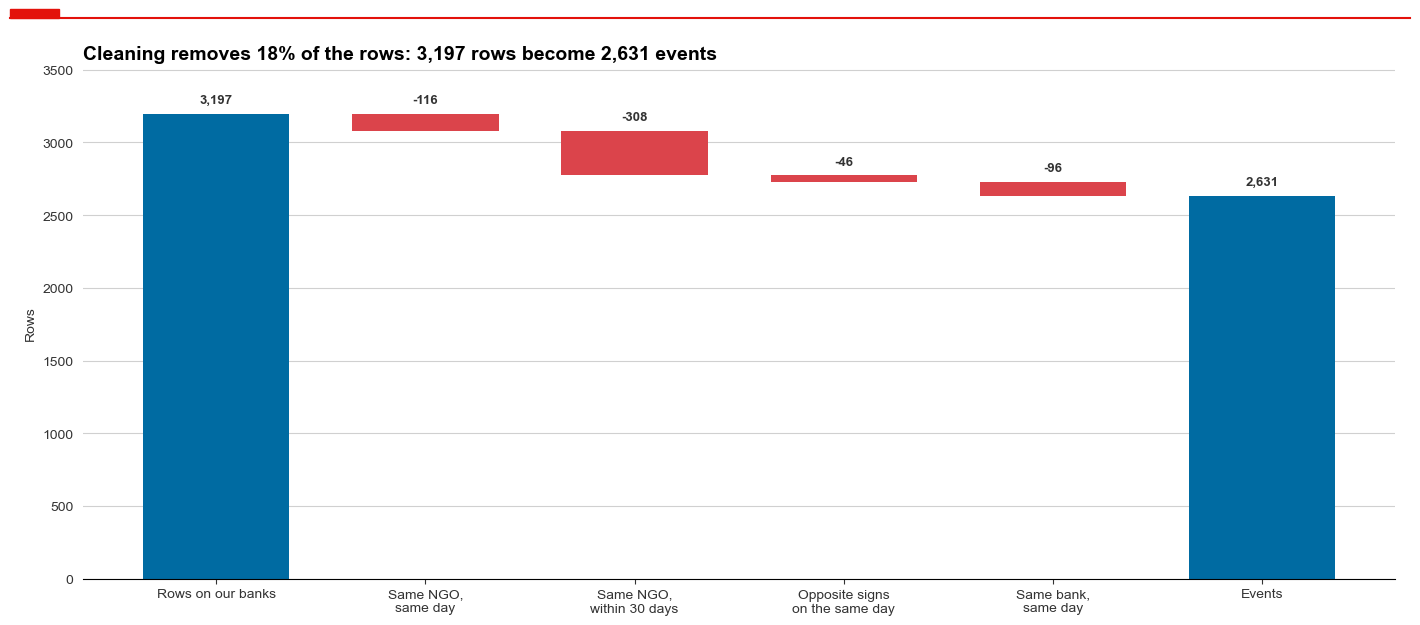

In [521]:
row_counts = [len(bank_rows), len(ngo_days), len(first_events),
              len(no_conflicts), len(bank_days)]
step_names = ["Same NGO,\nsame day", "Same NGO,\nwithin 30 days",
              "Opposite signs\non the same day", "Same bank,\nsame day"]
removed_share = 1 - len(events) / len(bank_rows)

fig, ax = plt.subplots(figsize=(14, 6))
plot_waterfall(ax, row_counts, step_names, "Rows on our banks", "Events")
ax.set_ylabel("Rows")
ax.set_title(f"Cleaning removes {removed_share:.0%} of the rows: "
             f"{len(bank_rows):,} rows become {len(events):,} events")
show()

**Comments – D1.3**
* **Cleaning removes 18% of the rows:** 3,197 rows become 2,631 events. Repeats of the same NGO are the largest cut (−308), then merged bank days (−96). Same day conflicts cost only 46 rows.

* **The checks pass:** no duplicate bank day, no same day conflict left (our plain loop agrees) and no event on a weekend. 41 bank days held both signs before cleaning, which step 4 alone would have hidden.

* **We keep the same day rule of Krüger (2015), because the 5 days of the do file are much harder on positive events:** the same day rule leaves 360 of 383 positive rows (−6%), the 5 day rule would leave 265 (−31%). For negative rows the cost is −1% against −6%. A positive event is rare and most banks are attacked often, so a negative one is usually close.

* **So the comparison of negative and positive events in Task #6 stands on a fuller sample.** `conflict_5_days` flags the 204 events that the 5 day rule would remove (109 negative, 95 positive), so Task #6 can show that rule as one robustness row.

### D1.4 How many campaigns, NGOs and banks
The questions of the slide, first as numbers. We count NGOs by `ngo_code`, because names are not unique.

In [522]:
def describe_events(events):
    '''Measure the size of the sample, for all events and per sign.'''
    groups = {"all": events}
    for sign, group in events.groupby("sign"):
        groups[sign] = group

    rows = []
    for group in groups.values():
        rows.append({
            "events": len(group),
            "share": len(group) / len(events),
            "banks": group["bank"].nunique(),
            "lead NGOs": group["ngo_code1"].nunique(),
            "days": group["date"].nunique(),
            "headline share": (group["prominence"] == 4).mean(),  # 4 = headline
            "several NGOs": (group["n_ngos"] > 1).mean(),
        })
    return pd.DataFrame(rows, index=list(groups)).rename_axis("sign")

In [523]:
# Over all five slots, because a co-signing NGO counts too
all_ngos = no_conflicts[NGO_SLOTS].stack().nunique()
print("Different NGOs over all five slots:", all_ngos)

describe_events(events).style.format({
    "events": "{:,}",
    "share": "{:.1%}",
    "days": "{:,}",
    "headline share": "{:.1%}",
    "several NGOs": "{:.1%}",
})

Different NGOs over all five slots: 516


,events,share,banks,lead NGOs,days,headline share,several NGOs
sign,,,,,,,
all,"2,631",100.0%,64,335,882,19.7%,35.4%
negative,"2,134",81.1%,63,293,779,21.4%,37.1%
neutral,143,5.4%,30,57,80,9.8%,22.4%
positive,354,13.5%,35,102,200,13.3%,30.5%


**What the variables mean.** `sentiment` is the tone towards the firm, coded by Sigwatch staff from −2 to +2. `prominence` says where the firm is named, from 1 (only in an attached report) to 4 (headline). `ngo_power` is the geographic reach of the NGO, from local (0.5) to global (2.75).

Each panel below shows the shares of one variable, so we write one function for it.

In [524]:
def share_bars(ax, shares, labels, colors, title, xlabel):
    '''Draw the share of events per value, with the share on each bar.'''
    bars = ax.bar(labels, shares.values, color=colors, width=0.7)
    for bar, share in zip(bars, shares.values):
        middle = bar.get_x() + bar.get_width() / 2
        annotate(ax, f"{share:.0%}", (middle, share), offset=(0, 9))

    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 0.55)  # same scale on every panel, room for the labels
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel)

In [525]:
SENTIMENT_COLORS = {
    "negative": ECONOMIST_COLORS[8],
    "neutral": ECONOMIST_COLORS[7],
    "positive": ECONOMIST_COLORS[0],
}

sentiment_shares = events["sentiment"].value_counts(normalize=True).sort_index()
prominence_shares = events["prominence"].value_counts(normalize=True)
prominence_shares = prominence_shares.sort_index()
power_shares = events["ngo_power"].value_counts(normalize=True).sort_index()

# The sign of a level sets the colour of its bar
sentiment_signs = np.sign(sentiment_shares.index).map(SIGN_NAMES)
sentiment_colors = [SENTIMENT_COLORS[sign] for sign in sentiment_signs]

sentiment_labels = ["-2", "-1", "0", "+1", "+2"]
prominence_labels = ["1\nattached report", "2\nin the text",
                     "3\nfirst paragraph", "4\nheadline"]
power_labels = [f"{value:g}" for value in power_shares.index]
negative_share_all = (events["sentiment"] < 0).mean()

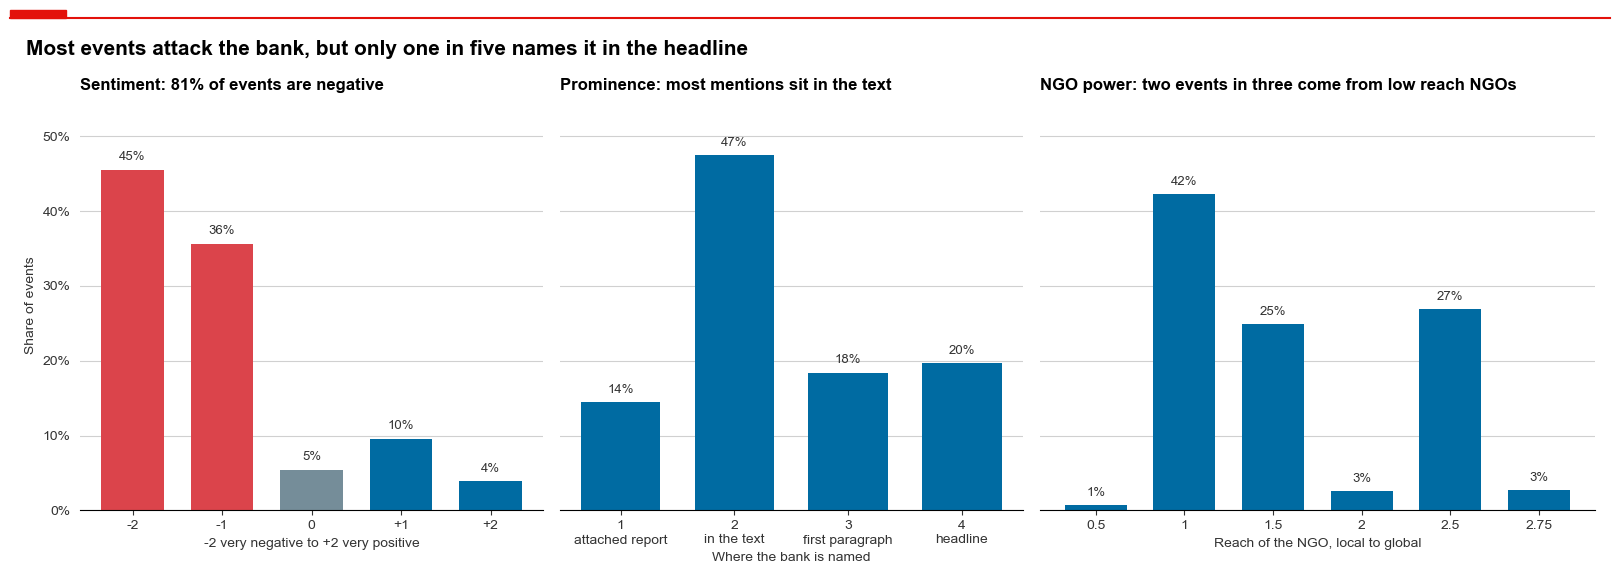

In [526]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True,
                         gridspec_kw={"width_ratios": [1, 1, 1.2]})

share_bars(axes[0], sentiment_shares, sentiment_labels, sentiment_colors,
           f"Sentiment: {negative_share_all:.0%} of events are negative",
           "-2 very negative to +2 very positive")
share_bars(axes[1], prominence_shares, prominence_labels, ECONOMIST_COLORS[0],
           "Prominence: most mentions sit in the text",
           "Where the bank is named")
share_bars(axes[2], power_shares, power_labels, ECONOMIST_COLORS[0],
           "NGO power: two events in three come from low reach NGOs",
           "Reach of the NGO, local to global")

axes[0].set_ylabel("Share of events")
show("Most events attack the bank, but only one in five names it "
     "in the headline")

**Comments – D1.4**
* **2,631 events:** 2,134 negative (81.1%), 354 positive (13.5%), 143 neutral (5.4%), on 882 days and 64 banks. Krüger (2015) has 1,542 negative and 574 positive events, so our comparison group is thinner.

* **335 NGOs lead an event, 516 take part in one:** 35.4% of events involve several NGOs.

* **Sentiment** (left) is mostly hostile, and the harshest level is the most common one.

* **Prominence** (middle): only 19.7% of events name the bank in the headline, and 47% name it somewhere in the text. Negative events reach the headline more often (21.4%) than positive ones (13.3%). So many events may be small news for investors, which is why we test headline mentions apart in Task #6.

* **NGO power** (right) uses the fixed value per NGO. About two events in three come from NGOs of reach 1.5 or less.

### D1.5 Campaigns over time
If Sigwatch tracks more NGOs over time, a rising count alone could just be better coverage. We therefore also look at banks as a share of all Sigwatch rows. First, the labels themselves: are they coded the same way every year?

In [527]:
per_year = events.groupby(["year", "sign"]).size().unstack(fill_value=0)
per_year = per_year[["negative", "neutral", "positive"]]

# All of Sigwatch, because a change of method would hit every sector
neutral_share = (raw["sentiment"] == 0).groupby(row_year).mean()

negative_rows = raw[raw["sentiment"] < 0]
is_harshest = negative_rows["sentiment"] == -2
harshest_share = is_harshest.groupby(negative_rows["date"].dt.year).mean()

coding = pd.DataFrame({
    "neutral rows, all Sigwatch": neutral_share,
    "-2 among negative rows, all Sigwatch": harshest_share,
    "neutral events on banks": per_year["neutral"],
}).rename_axis("year")

coding.style.format({
    "neutral rows, all Sigwatch": "{:.1%}",
    "-2 among negative rows, all Sigwatch": "{:.0%}",
})

,"neutral rows, all Sigwatch","-2 among negative rows, all Sigwatch",neutral events on banks
year,,,
2010,5.1%,23%,12
2011,5.2%,63%,17
2012,7.4%,68%,20
2013,8.0%,64%,20
2014,7.7%,61%,20
2015,7.6%,52%,46
2016,1.9%,58%,3
2017,2.1%,66%,4
2018,2.3%,59%,1


The dashed lines mark the two dates of Task #6. Bars stand in the middle of their year, so a line falls at its true place on the axis.

In [528]:
COP21 = pd.Timestamp("2015-12-12")  # Paris Agreement adopted
TRUMP = pd.Timestamp("2016-11-08")  # US presidential election
EVENT_DATES = [(COP21, "COP21, Dec 2015", "right"),
               (TRUMP, "Trump election, Nov 2016", "left")]


def in_years(date):
    '''Turn a date into a position on an axis counted in years.'''
    return date.year + (date.dayofyear - 1) / 365


def event_lines(ax):
    '''Draw dashed lines for COP21 and the Trump election, with labels.'''
    top = ax.get_ylim()[1]
    for date, label, side in EVENT_DATES:
        position = in_years(date)
        shift = -5 if side == "right" else 5
        ax.axvline(position, color=DARK, ls="--", lw=1)
        annotate(ax, label, (position, top), offset=(shift, -8), ha=side,
                 va="top", bbox=WHITE_BOX)

In [529]:
def stacked_year_bars(ax, table, colors, labels):
    '''Stack the columns of a yearly table, with one bar per year.'''
    bottom = np.zeros(len(table))
    for column, color, label in zip(table.columns, colors, labels):
        # + 0.5: bars in the middle of their year, so event lines fit the axis
        ax.bar(table.index + 0.5, table[column], bottom=bottom, width=0.8,
               color=color, label=label)
        bottom += table[column].values

    ax.set_xticks(table.index + 0.5, list(table.index))

In [530]:
def plot_events_per_year(ax, per_year):
    '''Show the events per year, stacked by sign, with the total on top.'''
    totals = per_year.sum(axis=1)
    labels = [sign.capitalize() for sign in per_year.columns]
    stacked_year_bars(ax, per_year, SENTIMENT_COLORS.values(), labels)

    for year, total in totals.items():
        annotate(ax, f"{total:.0f}", (year + 0.5, total), offset=(0, 9))

    ax.set_ylim(0, totals.max() * 1.25)  # room for the labels and the legend
    ax.set_ylabel("Events per year")
    ax.legend(loc="upper left", ncol=3)
    ax.set_title(f"Events on banks: {totals[2015]:.0f} in 2015, "
                 f"{totals[2018]:.0f} in 2018", fontsize=12)
    event_lines(ax)

In [531]:
LOW_YEARS = [2014, 2016, 2018]  # local lows: the label goes under the line


def plot_bank_share(ax, bank_share):
    '''Show the share of banks in all Sigwatch rows, year by year.'''
    ax.plot(bank_share.index + 0.5, bank_share.values,
            color=ECONOMIST_COLORS[0], marker="o")

    for year, share in bank_share.items():
        shift = -12 if year in LOW_YEARS else 11
        annotate(ax, f"{share:.1%}", (year + 0.5, share), offset=(0, shift))

    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, bank_share.max() * 1.3)  # room for the labels
    ax.set_xticks(bank_share.index + 0.5, list(bank_share.index))
    ax.set_ylabel("Share of all Sigwatch rows")
    ax.set_title(f"Banks stay between {bank_share.min():.1%} and "
                 f"{bank_share.max():.1%} of Sigwatch", fontsize=12)
    event_lines(ax)

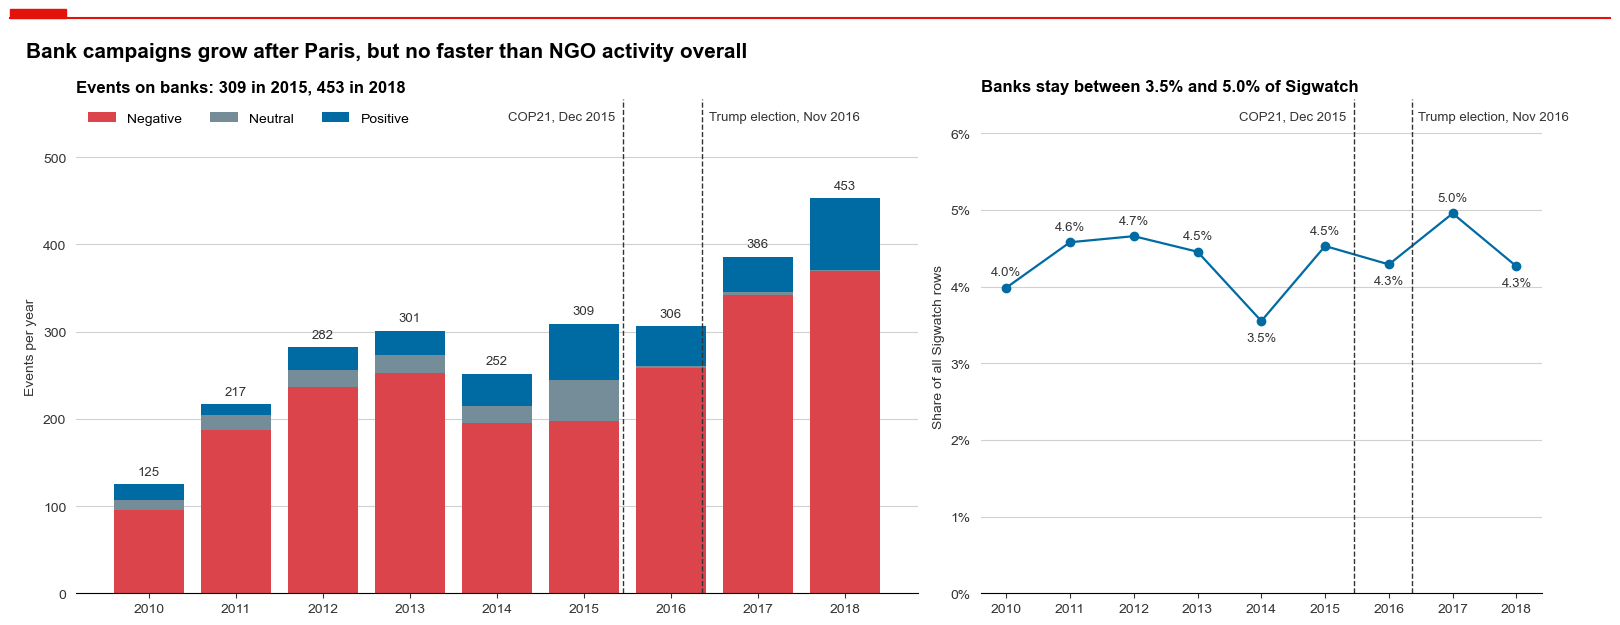

In [532]:
rows_per_year = raw.groupby(row_year).size()
bank_rows_per_year = bank_rows.groupby(bank_rows["date"].dt.year).size()
# Growth that all of Sigwatch shares is no new focus on banks
bank_share = bank_rows_per_year / rows_per_year

fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         gridspec_kw={"width_ratios": [1.5, 1]})
plot_events_per_year(axes[0], per_year)
plot_bank_share(axes[1], bank_share)
show("Bank campaigns grow after Paris, but no faster than NGO activity overall")

**Comments – D1.5**
* **More campaigns, but not more focus on banks:** events grow from 309 in 2015 to 453 in 2018 (left), yet all of Sigwatch grows as fast, from 8,547 to 12,574 rows. Banks stay between 3.5% and 5.0% of its rows (right). So the rise after Paris reflects NGO activity or Sigwatch's coverage overall, not a new target.

* **Sigwatch's coding seems to change in 2016:** neutral rows fall from 7.6% in 2015 to 1.9% in 2016 across all firms, and neutral events on banks from 46 to 3. A fall this sudden across all firms looks like a change of method, not of campaigns.

* **2010 is coded differently too:** only 23% of its negative rows carry −2, against 52% to 68% in later years.

* **Hence the labels are not fully comparable over time, and this is a caveat for Task #6.** A before and after comparison around COP21 could partly pick up the coding, since some events that were neutral before 2016 may now be coded negative or positive. The sign of an event is safer than its exact level, and our rerun without 2010 to 2012 covers the early years.

### D1.6 Banks and NGOs
A few large banks could carry the whole sample, and so could a few NGOs. That matters for Task #6: same day reports and repeat targets make events less independent than their number suggests.

In [533]:
FEW_EVENTS = 3  # at most this many events: a rare target
MANY_EVENTS = 50  # at least this many events: a regular target

events_per_bank = events["bank"].value_counts()
events_per_date = events.groupby("date")["bank"].transform("size")
banks_per_report = events.groupby("uid_archive")["bank"].size()

few_events = (events_per_bank <= FEW_EVENTS).sum()
many_events = (events_per_bank >= MANY_EVENTS).sum()
shared_date = (events_per_date > 1).mean()
shared_report = (banks_per_report > 1).sum()

print("Median events per bank:", int(events_per_bank.median()))
print(f"Banks with {FEW_EVENTS} events or fewer:", few_events)
print(f"Banks with {MANY_EVENTS} events or more:", many_events)
print(f"Events sharing their date with others: {shared_date:.1%}")
print("Most events on one day:", events_per_date.max())
print(f"Reports on several banks: {shared_report} of {len(banks_per_report):,}")

Median events per bank: 15
Banks with 3 events or fewer: 22
Banks with 50 events or more: 18
Events sharing their date with others: 85.8%
Most events on one day: 21
Reports on several banks: 541 of 1,139


Now the largest targets, year by year.

In [534]:
TOP_BANKS = 20  # banks in the heatmap
years = list(per_year.index)

top_banks = events_per_bank.head(TOP_BANKS).index
top_events = events[events["bank"].isin(top_banks)]
top_share = len(top_events) / len(events)

per_bank_year = top_events.groupby(["bank", "year"]).size().unstack()
# Reindex keeps the years without an event, as white cells
per_bank_year = per_bank_year.reindex(index=top_banks, columns=years)

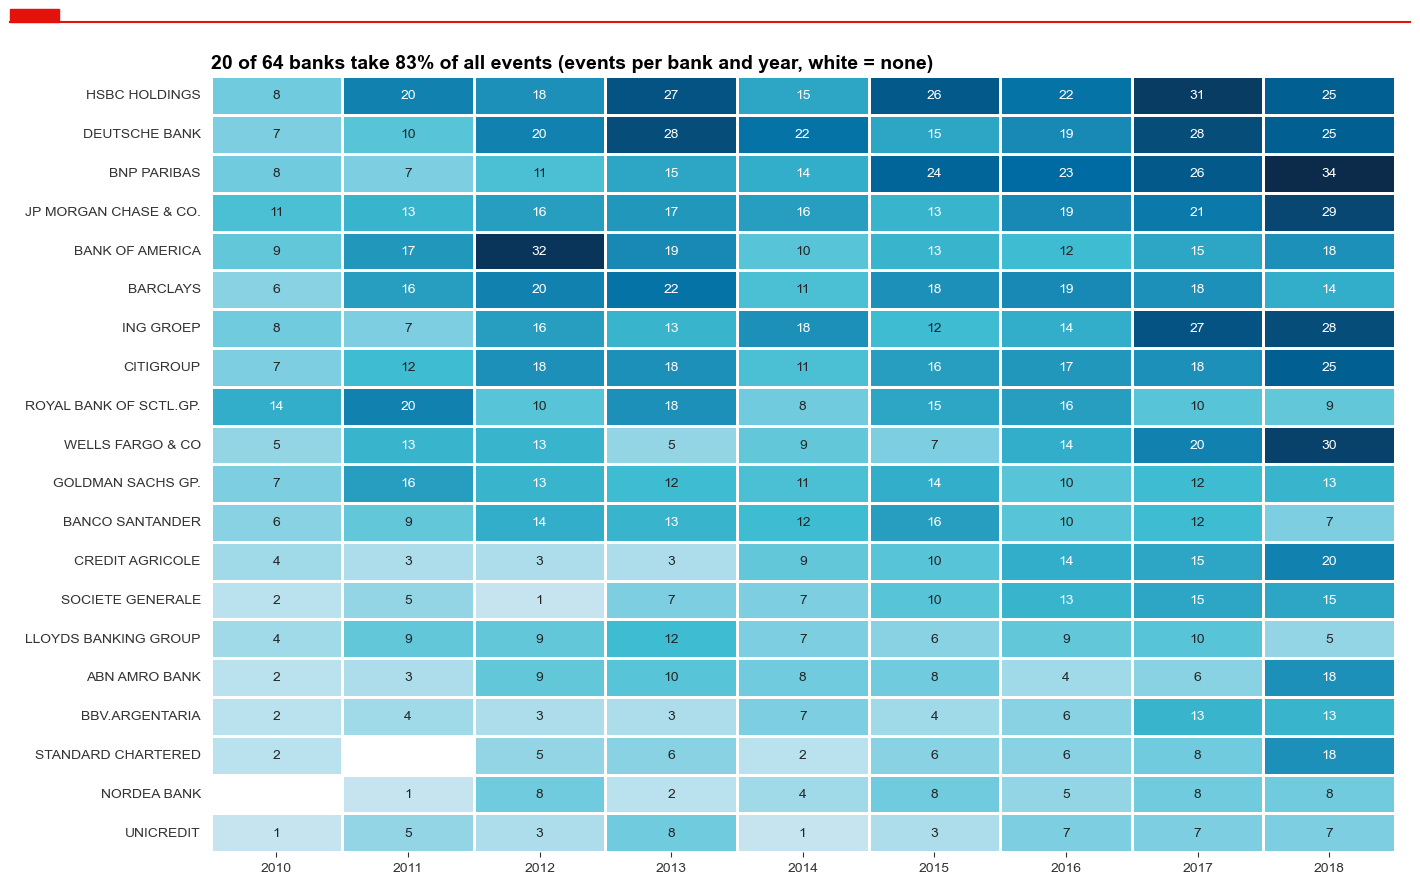

In [535]:
fig, ax = plt.subplots(figsize=(14, 8.5))
sns.heatmap(per_bank_year, annot=True, fmt=".0f", cmap=ECONOMIST_BLUES,
            linewidths=1, cbar=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"{TOP_BANKS} of {len(events_per_bank)} banks take "
             f"{top_share:.0%} of all events "
             "(events per bank and year, white = none)")
ax.grid(False)
show()

The same question for the NGOs. We drop former names from the labels, such as "(formerly World Development Movement)".

In [536]:
TOP_NGOS = 15  # NGOs in the chart
# Former names only lengthen the labels
FORMER_NAME = r" \((?:formerly|previously).*\)"

short_names = events["ngo"].str.replace(FORMER_NAME, "", regex=True)
ngo_counts = short_names.value_counts()
top_ngos = ngo_counts.head(TOP_NGOS).sort_values()
cumulative_share = ngo_counts.cumsum().values / len(events)

In [537]:
def plot_top_ngos(ax, top_ngos):
    '''Show the events led by the most active NGOs.'''
    ax.barh(top_ngos.index, top_ngos.values, color=ECONOMIST_COLORS[0],
            height=0.7)
    for ngo, count in top_ngos.items():
        annotate(ax, f"{count}", (count, ngo), offset=(5, 0), bbox=WHITE_BOX)

    vertical_grid(ax)
    ax.set_xlabel("Events led")
    ax.set_title("Climate and consumer groups lead the list", fontsize=12)

In [538]:
TOP_RANKS = [10, 50]  # ranks marked on the curve


def plot_concentration(ax, cumulative_share):
    '''Show the share of events brought by the top NGOs.'''
    ranks = range(1, len(cumulative_share) + 1)
    ax.plot(ranks, cumulative_share, color=ECONOMIST_COLORS[0], lw=2)

    for rank in TOP_RANKS:
        share = cumulative_share[rank - 1]
        ax.scatter(rank, share, color=ECONOMIST_COLORS[3], edgecolors="black",
                   zorder=3)
        annotate(ax, f"top {rank}: {share:.0%}", (rank, share), offset=(9, -9))

    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("NGOs, ranked by events")
    ax.set_ylabel("Cumulative share of all events")
    top_share = cumulative_share[TOP_RANKS[0] - 1]
    ax.set_title(f"Ten of {len(cumulative_share)} lead NGOs bring "
                 f"{top_share:.0%} of the events", fontsize=12)

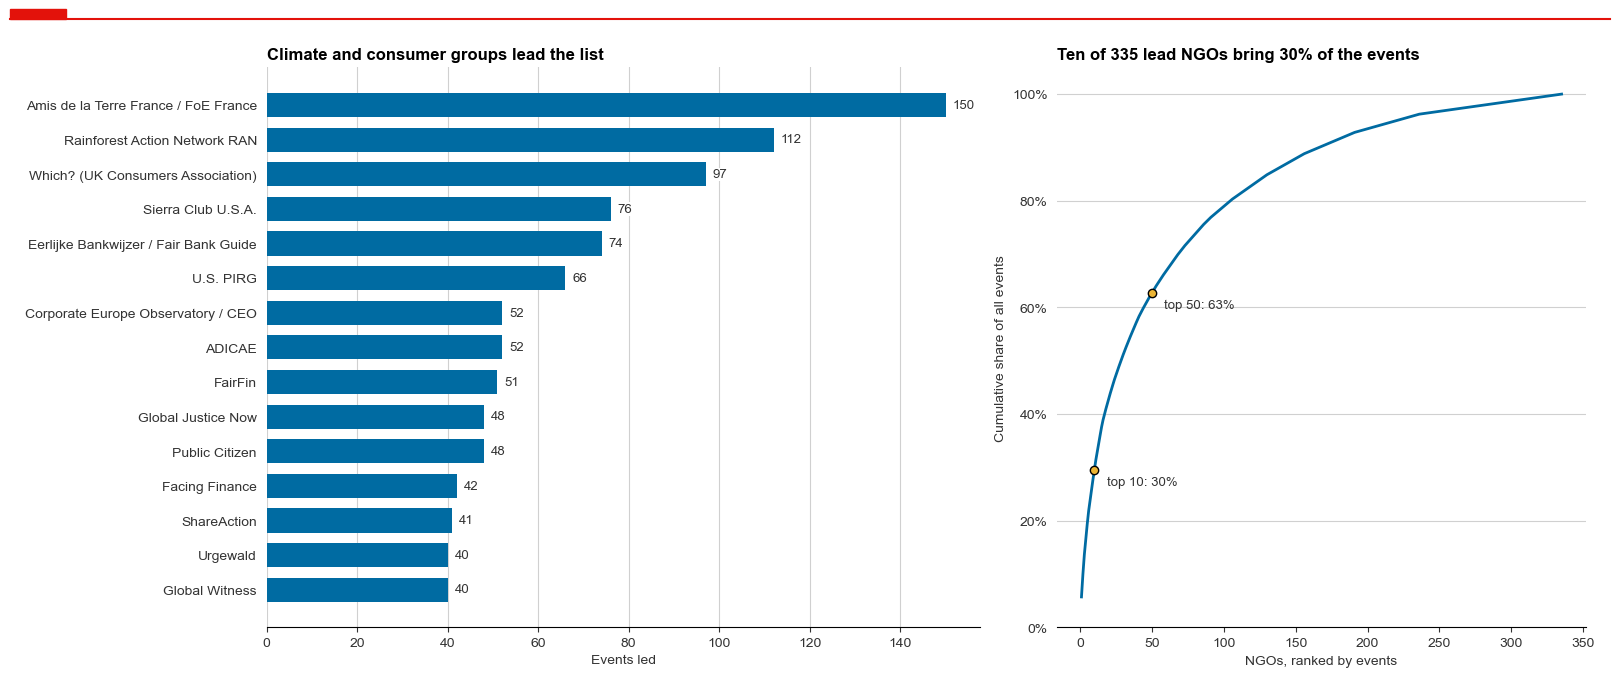

In [539]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5),
                         gridspec_kw={"width_ratios": [1.35, 1]})
plot_top_ngos(axes[0], top_ngos)
plot_concentration(axes[1], cumulative_share)
show()

**Comments – D1.6**
* **A few banks carry the sample:** 20 of 64 banks take 83% of the events. The median bank has 15 events, 22 banks have 3 or fewer, 18 have 50 or more.

* **The large banks are hit every year:** the top 20 show only two empty cells. Some targets shift, for example Wells Fargo with 7 events in 2015 and 30 in 2018.

* **Two kinds of NGOs lead:** climate groups (Friends of the Earth France 150, Rainforest Action Network 112) and consumer groups.

* **Activity is concentrated:** ten of 335 lead NGOs bring 30% of the events, fifty bring 63%.

* **Events are far from independent:** 85.8% share their date with another event, with up to 21 on one day, and 541 of 1,139 reports name more than one bank. On such days the banks' returns may well move together. **So in Task #6 we cluster our standard errors by event date,** which lets the errors of one date move together.

### D1.7 Issues
Our issue groups come from Sigwatch's own labels. Task #6 compares climate with the rest, so we check that the groups are large enough and how they move around COP21.

In [540]:
GROUP_ORDER = [*ISSUE_GROUPS, "Other"]
# One colour per issue in every chart
GROUP_COLORS = dict(zip(GROUP_ORDER, [
    ECONOMIST_COLORS[2], ECONOMIST_COLORS[3], ECONOMIST_COLORS[1],
    ECONOMIST_COLORS[5], LIGHT_GREY,
]))

In [541]:
is_climate = events["issue_group"] == GROUP_ORDER[0]
after_cop21 = events["date"] > COP21
climate_before = is_climate[~after_cop21].mean()
climate_after = is_climate[after_cop21].mean()

is_other = events["issue_group"] == "Other"
other_labels = events.loc[is_other, "issue_name1"].value_counts()

print(f"Climate share up to COP21: {climate_before:.1%}")
print(f"Climate share after COP21: {climate_after:.1%}")
print(other_labels.head(4).to_string())

Climate share up to COP21: 37.5%
Climate share after COP21: 55.5%
issue_name1
CSR/ESG standards for financial institutions    177
Regulation of financial institutions             87
Ethical investing/SRI                            29
CSR standards and reporting                      24


The left panel gives the size of each group, the right panel its share per year.

In [542]:
def plot_group_sizes(ax, events):
    '''Show the events per issue group, with share and negative share.'''
    counts = events["issue_group"].value_counts()
    counts = counts.reindex(GROUP_ORDER[::-1])  # barh starts at the bottom
    is_negative = events["sentiment"] < 0
    negative_share = is_negative.groupby(events["issue_group"]).mean()

    ax.barh(counts.index, counts.values, height=0.7,
            color=[GROUP_COLORS[group] for group in counts.index])
    for group, count in counts.items():
        share = count / len(events)
        negative = negative_share[group]
        label = f"{count:,}  ({share:.0%}, {negative:.0%} negative)"
        annotate(ax, label, (count, group), offset=(5, 0), bbox=WHITE_BOX)

    ax.set_xlim(0, counts.max() * 1.55)  # room for the labels
    vertical_grid(ax)
    ax.set_xlabel("Events")
    ax.set_title("Climate is the largest issue, Other is a quarter",
                 fontsize=12)

In [543]:
def plot_group_shares(ax, events):
    '''Show the share of each issue group per year.'''
    counts = events.groupby(["year", "issue_group"]).size()
    per_year = counts.unstack(fill_value=0)[GROUP_ORDER]
    shares = per_year.div(per_year.sum(axis=1), axis=0)

    colors = [GROUP_COLORS[group] for group in GROUP_ORDER]
    stacked_year_bars(ax, shares, colors, GROUP_ORDER)

    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylabel("Share of the year's events")
    ax.set_ylim(0, 1.1)  # room for the labels of the event lines
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title(f"Climate: {climate_before:.0%} of events up to COP21, "
                 f"{climate_after:.0%} after", fontsize=12)
    event_lines(ax)

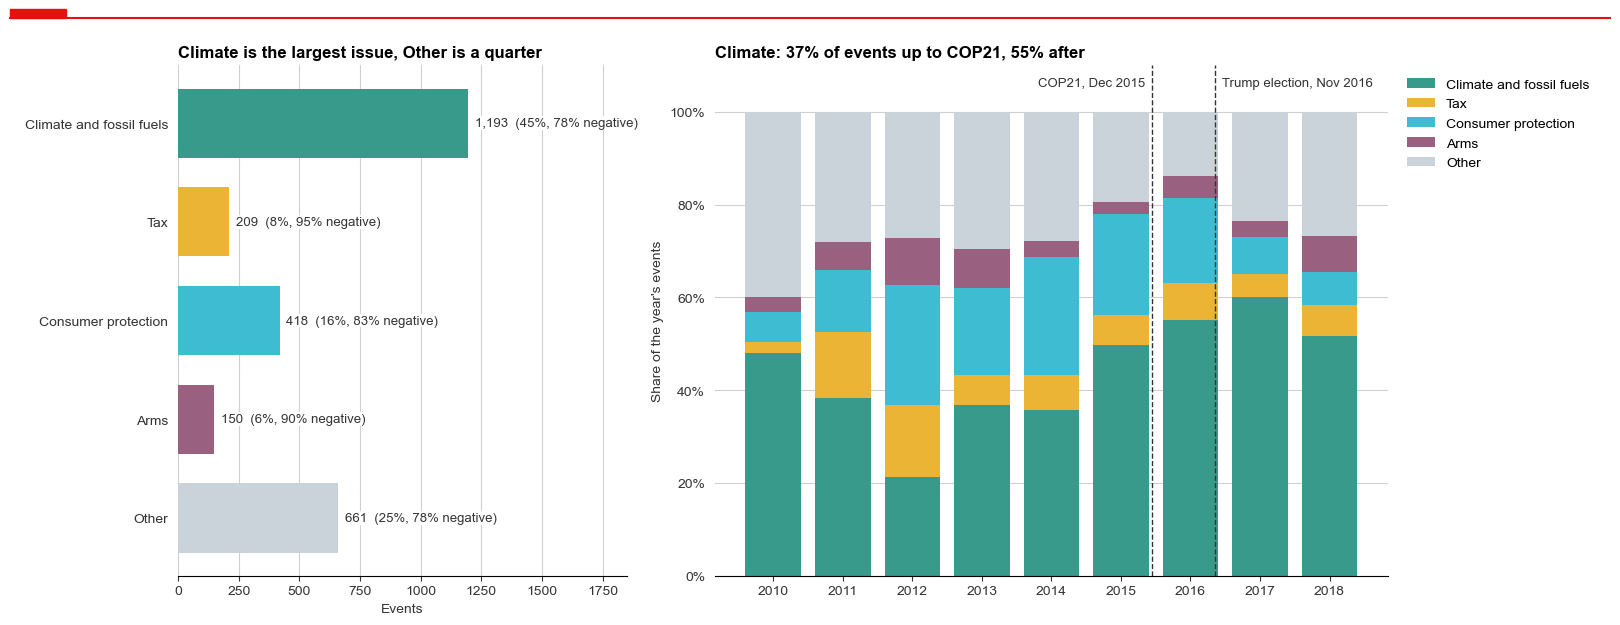

In [544]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         gridspec_kw={"width_ratios": [1, 1.5]})
plot_group_sizes(axes[0], events)
plot_group_shares(axes[1], events)
show()

**Comments – D1.7**
* **The groups are large enough to test:** climate 1,193 events (45%), consumer protection 418 (16%), tax 209 (8%), arms 150 (6%).

* **Other is a quarter of the events (661):** led by general labels such as CSR/ESG standards (177) and regulation (87).

* **Climate gains weight, but COP21 is no clean break** (right): its share is 37.5% up to COP21 and 55.5% after. Yet it was already about 48% in 2010 and 50% in 2015, and it falls back to about 52% in 2018. So we write "after COP21", never "because of COP21".

* **Our climate group is wide on purpose:** it uses the keywords of the do file, so it also holds mining, logging and palm oil.

* **Tax is almost pure attack** (95% negative), climate less so (78%).

### D1.8 Countries
Country means the country of the parent. The size of each group sets how much our robustness check on US banks can show in Task #6.

In [545]:
# Order of all regional tables
REGION_ORDER = ["US", "UK", "Euro area", "Sweden"]

is_us_uk = events["country_group"].isin(["US", "UK"])
us_uk_share = is_us_uk.mean()

is_positive = events["sentiment"] > 0
positive_share = is_positive.groupby(events["country_group"]).mean()
print(positive_share[REGION_ORDER].map("{:.1%}".format).to_string())

country_group
US            9.5%
UK           12.0%
Euro area    15.6%
Sweden       25.2%


In [546]:
def plot_countries(ax, events):
    '''Show the events per country, with the number of banks.'''
    counts = events["country"].value_counts().sort_values()
    banks = events.groupby("country")["bank"].nunique()

    ax.barh(counts.index, counts.values, color=ECONOMIST_COLORS[0], height=0.7)
    for country, count in counts.items():
        label = f"{count}  (banks: {banks[country]})"
        annotate(ax, label, (count, country), offset=(5, 0), bbox=WHITE_BOX)

    ax.set_xlim(0, counts.max() * 1.25)  # room for the labels
    vertical_grid(ax)
    ax.set_xlabel("Events")
    ax.set_title(f"US and UK banks take {us_uk_share:.0%} of the events",
                 fontsize=12)

In [547]:
def plot_region_mix(ax, events):
    '''Show the issue mix of each region as stacked shares.'''
    # Shares within a region, so regions of any size compare
    mix = pd.crosstab(events["country_group"], events["issue_group"],
                      normalize="index")
    mix = mix.reindex(index=REGION_ORDER[::-1], columns=GROUP_ORDER)

    left = np.zeros(len(mix))
    for group in GROUP_ORDER:
        ax.barh(mix.index, mix[group], left=left, height=0.7,
                color=GROUP_COLORS[group], label=group)
        left += mix[group].values

    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    vertical_grid(ax)
    ax.set_xlabel("Share of the region's events")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
    ax.set_title("Climate leads everywhere except Sweden", fontsize=12)

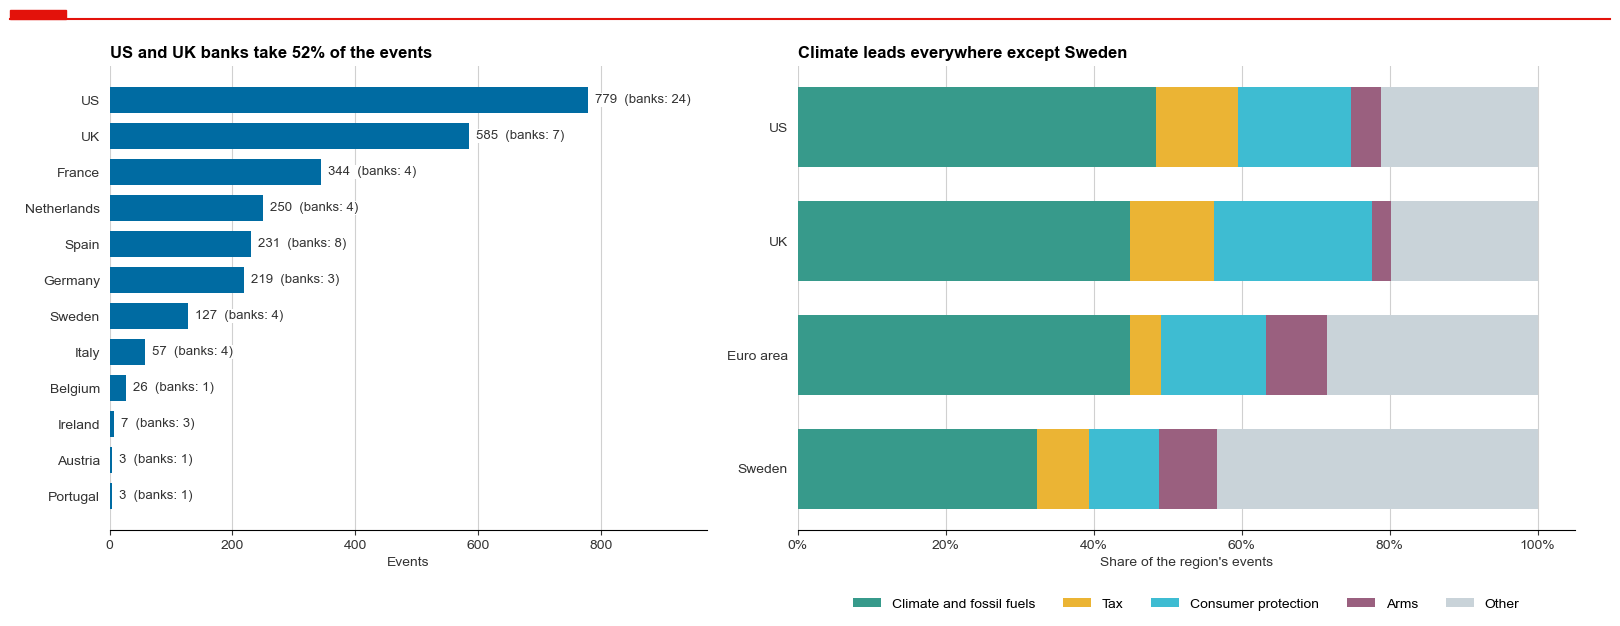

In [548]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         gridspec_kw={"width_ratios": [1, 1.3]})
plot_countries(axes[0], events)
plot_region_mix(axes[1], events)
show()

**Comments – D1.8**
* **The US and the UK take 52% of the events** (left): 779 on 24 US banks, 585 on just 7 UK banks. France has 344 on 4 banks and Germany 219 on 3.

* **So our check on US banks in Task #6 keeps a large sample,** and it has no currency issue.
* **Small countries add little:** Ireland 7, Austria 3, Portugal 3.

* **Climate leads everywhere except Sweden** (right), where general labels are the largest group. The UK stands out with consumer protection, the Euro area with arms.

* **Praise is more common on the Continent:** positive events are 9.5% in the US, 12.0% in the UK, 15.6% in the Euro area and 25.2% in Sweden.

Finally, the table that we use in Task #5.

In [549]:
SHOWN_COLUMNS = ["bank", "date", "ngo", "sentiment", "prominence", "ngo_power",
                 "n_ngos", "issue_group"]
events[SHOWN_COLUMNS].sample(5, random_state=SEED)

,bank,date,ngo,sentiment,prominence,ngo_power,n_ngos,issue_group
221,JP MORGAN CHASE & CO.,2011-05-26,Global Witness,-2,4,2.5000,1,Other
318,SOCIETE GENERALE,2011-11-30,groundWork / FoE South Africa,-1,2,2.5000,3,Climate and fossil fuels
926,CITIGROUP,2014-01-02,WWF Russia,1,4,2.5000,1,Other
1355,BARCLAYS,2015-07-27,Which? (UK Consumers Association),-1,2,1.0000,1,Consumer protection
1421,DEUTSCHE BANK,2015-10-23,Urgewald,-2,4,1.0000,1,Climate and fossil fuels


**Result of Day 1.** `events` holds 2,631 events, one per bank and day, on 64 banks, with sentiment, prominence, fixed NGO power, the number of NGOs, the issue group and the flag of the 5 day rule. Its `bank` column uses the Datastream names, so in Task #5 we can merge it directly with the panel of Day 2. Some events will still drop out there, for instance when a bank was listed too late for a full estimation window, the days before an event from which we estimate its normal return.

## Optional Task #3 – Sentiment analysis of campaigns
Sigwatch staff give every event a tone from −2 to +2. Can a model do better? We score the `report` summary of each event with the two transformers of PC Lab #3: FinBERT, trained on financial news, and Twitter-RoBERTa, trained on tweets. The score of a text is P(positive) − P(negative), from −1 to +1. The slide suggests the NGO pages behind the links of the Sigwatch files. We did not test these links, so we use the summaries.

Here we ask whether the models agree with Sigwatch. Whether they explain price reactions better is a question for Task #6, once we have the cumulative abnormal returns (CARs): what a bank earns beyond its normal return around an event.

In [ ]:
try:    # only needed for this task: the core of the notebook runs without them
    import torch
    from transformers import AutoTokenizer
    from transformers import AutoModelForSequenceClassification
    from transformers.utils import logging as hf_logging
except ImportError:
    torch = None

HAS_MODELS = torch is not None
if HAS_MODELS:
    hf_logging.set_verbosity_error()  # hide the model-loading reports
    hf_logging.disable_progress_bar()
    logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
else:
    print("Optional Task #3 is skipped: torch or transformers is missing.")

### 3.1 Clean the reports
The reports hold HTML leftovers and end with the word "See", which stood before the link to the NGO's page in Sigwatch's text. We remove both. The comments of Sigwatch's analysts stay, since they are part of the summary.

In [551]:
LINK_MARKER = r"\s*See(?: \(.*\))?\s*$"  # "See" or "See (in French)" at the end


def clean_reports(reports):
    '''Remove HTML, the link marker and extra spaces from the reports.'''
    texts = reports.str.replace(r"<[^>]+>", " ", regex=True)
    texts = texts.map(html.unescape)  # turns "&amp;" into "&"
    texts = texts.str.replace(r"\s+", " ", regex=True).str.strip()
    return texts.str.replace(LINK_MARKER, "", regex=True)


events["text"] = clean_reports(events["report"])

Two things can weaken a score. Some texts are almost empty, and some start in the middle of a sentence, so the opening of the report is lost.

In [552]:
MIN_CHARACTERS = 20  # shorter texts hold no content to score
MID_SENTENCE = r"[a-z,;.)]"  # a report that starts like this lost its opening

# One report can sit on several events, and we count each text once
unique_texts = events["text"].drop_duplicates()
is_short = unique_texts.str.len() < MIN_CHARACTERS
is_fragment = unique_texts.str.match(MID_SENTENCE)
word_counts = unique_texts.str.split().str.len()

print(f"Different texts: {len(unique_texts):,} for {len(events):,} events")
print(f"Median words: {word_counts.median():.0f}")
print(f"Texts below {MIN_CHARACTERS} characters: {is_short.sum()}")
print(f"Texts starting in mid sentence: {is_fragment.mean():.0%}")

Different texts: 1,106 for 2,631 events
Median words: 62
Texts below 20 characters: 22
Texts starting in mid sentence: 64%


One report often names several banks, and Sigwatch gives each its own label, while a model sees one text. How often do the labels differ inside one report?

In [553]:
# One text carries one label per bank, and these can differ
labels_per_report = events.groupby("uid_archive")["sentiment"].nunique()
signs_per_report = events.groupby("uid_archive")["sign"].nunique()
banks_per_report = events.groupby("uid_archive")["bank"].nunique()

print(f"Reports on several banks: {(banks_per_report > 1).sum()}")
print(f"Reports with different labels: {(labels_per_report > 1).sum()}")
print(f"Reports with different signs: {(signs_per_report > 1).sum()}")

Reports on several banks: 541
Reports with different labels: 157
Reports with different signs: 123


**Comments – 3.1**
* **The summaries are short:** 1,106 different texts for 2,631 events, with a median of 62 words.

* **The text is weaker than it looks:** 22 texts hold almost nothing, and 64% start in mid sentence, so their opening is lost. We cannot repair this from the summaries. The Sigwatch files hold links to the NGO pages (`link1` to `link5`), but we did not test them, and many pages would need translation.

* **A label belongs to a bank, but a text belongs to a report:** 541 reports name several of our banks. In 157 of them the labels differ, and in 123 even the sign. On those reports no model can match Sigwatch, however good it is.

### 3.2 Score the reports
We reuse the scoring function of PC Lab #3. Reports are longer than tweets, so we read up to 512 tokens, the limit of both models, instead of 128. No report is longer than that. Each different text is scored once.

In [743]:
# Hugging Face names of the two models
MODELS = {"finbert": "ProsusAI/finbert",
          "roberta": "cardiffnlp/twitter-roberta-base-sentiment-latest"}
MODEL_NAMES = {"finbert": "FinBERT", "roberta": "Twitter-RoBERTa"}
SCORE_COLUMNS = ["finbert_score", "roberta_score"]
MAX_TOKENS = 512  # the limit of both models
BATCH_SIZE = 32  # texts per step

# Use a GPU if there is one: NVIDIA (CUDA) or Apple (MPS), else the CPU
DEVICE = "cpu"
if HAS_MODELS and torch.cuda.is_available():
    DEVICE = "cuda"
elif HAS_MODELS and torch.backends.mps.is_available():
    DEVICE = "mps"
print("Device:", DEVICE)

Device: mps


In [555]:
def score_batch(texts, tokenizer, model):
    '''Compute the class probabilities of one batch of texts.'''
    tokens = tokenizer(texts, padding=True, truncation=True,
                       max_length=MAX_TOKENS, return_tensors="pt")
    logits = model(**tokens.to(DEVICE)).logits
    return logits.softmax(dim=-1).cpu().numpy()


def sentiment_probabilities(texts, model_name):
    '''Compute P(negative), P(neutral) and P(positive) for every text.'''
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name)
    model = model.to(DEVICE).eval()

    order = np.argsort(texts.str.len().values)  # similar lengths, less padding
    probabilities = np.zeros((len(texts), model.config.num_labels))
    with torch.inference_mode():
        for start in range(0, len(texts), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            batch_texts = list(texts.iloc[batch])
            probabilities[batch] = score_batch(batch_texts, tokenizer, model)

    # The models order their classes differently, so we read the names
    id_to_label = model.config.id2label
    labels = [id_to_label[i].lower() for i in range(len(id_to_label))]
    return pd.DataFrame(probabilities, index=texts.index, columns=labels)

In [556]:
if HAS_MODELS:
    # An almost empty text would get a score from nothing
    scorable_texts = unique_texts[~is_short]
    scores = pd.DataFrame({"text": scorable_texts})

    for key, model_name in MODELS.items():
        probabilities = sentiment_probabilities(scorable_texts, model_name)
        # From -1 to +1
        score = probabilities["positive"] - probabilities["negative"]
        scores[f"{key}_score"] = score
        print(f"{MODEL_NAMES[key]}: mean {score.mean():+.2f}, "
              f"std {score.std():.2f}")

    scores = scores.set_index("text")
    events = events.join(scores, on="text")

FinBERT: mean -0.30, std 0.50
Twitter-RoBERTa: mean -0.22, std 0.32


In [557]:
if HAS_MODELS:
    no_score = events["finbert_score"].isna().sum()
    model_correlation = scores["finbert_score"].corr(scores["roberta_score"])

    print(f"Events without a score: {no_score} of {len(events):,}")
    print(f"Correlation between the models: {model_correlation:.2f}")

Events without a score: 103 of 2,631
Correlation between the models: 0.64


**Comments – 3.2**
* **Both models read the reports as negative:** the mean score is −0.30 for FinBERT and −0.22 for Twitter-RoBERTa. NGO reports describe problems, even when they praise a bank.

* **The two models agree only in part:** their correlation is 0.64, and FinBERT is the more extreme (standard deviation 0.50 against 0.32). FinBERT measures financial tone, so a report attacking a coal project may read as negative for the project, not for the bank.

* **103 events have no score,** because of the 22 almost empty texts. They keep their Sigwatch label and stay out of this comparison.

* **`events` now holds both scores,** so Task #6 can compare them with the Sigwatch label.

### 3.3 Do the models agree with Sigwatch?
A report that names three banks with the same label would count three times with the same text. So one report counts once per label. We use the Spearman rank correlation, because the label is ordered, but its steps are not equal distances.

In [558]:
def spearman_with_label(table, column):
    '''Compute the rank correlation of a score with the Sigwatch label.'''
    return table["sentiment"].corr(table[column], method="spearman")


if HAS_MODELS:
    rated = events.dropna(subset=SCORE_COLUMNS)
    # One report counts once per label, so a shared text is not counted twice
    rated = rated.drop_duplicates(["uid_archive", "sentiment"])

We also test our two suspects: texts that lost their opening, and reports on several banks. The two periods show whether the coding change of 2016 matters here.

In [559]:
if HAS_MODELS:
    has_opening = ~rated["text"].str.match(MID_SENTENCE)
    one_bank = rated["uid_archive"].map(banks_per_report) == 1

    subsets = {
        "all reports": rated,
        "opening intact": rated[has_opening],
        "mid sentence": rated[~has_opening],
        "one of our banks only": rated[one_bank],
        # The coding of Sigwatch changes in 2016 (D1.5)
        "up to 2015": rated[rated["year"] <= 2015],
        "from 2016": rated[rated["year"] >= 2016],
    }

    rows = []
    for name, subset in subsets.items():
        rows.append({
            "FinBERT": spearman_with_label(subset, "finbert_score"),
            "Twitter-RoBERTa": spearman_with_label(subset, "roberta_score"),
            "reports": len(subset),
        })

    agreement = pd.DataFrame(rows, index=subsets)
    table = agreement.style.format({"FinBERT": "{:.2f}",
                                    "Twitter-RoBERTa": "{:.2f}",
                                    "reports": "{:,}"})
    display(table)

,FinBERT,Twitter-RoBERTa,reports
all reports,0.10,0.17,"1,267"
opening intact,0.15,0.23,464
mid sentence,0.09,0.14,803
one of our banks only,0.15,0.22,563
up to 2015,0.06,0.14,784
from 2016,0.15,0.20,483


Spearman uses ranks only, so it checks whether the order matches, not how strongly the scores differ. With only five label values most reports share a rank, and ties get the average rank. The chart of mean scores per level shows the size of the differences.

In [560]:
def mean_with_interval(rated, column):
    '''Compute the mean score per label level, with its 95% half width.'''
    levels = rated.groupby("sentiment")[column].agg(["mean", "std", "count"])
    levels["half_width"] = Z_95 * levels["std"] / np.sqrt(levels["count"])
    return levels


def plot_levels(ax, levels, shift, color, label):
    '''Draw the mean score per level as dots with 95% intervals.'''
    ax.errorbar(levels.index + shift, levels["mean"], yerr=levels["half_width"],
                fmt="o", color=color, ecolor=color, capsize=4, ms=8,
                label=label)
    for level, row in levels.iterrows():
        annotate(ax, f"{row['mean']:+.2f}", (level + shift, row["mean"]),
                 offset=(10 if shift > 0 else -10, 0))

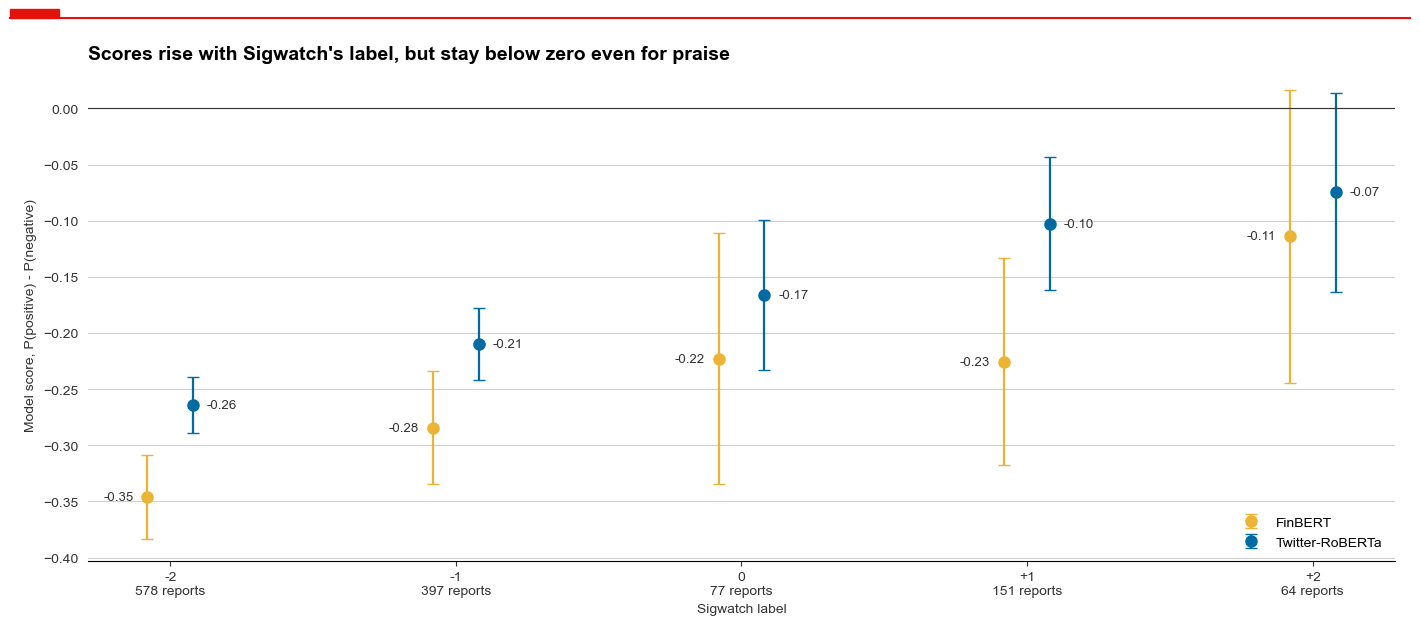

In [561]:
if HAS_MODELS:
    finbert_levels = mean_with_interval(rated, "finbert_score")
    roberta_levels = mean_with_interval(rated, "roberta_score")

    level_ticks = []
    for level, count in finbert_levels["count"].items():
        label = "0" if level == 0 else f"{level:+d}"
        level_ticks.append(f"{label}\n{count:,} reports")

    fig, ax = plt.subplots(figsize=(14, 6))
    # Small shifts, so that the intervals of the two models do not overlap
    plot_levels(ax, finbert_levels, -0.08, ECONOMIST_COLORS[3], "FinBERT")
    plot_levels(ax, roberta_levels, 0.08, ECONOMIST_COLORS[0],
                "Twitter-RoBERTa")
    ax.axhline(0, color=DARK, lw=0.8)
    ax.set_xticks(finbert_levels.index, level_ticks)
    ax.set_xlabel("Sigwatch label")
    ax.set_ylabel("Model score, P(positive) - P(negative)")
    ax.legend(loc="lower right")
    ax.set_title("Scores rise with Sigwatch's label, but stay below zero even "
                 "for praise")
    show()

The averages hide how much the texts overlap, so we compare the whole distribution of scores for negative and positive reports.

In [562]:
SCORE_BINS = np.linspace(-1, 1, 21)  # bins of 0.1


def plot_overlap(ax, rated, column, title):
    '''Compare the scores of negative and positive reports.'''
    for sign in ["negative", "positive"]:
        scores_of_sign = rated.loc[rated["sign"] == sign, column]
        ax.hist(scores_of_sign, bins=SCORE_BINS, density=True, alpha=0.6,
                color=SENTIMENT_COLORS[sign], label=sign.capitalize())
    ax.set_xlabel("Model score")
    ax.set_title(title, fontsize=12)

In [563]:
if HAS_MODELS:
    negative_rated = rated[rated["sign"] == "negative"]
    positive_rated = rated[rated["sign"] == "positive"]

    for column, name in zip(SCORE_COLUMNS, MODEL_NAMES.values()):
        negative_above = (negative_rated[column] > 0).mean()
        positive_below = (positive_rated[column] < 0).mean()
        print(f"{name}: {negative_above:.0%} of negative reports score above "
              f"zero, {positive_below:.0%} of positive reports below")

FinBERT: 29% of negative reports score above zero, 60% of positive reports below
Twitter-RoBERTa: 24% of negative reports score above zero, 60% of positive reports below


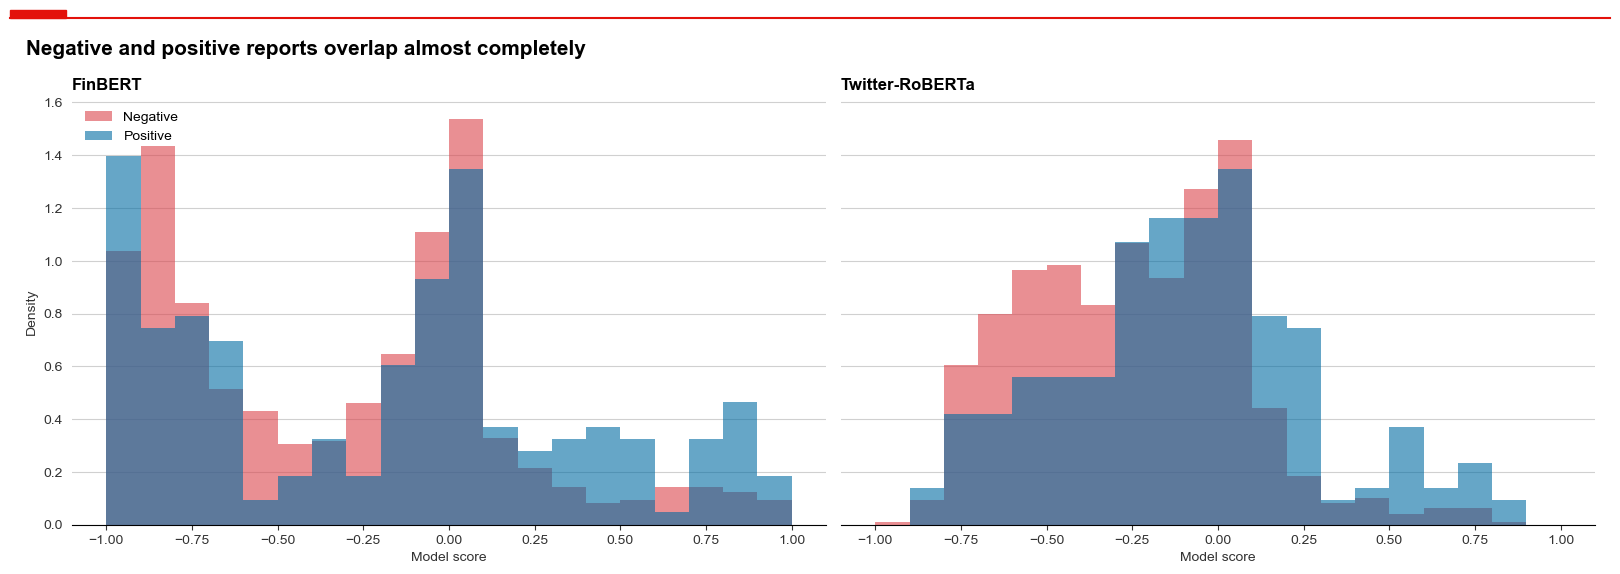

In [564]:
if HAS_MODELS:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
    plot_overlap(axes[0], rated, "finbert_score", "FinBERT")
    plot_overlap(axes[1], rated, "roberta_score", "Twitter-RoBERTa")
    axes[0].set_ylabel("Density")
    axes[0].legend(loc="upper left")
    show("Negative and positive reports overlap almost completely")

Where label and model disagree most, the texts show why.

In [565]:
EXCERPT = 260  # characters shown of each report

if HAS_MODELS:
    rated_mean = rated.assign(model_score=rated[SCORE_COLUMNS].mean(axis=1))
    harsh = rated_mean[rated_mean["sentiment"] == -2]
    kind = rated_mean[rated_mean["sentiment"] == 2]
    surprises = pd.concat([harsh.nlargest(3, "model_score"),
                           kind.nsmallest(3, "model_score")])

    surprises = surprises[["bank", "sentiment", "model_score", "text"]].copy()
    surprises["text"] = surprises["text"].str[:EXCERPT]
    table = surprises.style.hide(axis="index")
    display(table.format({"model_score": "{:+.2f}"}))

bank,sentiment,model_score,text
DEUTSCHE BANK,-2,+0.84,"), GLS Bank and Triodos again came out best from the NGOs' point of view, while new entries Postbank and HypoVereinsbank (UniCredit Deutschland) came 10th and 7th respectively. Pax-Bank rose from 8th to 4th place, and KD-Bank came 3rd. Fifth-placed Commerzbank"
BNP PARIBAS,-2,+0.75,and even praised some of the steps taken so far by Credit Agricole and EDF.
ABN AMRO BANK,-2,+0.61,"rating for transparency and accountability.The group said, on the other hand, that ASN Bank scored best for transparency in its investments (9), followed by Triodos (8), Van Lanschot (8) and NIBC (7). In terms of asset management, ASN Bank came out top with a"
ING GROEP,2,-0.80,"In Australia, WWF with the financial assistance of ING Direct claimed that the snub finned dolphin, which is unique to Australia, could be extinct in three generations without the legal protection of being listed as a threatened species. The NGO claimed that i"
US BANCORP,2,-0.78,with meaningless audits on practices that are harmful to the environment.
BNP PARIBAS,2,-0.77,"fossil fuel projects, and argued the company's financing of coal, Arctic oil, oil sands and pipelines threatens climate goals and poses financial risks to investors. It cited Wells Fargo's loss of billions of dollars from investments in the Dakota Access pipel"


**Comments – 3.3**
* **Agreement with Sigwatch is weak:** the Spearman correlation is 0.10 for FinBERT and 0.17 for Twitter-RoBERTa on 1,267 reports.

* **Agreement is higher without our two suspects:** it rises to 0.15 and 0.23 when the opening is intact, against 0.09 and 0.14 in mid sentence, and to 0.15 and 0.22 when a report names only one of our banks. We show no intervals here, so we read this as a pattern, not a test.

* **We see no sign that the coding change of 2016 hurt:** agreement is 0.15 and 0.20 from 2016, against 0.06 and 0.14 up to 2015.

* **Scores do rise with the label, but slowly** (first chart): from −0.35 to −0.11 for FinBERT and from −0.26 to −0.07 for Twitter-RoBERTa, which rises at every step. Intervals are wide at +2, with only 64 reports, and the mean stays below zero even there.

* **One report says little:** 60% of positive reports score below zero with either model, and 29% and 24% of negative reports score above it (second chart).

* **In the largest disagreements the models read the topic, not the bank** (table): Deutsche Bank gets −2 from a ranking whose text praises other banks, and the models score it +0.84. ING gets +2 for funding a WWF campaign, but the text is about a dolphin facing extinction, so they score it −0.80.

* **So the model score is not a better label, but a second measure:** the tone of the whole report, where Sigwatch gives the tone towards one bank. Whether it explains price reactions better is the test of Task #6.

## Day 2 – Explore the stock data
Day 1 gave us the events. Now we need the prices of the same banks, from Datastream, so that we can measure how they react. We build one clean table of total return indices: one column per bank, one row per weekday, nothing but banks with usable prices.

### D2.1 Load RI and PI
Datastream gives two series per firm. RI is the total return index, with dividends reinvested. PI is the price index, without them. Every country has its own sheet, and Sweden sits in a separate file. We leave out the Norwegian and Swiss sheets. `banks_info.xlsx` lists the same firms with ISIN and country. We do not need it: the sheet of a series gives its country, and Day 1 matches banks by name.

In [566]:
MAIN_INDEX = "banks_data_bocconi/banks_pi.xlsm"  # PI: the price index
NORDIC_INDEX = "banks_data_bocconi/scandinavian_banks_pi.xlsm"


def load_datastream(main_file, nordic_file, tail):
    '''Join the country sheets of one Datastream series into one table.'''
    sheets = read_sheets(main_file, nordic_file)

    tables = []
    for sheet in sheets.values():
        table = sheet.set_index("Name")
        table.columns = table.columns.str.replace(tail, "", regex=False)
        tables.append(table)
    return pd.concat(tables, axis=1)

In [567]:
ri_raw = load_datastream(MAIN_PRICES, NORDIC_PRICES, RI_TAIL)
pi_raw = load_datastream(MAIN_INDEX, NORDIC_INDEX, " - PRICE INDEX")

print(f"RI: {ri_raw.shape[1]} series, {len(ri_raw):,} days")
print(f"PI: {pi_raw.shape[1]} series, {len(pi_raw):,} days")
print(f"From {ri_raw.index.min():%d %b %Y} to {ri_raw.index.max():%d %b %Y}")
print("Rows without a date in PI:", pi_raw.index.isna().sum())
print("Days on a weekend:", (ri_raw.index.dayofweek > 4).sum())
print("Values of zero or below in RI:", (ri_raw <= 0).sum().sum())

RI: 162 series, 3,363 days
PI: 164 series, 3,363 days
From 01 Jan 2008 to 19 Nov 2020
Rows without a date in PI: 0
Days on a weekend: 0
Values of zero or below in RI: 0


### D2.2 Sample end
Our last event sets the end of the sample. Task #5 needs 10 trading days after it, so we keep prices up to 31 January 2019, which leaves room for the holidays. The later years are not needed, so the COVID-19 crash cannot enter our estimates.

In [568]:
SAMPLE_END = "2019-01-31"  # last event plus 10 trading days and holidays

ri_sample = ri_raw.loc[:SAMPLE_END]
pi_sample = pi_raw.loc[:SAMPLE_END]

print(f"Last event: {events['date'].max():%d %b %Y}")
print(f"Days kept: {len(ri_sample):,} of {len(ri_raw):,}")

Last event: 18 Dec 2018
Days kept: 2,893 of 3,363


### D2.3 Duplicate columns
When a sheet holds the same name twice, pandas adds `.1` to the second column. We check that such columns are true copies, and we look for copies under another name by comparing the values.

In [569]:
def find_copies(table):
    '''Find the columns that pandas marked as a repeated name.'''
    return [name for name in table.columns if name.endswith(".1")]


for table in [ri_sample, pi_sample]:
    for copy in find_copies(table):
        original = copy.removesuffix(".1")
        print(copy, "same as original:", table[copy].equals(table[original]))

ri_unique = ri_sample.drop(columns=find_copies(ri_sample))

# Check: a second method, by content, finds no other copy in RI
# Transposed, because duplicated() compares rows
same_content = ri_unique.T.duplicated(keep=False).sum()
print("Other columns with the same content in RI:", same_content)

CREDIT AGRICOLE.1 same as original: True
CREDIT AGRICOLE.1 same as original: True
ERSTE GROUP BANK.1 same as original: True
RAIFFEISEN BANK INTL..1 same as original: True
Other columns with the same content in RI: 0


### D2.4 Non-banks
The price files also hold firms that are not banks, added to match Sigwatch names. Some are insurers or asset managers, Advance Auto Parts sells car parts, and Mersen is an industrial firm. We also drop two central banks and KBC Ancora, a holding company whose asset is its stake in KBC. None of these has an event in our table.

In [570]:
NON_BANKS = [
    # Insurers
    "AEGON", "AFLAC", "ALLIANZ", "AMERICAN INTL.GP.", "ASR NEDERLAND",
    "ADMIRAL GROUP", "AXIS CAPITAL HDG.",
    "AETNA CAP.L L C PF.MIPS 9 - %TOT RETURN IND",
    "DELTA LLOYD GROUP DEAD - DEAD 01/06/17",
    # Payment firms, a payday lender and other financial firms
    "AMERICAN EXPRESS", "MASTERCARD", "SAGA GROUP",
    "ACE CASH EXPRESS (BER) DEAD - 10/10/06",
    # Asset managers and funds
    "ARES MANAGEMENT A", "ALLIANCE TRUST",
    "ADVENT CONVERTIBLE AND INCOME FUND",
    # Firms outside finance
    "ADV.AUTO PARTS", "MERSEN (EX LCL)",
    # Central banks and a holding company
    "BANK OF GREECE", "BANQUE NATIONALE DE BELGIQUE", "KBC ANCORA",
]

ri_banks = ri_unique.drop(columns=NON_BANKS)
event_banks = events["bank"].unique()

print(f"Series: {ri_unique.shape[1]} to {ri_banks.shape[1]}")
print("Event banks among them:", len(set(NON_BANKS) & set(event_banks)))

Series: 161 to 140
Event banks among them: 0


**Comments – D2.1 to D2.4**
* **The files are clean in their layout:** 162 RI series and 164 PI series, all on weekdays, no row without a date and no value of zero or below.

* **We keep 2,893 of 3,363 days:** our last event is on 18 Dec 2018, so everything after January 2019 goes.

* **Duplicates are few and exact:** Crédit Agricole appears twice in both files, Erste and Raiffeisen twice in PI. Comparing the values finds no other copy in RI.

* **21 series are not banks,** and none of them has an event. So our cleaning cannot cost us a campaign here.

### D2.5 Dead and illiquid series
A stock that does not trade keeps its last price, so its return is exactly zero. Dead series and very illiquid stocks would give meaningless betas. We drop series without any price in our sample, then every series with more than half of its returns at zero. The holidays are still in these returns, which we treat when we build the final panel.

In [571]:
MAX_ZERO_SHARE = 0.5  # above this a beta means little

ri_priced = ri_banks.dropna(axis=1, how="all")
no_prices = ri_banks.columns.difference(ri_priced.columns)
print("Series without prices in our sample:", list(no_prices))

# fill_method=None: a gap in the prices must not create a return
priced_returns = ri_priced.pct_change(fill_method=None)
zero_days = (priced_returns == 0).sum()
zero_share = zero_days / priced_returns.notna().sum()

illiquid = zero_share[zero_share > MAX_ZERO_SHARE].index
ri_liquid = ri_priced.drop(columns=illiquid)

print(f"Series dropped: {len(illiquid)} of {ri_priced.shape[1]}")
print("Event banks among them:", len(set(illiquid) & set(event_banks)))

Series without prices in our sample: ['ILLIMITY BANK']
Series dropped: 12 of 139
Event banks among them: 0


The chart shows the series with the most zero returns.

In [572]:
TOP_SERIES = 26  # series in the chart


def plot_zero_shares(ax, zero_share):
    '''Show the largest zero shares, with the limit as a dashed line.'''
    top = zero_share.sort_values().tail(TOP_SERIES)
    is_dropped = top > MAX_ZERO_SHARE
    colors = np.where(is_dropped, ECONOMIST_COLORS[8], ECONOMIST_COLORS[0])

    ax.barh(top.index, top.values, color=colors, height=0.7)
    ax.axvline(MAX_ZERO_SHARE, color=ECONOMIST_RED, ls="--", lw=1.2)
    annotate(ax, "limit: 50%", (MAX_ZERO_SHARE, 0), offset=(5, 0),
             color=ECONOMIST_RED, bbox=WHITE_BOX)
    for name, share in top.items():
        annotate(ax, f"{share:.0%}", (share, name), offset=(5, 0),
                 bbox=WHITE_BOX)

    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlim(0, 1.08)  # room for the labels
    ax.set_xlabel("Share of returns that are exactly zero")
    vertical_grid(ax)

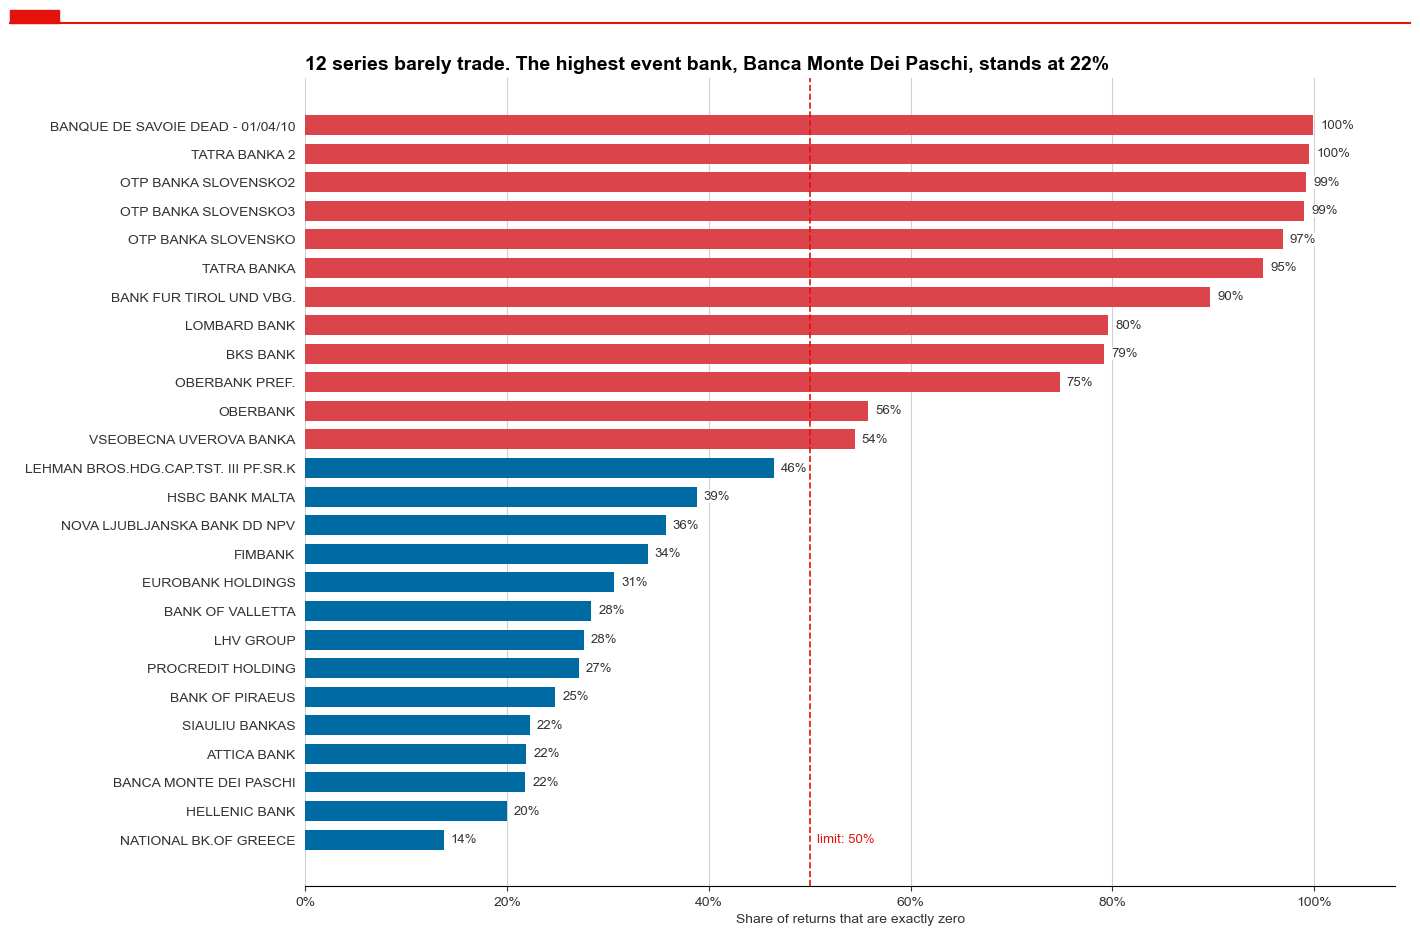

In [573]:
top_event_bank = zero_share[event_banks].idxmax()
top_event_share = zero_share[top_event_bank]

fig, ax = plt.subplots(figsize=(14, 9))
plot_zero_shares(ax, zero_share)
ax.set_title(f"{len(illiquid)} series barely trade. The highest event bank, "
             f"{top_event_bank.title()}, stands at {top_event_share:.0%}")
show()

**Comments – D2.5**
* **12 of 139 series barely trade:** the Slovak banks, small Austrian banks (Oberbank, BKS, Bank für Tirol), Lombard Bank in Malta and Banque de Savoie, dead since 2010. They would give betas near zero for no economic reason.

* **The limit is not a close call for our sample:** none of the 12 is an event bank, and the highest event bank, Monte dei Paschi, stands at 22%, far below 50%.

* **The other Maltese banks stay,** at 28% to 39%. Illiquid but alive, and they have no events.

* **Holidays do not change this list:** they still count as zero here, but they are only about 100 of 2,892 days, too few to bring a series below the limit.

* **The rule misses one series:** Lehman preferred stands at 46%, but its problem is the opposite one, as D2.6 shows.

### D2.6 Outliers
A chart of the largest daily moves shows what is left. Before we call a move a data error, we compare RI with PI, a second series for the same price. Both come from Datastream, so this catches an error in one series, not an error they share.

In [574]:
# The preferred share of a bankrupt firm, quoted in pennies
LEHMAN = "LEHMAN BROS.HDG.CAP.TST. III PF.SR.K"
LARGE_MOVE = 0.3  # a daily move above 30% in either direction


def large_moves(returns):
    '''List the daily returns above the limit in either direction.'''
    all_returns = returns.stack()
    return all_returns[all_returns.abs() > LARGE_MOVE]


liquid_returns = ri_liquid.pct_change(fill_method=None)
moves_before = large_moves(liquid_returns)
is_lehman = moves_before.index.get_level_values(1) == LEHMAN

print("Large moves, all series:", len(moves_before))
print("Of which Lehman preferred:", is_lehman.sum())
print(f"Largest move of Lehman: {moves_before[is_lehman].max():+.0%}")
print(f"Lowest RI of Lehman: {ri_liquid[LEHMAN].min():.2f}")

Large moves, all series: 642
Of which Lehman preferred: 510
Largest move of Lehman: +1250%
Lowest RI of Lehman: 0.01


The Lehman series is the preferred share of a bankrupt firm, quoted in pennies. Its noise never ends, so we drop the whole series and not just its worst day. This gives our final table of prices, in local currency.

In [575]:
prices = ri_liquid.drop(columns=LEHMAN)  # still in local currency
returns = prices.pct_change(fill_method=None)

moves_after = large_moves(returns)
move_dates = moves_after.index.get_level_values(0)
crisis_share = (move_dates.year <= 2009).mean()

print("Large moves left:", len(moves_after))
print(f"Of which in 2008 and 2009: {crisis_share:.0%}")

Large moves left: 132
Of which in 2008 and 2009: 60%


In [576]:
def plot_moves(ax, moves, color, label):
    '''Draw large daily moves as dots along the dates.'''
    dates = moves.index.get_level_values(0)
    ax.scatter(dates, moves.values, color=color, s=14, alpha=0.7, label=label)
    ax.axhline(0, color=DARK, lw=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

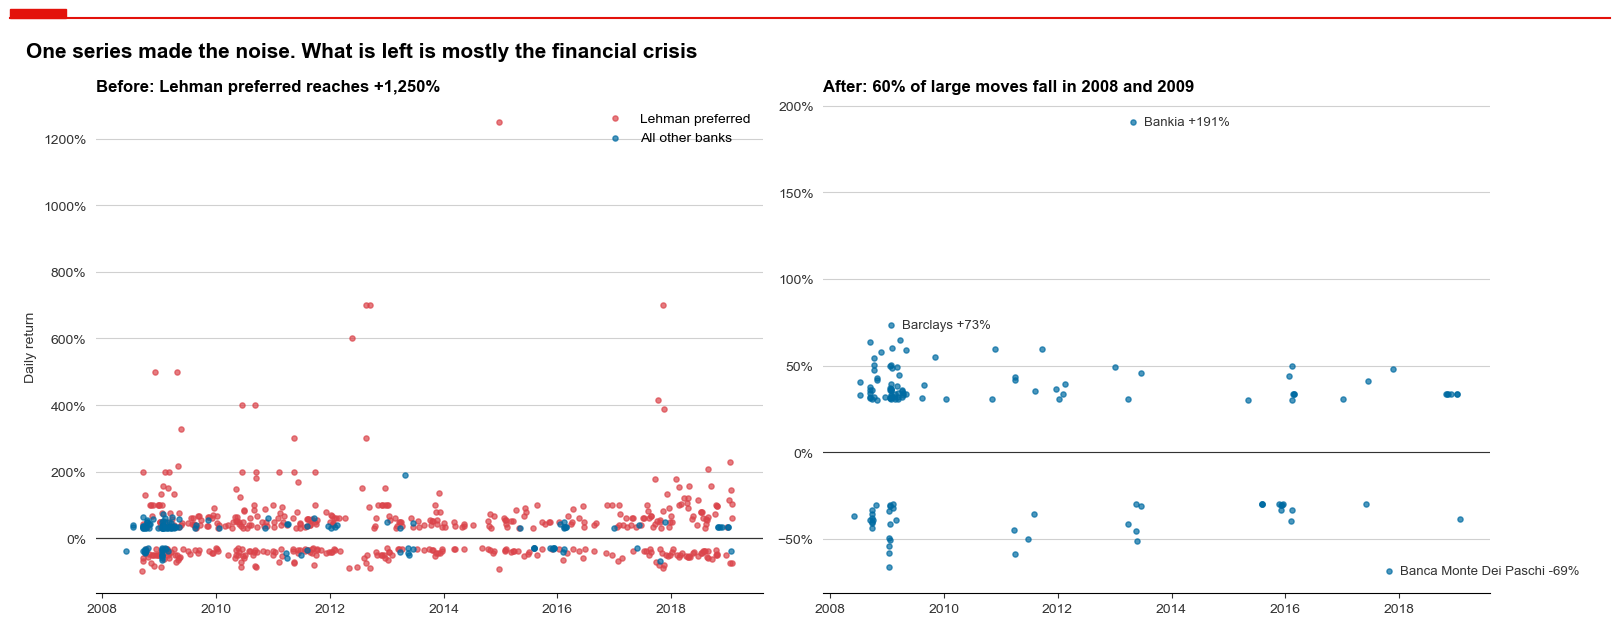

In [577]:
def label_top_moves(ax, moves):
    '''Write bank and size next to the three largest moves.'''
    top = moves.sort_values(key=abs).tail(3)
    for (date, bank), move in top.items():
        annotate(ax, f"{bank.title()} {move:+.0%}", (date, move), offset=(8, 0))


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_moves(axes[0], moves_before[is_lehman], ECONOMIST_COLORS[8],
           "Lehman preferred")
plot_moves(axes[0], moves_before[~is_lehman], ECONOMIST_COLORS[0],
           "All other banks")
axes[0].legend(loc="upper right")
axes[0].set_ylabel("Daily return")
axes[0].set_title(f"Before: Lehman preferred reaches "
                  f"{moves_before[is_lehman].max():+,.0%}", fontsize=12)

plot_moves(axes[1], moves_after, ECONOMIST_COLORS[0], "All other banks")
label_top_moves(axes[1], moves_after)
axes[1].set_title(f"After: {crisis_share:.0%} of large moves fall in "
                  "2008 and 2009", fontsize=12)
show("One series made the noise. What is left is mostly the financial crisis")

Are the largest moves left real? If RI and PI agree, the move is in the price itself and not an error in one series.

In [578]:
TOP_MOVES = 10  # moves in the table

# One bank has no PI series
pi_banks = pi_sample[prices.columns.intersection(pi_sample.columns)]
pi_returns = pi_banks.pct_change(fill_method=None)
event_counts = events["bank"].value_counts()

largest = moves_after.sort_values(key=abs, ascending=False).head(TOP_MOVES)
largest_table = largest.rename("RI return").to_frame()
largest_table["PI return"] = pi_returns.stack().reindex(largest.index)
largest_table = largest_table.rename_axis(["date", "bank"]).reset_index()
bank_events = largest_table["bank"].map(event_counts)
largest_table["events"] = bank_events.fillna(0).astype(int)

largest_table.style.format({
    "date": "{:%d %b %Y}",
    "RI return": "{:+.0%}",
    "PI return": "{:+.0%}",
})

,date,bank,RI return,PI return,events
0,30 Apr 2013,BANKIA,+191%,+190%,26
1,26 Jan 2009,BARCLAYS,+73%,+73%,144
2,25 Oct 2017,BANCA MONTE DEI PASCHI,-69%,-50%,1
3,19 Jan 2009,ROYAL BANK OF SCTL.GP.,-67%,-67%,120
4,25 Mar 2009,CREDIT FONCIER DE MONACO,+65%,+65%,0
5,18 Sep 2008,WESTERN ALL.BANCORP.,+63%,+64%,0
6,06 Feb 2009,FIFTH THIRD BANCORP,+60%,+60%,3
7,23 Sep 2011,PERMANENT TSB GHG.,+59%,+56%,1
8,29 Nov 2010,PERMANENT TSB GHG.,+59%,+59%,1
9,08 May 2009,FIFTH THIRD BANCORP,+59%,+59%,3


RI has two decimals, so at very low levels returns are rounding noise, and a suspended stock simply repeats its price. We look at both.

In [579]:
def longest_zero_run(daily_returns):
    '''Count the longest run of zero returns in one series.'''
    is_zero = daily_returns.dropna() == 0
    # The count stands still during a zero run, so a run shares one number
    run_number = (~is_zero).cumsum()
    return is_zero.groupby(run_number).sum().max()


lowest_ri = prices.min()
below_one = lowest_ri[lowest_ri < 1].sort_values()
zero_runs = returns[event_banks].apply(longest_zero_run)
zero_runs = zero_runs.sort_values(ascending=False)

print("Banks with an RI below 1:")
print(below_one.map("{:.2f}".format).to_string())
print("Longest runs of zero returns, event banks:")
print(zero_runs.head(3).to_string())

is_paschi = events["bank"] == "BANCA MONTE DEI PASCHI"
paschi_event = events.loc[is_paschi, "date"].iloc[0]
print(f"Monte dei Paschi event: {paschi_event:%d %b %Y}")

Banks with an RI below 1:
EUROBANK HOLDINGS         0.02
BANK OF PIRAEUS           0.03
BANCA MONTE DEI PASCHI    0.03
ATTICA BANK               0.07
NATIONAL BK.OF GREECE     0.27
Longest runs of zero returns, event banks:
BANCA MONTE DEI PASCHI    218
ALLY FINANCIAL             21
UMWELTBANK                  9
Monte dei Paschi event: 09 Dec 2016


**Comments – D2.6**
* **One series made most of the noise:** Lehman preferred holds 510 of 642 moves above 30%, up to +1,250%. It is the preferred share of a bankrupt firm, with an RI as low as 0.01. So we drop the whole series (left).

* **What is left looks like history:** 132 large moves, 60% of them in 2008 and 2009 (right).

* **The largest moves show no error in one series:** RI and PI agree within one percentage point on eight of the top ten. Bankia's +191% is in both, so it stays. Since it can still distort betas and CARs, in Task #4 we flag events whose estimation window holds a move above 50%, and in Task #6 we winsorise CARs: values beyond a percentile limit are set to that limit.

* **The two exceptions are banks at very low levels, where rounding matters:** Permanent TSB (+59% in RI, +56% in PI) and Monte dei Paschi (−69% and −50%), on the day its shares traded again after a suspension of 218 days. Later its RI falls to 0.03, where one step of 0.01 is a move of 33%: the row of dots at +33% in late 2018 (right).

* **Rounding touches little:** five banks fall below an RI of 1, but only Monte dei Paschi has an event, on 9 Dec 2016, before its noisiest stretch. So we leave these prices as they are.

### D2.7 Why returns come from RI (=Return Index [LSEG])
PI (=Price Index)ignores dividends. We show the gap on HSBC, our most targeted bank, and in pounds, because the conversion to US dollars comes later. PI has one decimal only, so we use it for this chart alone.

In [580]:
BANK_EXAMPLE = "HSBC HOLDINGS"


def growth_of_one(index_values):
    '''Turn an index into the growth of 1 from its first day.'''
    return index_values / index_values.iloc[0]


with_dividends = growth_of_one(prices[BANK_EXAMPLE])
without_dividends = growth_of_one(pi_banks[BANK_EXAMPLE])
dividend_gap = with_dividends.iloc[-1] - without_dividends.iloc[-1]

print(f"Banks with PI: {pi_banks.shape[1]} of {prices.shape[1]}")
print(f"Gap at the end: £{dividend_gap:.2f} per £1 invested")

Banks with PI: 125 of 126
Gap at the end: £0.65 per £1 invested


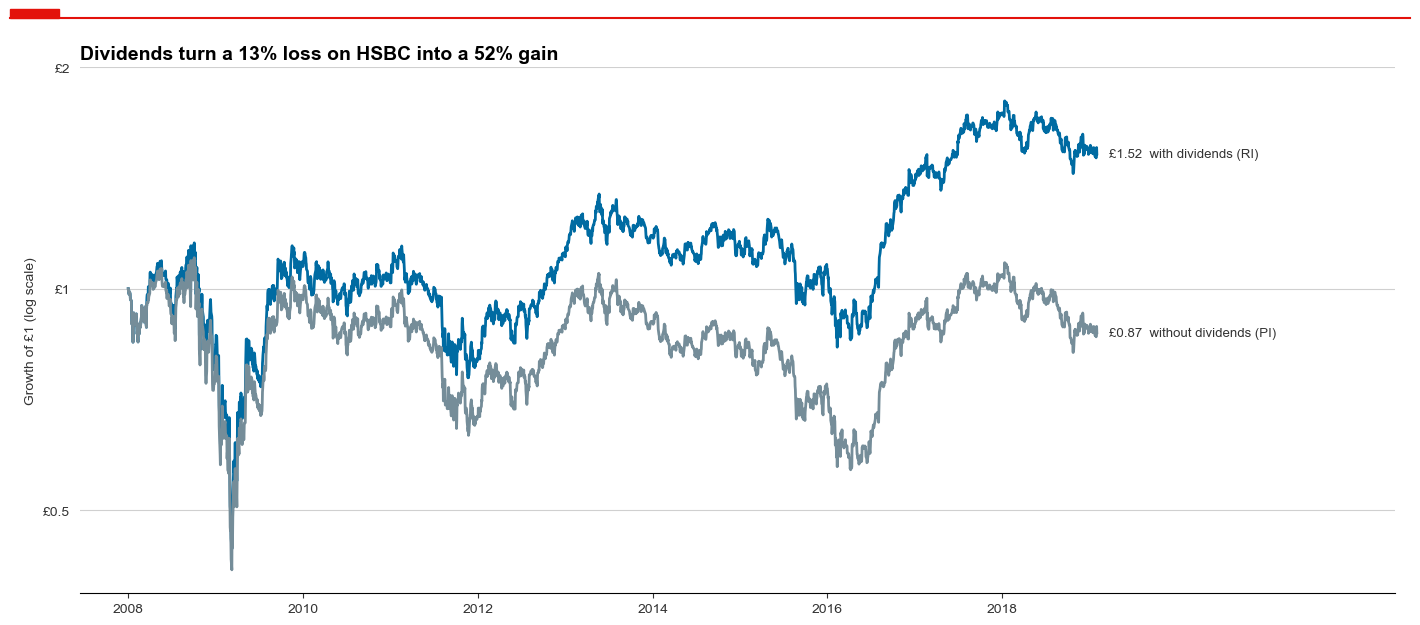

In [581]:
LOG_TICKS = [0.5, 1, 2]
YEAR_TICKS = pd.date_range("2008", "2018", freq="2YS")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(with_dividends, color=ECONOMIST_COLORS[0], lw=2)
ax.plot(without_dividends, color=GREY, lw=2)

end_date = prices.index[-1]
for series, label in [(with_dividends, "with dividends (RI)"),
                      (without_dividends, "without dividends (PI)")]:
    end_value = series.iloc[-1]
    annotate(ax, f"£{end_value:.2f}  {label}", (end_date, end_value))

ax.set_yscale("log")
ax.set_yticks(LOG_TICKS, labels=[f"£{tick:g}" for tick in LOG_TICKS])
ax.minorticks_off()
ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
ax.set_xlim(right=pd.Timestamp("2022-06-30"))  # room for the labels
ax.set_ylabel("Growth of £1 (log scale)")
ax.set_title(f"Dividends turn a {1 - without_dividends.iloc[-1]:.0%} loss on "
             f"HSBC into a {with_dividends.iloc[-1] - 1:.0%} gain")
show()

**Comments – D2.7**
* **Dividends decide the result:** £1 in HSBC in 2008 ends at £0.87 without dividends and at £1.52 with them, a gap of £0.65.

* **So all our returns come from RI.** A return from PI would make a bank look worse on every dividend day, for a reason that has nothing to do with NGOs.

* **PI stays out of the panel:** 125 of 126 banks have it, it has one decimal only, and we need it for this chart and the check in D2.6.

### D2.8 Data after cleaning
The cleaning in one picture.

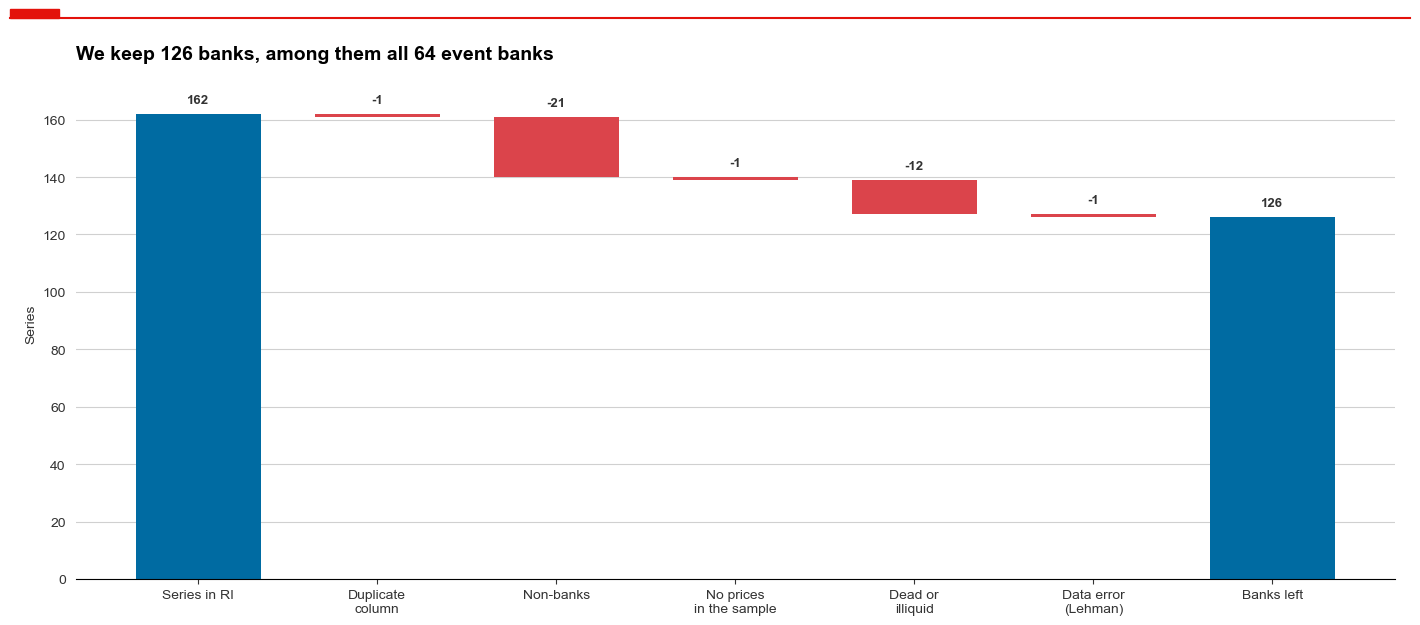

In [582]:
series_counts = [ri_sample.shape[1], ri_unique.shape[1], ri_banks.shape[1],
                 ri_priced.shape[1], ri_liquid.shape[1], prices.shape[1]]
cleaning_steps = ["Duplicate\ncolumn", "Non-banks", "No prices\nin the sample",
                  "Dead or\nilliquid", "Data error\n(Lehman)"]
event_banks_kept = len(set(event_banks) & set(prices.columns))

fig, ax = plt.subplots(figsize=(14, 6))
plot_waterfall(ax, series_counts, cleaning_steps, "Series in RI", "Banks left")
ax.set_ylabel("Series")
ax.set_title(f"We keep {prices.shape[1]} banks, among them all "
             f"{event_banks_kept} event banks")
show()

Prices do not cover every bank from the start, because some banks were listed late. An event needs about 300 trading days of prices before it, the estimation window of Task #4. We count how many events fall short of that.

In [583]:
FULL_HISTORY = 300  # weekdays of prices before an event

# Weekdays here, not trading days, so this is a first estimate
first_price = prices.apply(pd.Series.first_valid_index)
day_number = pd.Series(range(len(prices)), index=prices.index)

event_day = events["date"].map(day_number)
listing_day = events["bank"].map(first_price).map(day_number)
has_history = event_day - listing_day >= FULL_HISTORY

short_events = events.loc[~has_history, "bank"].value_counts()
print(f"Events without a full history: {(~has_history).sum()}")
print(short_events.to_string())

Events without a full history: 84
bank
ABN AMRO BANK      44
NIBC HOLDING       16
BANKIA              9
UNICAJA BANCO       6
LIBERBANK           4
METRO BANK          3
VIRGIN MONEY UK     2


In [584]:
def plot_banks_per_year(ax, prices):
    '''Show the number of banks with a price at the end of each year.'''
    has_price = prices.notna()
    # A bank counts for a year if it has a price on the last day
    year_ends = has_price.groupby(has_price.index.year).last()
    banks_per_year = year_ends.sum(axis=1)

    bars = ax.bar(banks_per_year.index, banks_per_year.values, width=0.7,
                  color=ECONOMIST_COLORS[0])
    ax.bar_label(bars, padding=3, fontsize=9.5, color=DARK)
    ax.set_xticks(banks_per_year.index,
                  [f"{year}" for year in banks_per_year.index], rotation=45)
    ax.set_ylabel("Banks with a price")
    first_year, last_year = banks_per_year.iloc[0], banks_per_year.iloc[-1]
    ax.set_title(f"Coverage grows from {first_year} to {last_year} banks",
                 fontsize=12)

In [585]:
def plot_late_listings(ax, events, has_history, first_price, prices):
    '''Show when each late event bank was listed and where its events fall.'''
    event_first_price = first_price[events["bank"].unique()]
    late = event_first_price[event_first_price > prices.index[0]]
    late = late.sort_values(ascending=False)

    for position, (bank, listed) in enumerate(late.items()):
        ax.hlines(position, listed, prices.index[-1], color=LIGHT_GREY, lw=9)
        is_bank = events["bank"] == bank
        kept = events[is_bank & has_history]["date"]
        short = events[is_bank & ~has_history]["date"]
        ax.scatter(kept, [position] * len(kept), marker="|", s=90, zorder=3,
                   color=ECONOMIST_COLORS[0])
        ax.scatter(short, [position] * len(short), marker="|", s=90, zorder=3,
                   color=ECONOMIST_COLORS[8])

    ax.set_yticks(range(len(late)), late.index)
    ax.set_ylim(-0.7, len(late) - 0.3)
    vertical_grid(ax)
    ax.set_title(f"{(~has_history).sum()} of {len(events):,} events (red) "
                 "have no full estimation window", fontsize=12)

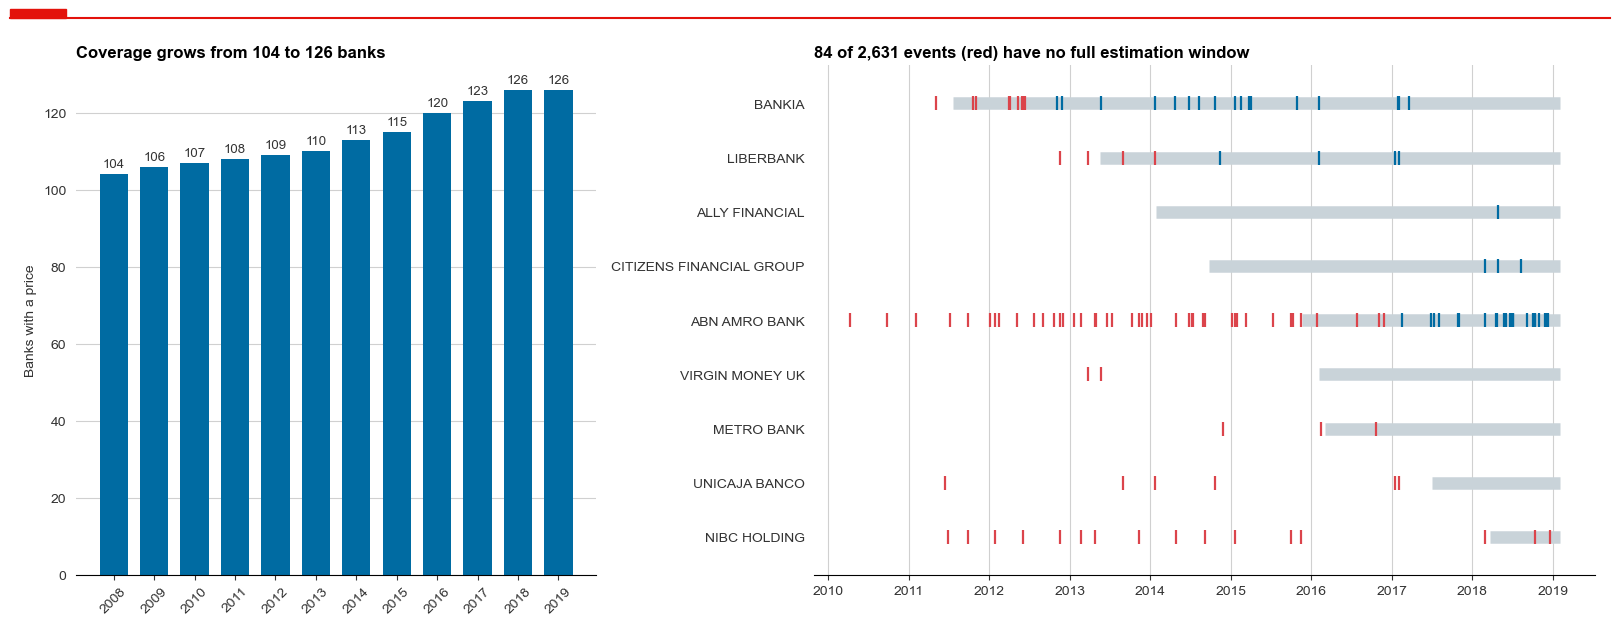

In [586]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         gridspec_kw={"width_ratios": [1, 1.5]})
plot_banks_per_year(axes[0], prices)
plot_late_listings(axes[1], events, has_history, first_price, prices)
show()

Finally, the shape of daily returns, for our eight most targeted banks. The dashed line is the normal distribution with the same mean and volatility.

In [587]:
TOP_TARGETS = 8  # banks in the figure
BINS = np.arange(-0.15, 0.1501, 0.005)  # half a point wide
RETURN_GRID = np.linspace(-0.15, 0.15, 300)
KURTOSIS_LABEL = (0.14, 22)  # top right of each panel: return, density


def normal_density(values, mean, std):
    '''Compute the normal density at the given values.'''
    distance = (values - mean) / std
    return np.exp(-distance ** 2 / 2) / (std * np.sqrt(2 * np.pi))


def plot_distribution(ax, daily_returns, bank):
    '''Show one bank's daily returns against a normal distribution.'''
    daily = daily_returns.dropna()
    ax.hist(daily, bins=BINS, density=True, color=ECONOMIST_COLORS[0])
    ax.plot(RETURN_GRID, normal_density(RETURN_GRID, daily.mean(), daily.std()),
            color=ECONOMIST_RED, ls="--")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(bank, fontsize=11)
    annotate(ax, f"Excess kurtosis {daily.kurt():.0f}", KURTOSIS_LABEL,
             offset=(0, 0), ha="right")

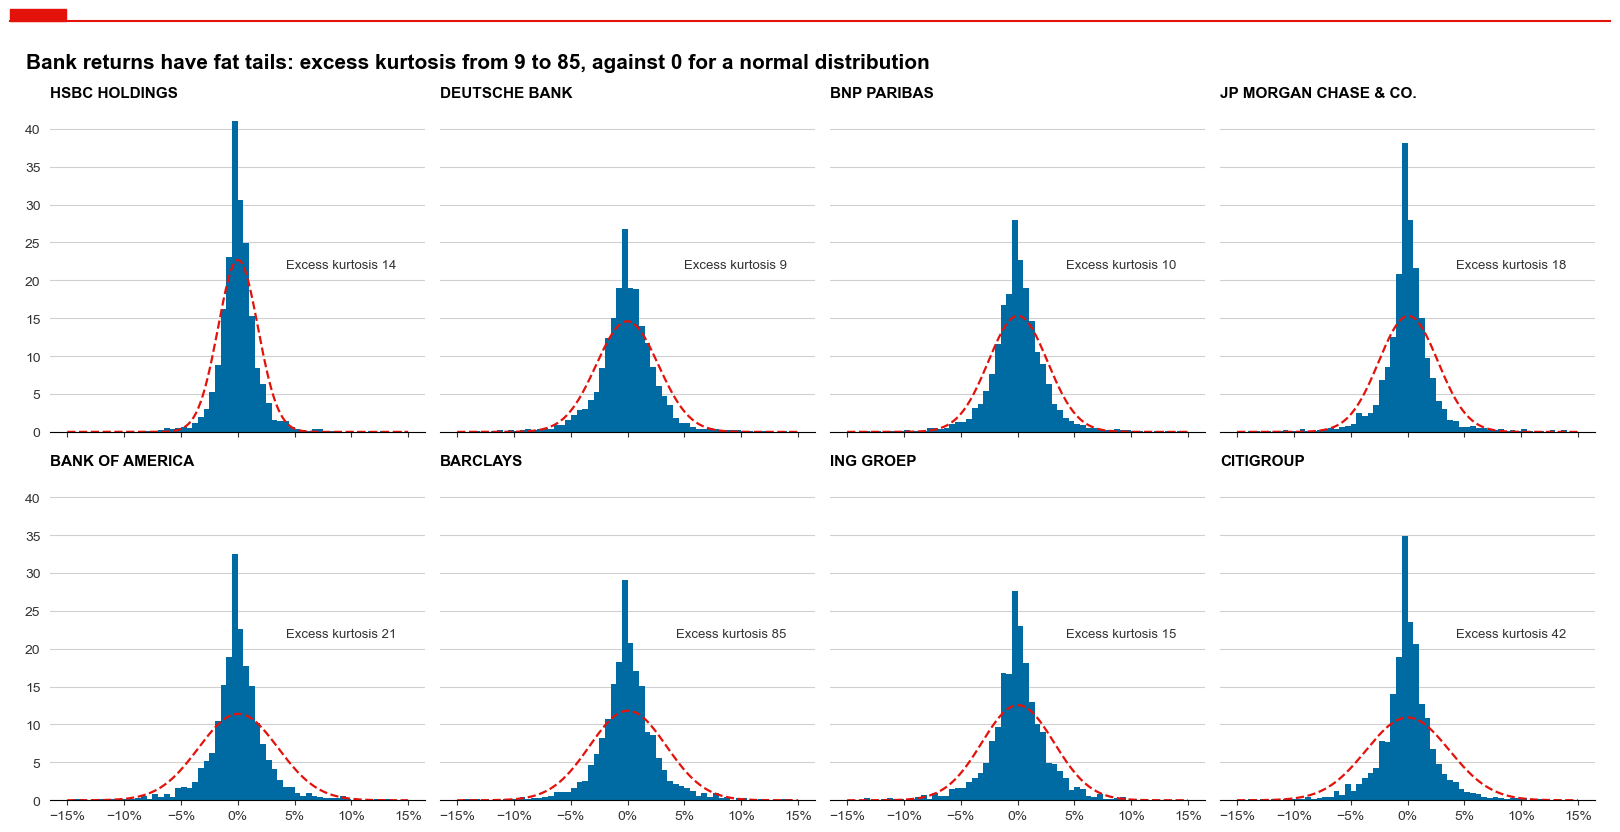

In [588]:
top_targets = events["bank"].value_counts().head(TOP_TARGETS).index
excess_kurtosis = returns[top_targets].kurt()

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for ax, bank in zip(axes.flat, top_targets):
    plot_distribution(ax, returns[bank], bank)
show(f"Bank returns have fat tails: excess kurtosis from "
     f"{excess_kurtosis.min():.0f} to {excess_kurtosis.max():.0f}, "
     "against 0 for a normal distribution")

**Jarque-Bera test.** A formal test of normality, built from skewness and excess kurtosis, as in PC Labs #1 and #2.

In [589]:
def jb_test(daily_returns):
    '''Run the Jarque-Bera normality test on every column.'''
    days = daily_returns.count()
    skewness = daily_returns.skew()
    kurtosis = daily_returns.kurt()  # pandas gives excess kurtosis
    jb = days / 6 * (skewness ** 2 + kurtosis ** 2 / 4)
    p_value = np.exp(-jb / 2)  # chi-squared with 2 degrees of freedom
    return pd.DataFrame({
        "skewness": skewness,
        "excess kurtosis": kurtosis,
        "JB": jb,
        "p value": p_value,
    })


jb_test(returns[top_targets]).style.format({
    "skewness": "{:.2f}",
    "excess kurtosis": "{:.1f}",
    "JB": "{:,.0f}",
    "p value": "{:.4f}",
})

,skewness,excess kurtosis,JB,p value
HSBC HOLDINGS,0.14,13.5,"22,009",0.0000
DEUTSCHE BANK,0.70,9.1,"10,160",0.0000
BNP PARIBAS,0.64,9.8,"11,756",0.0000
JP MORGAN CHASE & CO.,1.03,17.9,"39,057",0.0000
BANK OF AMERICA,0.87,21.5,"55,880",0.0000
BARCLAYS,3.67,84.9,"874,934",0.0000
ING GROEP,0.71,15.1,"27,800",0.0000
CITIGROUP,1.54,42.2,"215,729",0.0000


We check the table in two ways. Compounding the returns must give back the index, and every event bank must have a column.

In [590]:
# Check: compounded returns rebuild the index from its first day
# Missing returns count as no change, only for this check
compounded = (1 + returns.fillna(0)).prod()
index_growth = prices.ffill().iloc[-1] / prices.bfill().iloc[0]
print("Returns rebuild the index:", np.allclose(compounded, index_growth))

missing_banks = set(event_banks) - set(prices.columns)
print("Event banks without prices:", len(missing_banks))
print(f"Table of prices: {len(prices):,} days, {prices.shape[1]} banks")

Returns rebuild the index: True
Event banks without prices: 0
Table of prices: 2,893 days, 126 banks


**Comments – D2.8**
* **We keep 126 of 162 series, and all 64 event banks.** Our cleaning removed firms, but no campaign.

* **Late listings cost more than cleaning does:** coverage grows from 104 to 126 banks (left), and 84 of 2,631 events have no full estimation window (right). ABN AMRO alone loses 44, because it was listed only in November 2015. NIBC loses 16, Bankia 9. This count is a first estimate on weekdays. Task #5 gives the exact list, with a reason for every event.

* **Daily returns have fat tails, and normality fails:** excess kurtosis runs from 9 to 85 for our eight most targeted banks, with Barclays at 85 after its +73% day, and the Jarque-Bera test rejects normality for all eight (p value 0.0000). So we cannot rely on a plain t test in Task #6: the sign test, which asks whether the share of positive CARs differs from normal, needs no normal distribution, the BMP test (Boehmer, Musumeci and Poulsen, 1991) scales every bank by its own volatility, and winsorised CARs limit the few extreme days. Section 6.2 defines both tests.

* **The table passes its checks:** compounded returns rebuild every index, and every event bank has a column.

* **`prices` is not final yet.** It is in local currency and still holds the holidays, so the next step sets those returns to missing and converts everything to US dollars.

### D2.9 Holidays
Datastream repeats the last price on a holiday, so the return is exactly zero. These false zeros would pull betas towards zero. The Fama French files, which hold the daily factors of D2.11, cannot tell us the holidays, because they hold every weekday, Christmas Day included. So we read them from the prices: a day is a holiday for a region when all its big banks show exactly zero. Large banks almost never do that on a real trading day.

First we give every bank its region, from the sheet of its price series.

In [591]:
SHEET_REGIONS = {"US": "US", "UK": "UK", "SD": "Sweden"}  # others: euro area


def bank_regions():
    '''Give each bank the region of its Datastream sheet.'''
    sheets = read_sheets(MAIN_PRICES, NORDIC_PRICES, rows=0)

    regions = {}
    for sheet_name, sheet in sheets.items():
        region = SHEET_REGIONS.get(sheet_name, "Euro area")
        for header in sheet.columns:
            regions[header.replace(RI_TAIL, "")] = region
    return pd.Series(regions)


bank_region = bank_regions()[prices.columns]
print(bank_region.value_counts().to_string())

Euro area    64
US           48
UK           10
Sweden        4


Does this agree with the groups of Day 1, which use the parent's country?

In [592]:
event_region = events["bank"].map(bank_region)
other_region = events[event_region != events["country_group"]]
print(other_region["bank"].value_counts().to_string())

bank
NORDEA BANK    44


Now we find the holidays of each region.

In [593]:
# Large, liquid banks: if all of them stand still, the market was closed
BIG_BANKS = {
    "US": ["BANK OF AMERICA", "CITIGROUP", "JP MORGAN CHASE & CO.",
           "WELLS FARGO & CO"],
    "UK": ["BARCLAYS", "HSBC HOLDINGS", "LLOYDS BANKING GROUP",
           "ROYAL BANK OF SCTL.GP."],
    "Euro area": ["BANCO SANTANDER", "BNP PARIBAS", "DEUTSCHE BANK",
                  "ING GROEP", "SOCIETE GENERALE"],
    "Sweden": ["SKANDINAVISKA ENSKILDA BANKEN A", "SVENSKA HANDELSBANKEN A",
               "SWEDBANK A"],
}


def find_holidays(returns, banks):
    '''Mark the days when all the given banks show exactly zero.'''
    return returns[banks].eq(0).all(axis=1)


holidays = pd.DataFrame(index=returns.index)
for region, banks in BIG_BANKS.items():
    holidays[region] = find_holidays(returns, banks)

print(holidays.sum().to_string())

US           102
UK            90
Euro area     53
Sweden       108


We test the rule in two ways. Closures we know must be on the list: Hurricane Sandy and the funeral of President Bush for the US, Christmas for everybody. And on the days we find, the other banks of the region must stand still too, while no other day may look like a holiday.

In [594]:
NEAR_ALL_ZERO = 0.7  # share of banks at zero that looks like a holiday

print("Sandy:", holidays.loc["2012-10-29":"2012-10-30", "US"].all())
print("Bush funeral:", holidays.loc["2018-12-05", "US"])
print("Christmas 2018:", holidays.loc["2018-12-25"].all())

Sandy: True
Bush funeral: True
Christmas 2018: True


In [595]:
rows = []
for region in REGION_ORDER:
    banks = bank_region[bank_region == region].index
    zero_banks = (returns[banks] == 0).sum(axis=1)
    zero_share_of_day = zero_banks / returns[banks].notna().sum(axis=1)
    is_holiday = holidays[region]
    other_days = zero_share_of_day[~is_holiday]
    rows.append({
        "holidays": is_holiday.sum(),
        "banks at zero on them": zero_share_of_day[is_holiday].median(),
        "other days with 70% at zero": (other_days >= NEAR_ALL_ZERO).sum(),
    })

holiday_check = pd.DataFrame(rows, index=REGION_ORDER)
holiday_check.style.format({"banks at zero on them": "{:.0%}"})

,holidays,banks at zero on them,other days with 70% at zero
US,102,100%,0
UK,90,100%,0
Euro area,53,94%,1
Sweden,108,100%,2


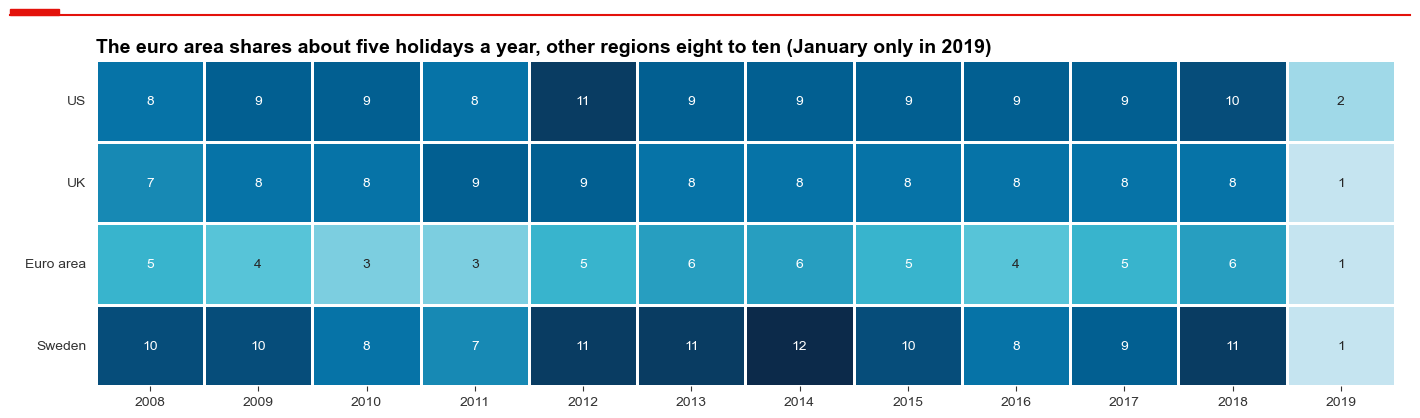

In [596]:
holidays_per_year = holidays.groupby(holidays.index.year).sum().T
holidays_per_year = holidays_per_year.loc[REGION_ORDER]

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(holidays_per_year, annot=True, fmt="d", cmap=ECONOMIST_BLUES,
            linewidths=1, cbar=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
ax.set_title("The euro area shares about five holidays a year, "
             "other regions eight to ten (January only in 2019)")
show()

A closure in one country is not a holiday of the whole euro area, so the rule cannot see it. We count such days for the euro countries with several event banks.

In [597]:
is_euro_event = event_region == "Euro area"
euro_banks = events[is_euro_event].groupby("country")["bank"].unique()

for country, banks in euro_banks.items():
    # One bank at zero could simply be illiquid
    if len(banks) > 1:
        all_zero = find_holidays(returns, list(banks))
        local_closures = all_zero & ~holidays["Euro area"]
        print(f"{country} ({len(banks)} banks), days: {local_closures.sum()}")

France (4 banks), days: 1
Germany (3 banks), days: 18
Ireland (3 banks), days: 30
Italy (4 banks), days: 25
Netherlands (4 banks), days: 0
Spain (8 banks), days: 0


**Comments – D2.9**
* **We find 102 holidays in the US, 90 in the UK, 53 in the euro area and 108 in Sweden.** The Fama French files cannot give us this list, since they hold every weekday.

* **The rule passes both tests:** Hurricane Sandy, the Bush funeral and Christmas are on the list. On the days we find, 94% to 100% of a region's banks stand still (median), while at most two other days look like a holiday.

* **Closures in one country stay invisible:** Ireland 30 days, Italy 25, Germany 18, France 1. Their zero returns remain, which is why the euro area keeps more of them than the other regions (D2.10). These days are few, and we accept this to keep one simple rule.

* **Nordea is the only bank that changes group:** its 44 events are Swedish in Day 1, by the parent's country, but its prices follow the euro area, by the sheet of its series.

### D2.10 Conversion from local currency to US dollars
Our bank prices are in local currency, while the Fama French factors are in US dollars. We convert every price, so that returns and factors are in the same currency and the US T-bill is the right risk free rate for all banks. Covered interest parity supports this: a foreign bill hedged into dollars earns about the US rate.

The file holds pounds and euros as dollars per unit, but the krona as units per dollar, so we invert it.

In [744]:
FX_FILE = "Exchange_Rates_LSEG.xlsx"    # Excel file holding Datastream exchange rates
REGION_CURRENCY = {"US": "USD", "UK": "GBP", "Euro area": "EUR",
                   "Sweden": "SEK"}


def load_fx():
    '''Load the exchange rates as US dollars per unit of each currency.'''
    rates = pd.read_excel(FX_FILE, index_col=0).rename_axis("date")
    rates.columns = ["GBP", "EUR", "SEK", "NOK", "CHF"]

    fx = pd.DataFrame(index=rates.index)
    fx["USD"] = 1.0  # US banks use the same formula
    fx["GBP"] = rates["GBP"]
    fx["EUR"] = rates["EUR"]
    fx["SEK"] = 1 / rates["SEK"]  # quoted as krona per dollar
    return fx


fx = load_fx().loc[:SAMPLE_END]
print("Same days as the prices:", fx.index.equals(prices.index))
print("Missing rates:", fx.isna().sum().sum())
print(fx.iloc[[0, -1]].round(4).to_string())

Same days as the prices: True
Missing rates: 0
              USD    GBP    EUR    SEK
date                                  
2008-01-01 1.0000 1.9906 1.4620 0.1547
2019-01-31 1.0000 1.3154 1.1474 0.1105


Sigwatch files Nordea under Sweden, but its price series is the Helsinki quote, so we treat it as a euro series. We can test that. If Nordea is quoted in euros and the Swedish banks in krona, the gap between their returns must fall when the euro rises against the krona, with a slope near −1. For two Swedish banks, as a placebo (a test where we expect no effect), the slope must be near zero.

In [599]:
HAC_LAGS = 5  # one trading week of Newey-West lags


def currency_slope(return_gap, currency_change):
    '''Estimate how a return gap moves with a change in a currency.'''
    data = pd.concat([return_gap, currency_change], axis=1).dropna()
    fit = ols(data.iloc[:, 0], data.iloc[:, 1], hac_lags=HAC_LAGS)
    return fit.params[1], fit.tvalues[1]


# Both in dollars per unit, so their ratio is krona per euro
euro_in_krona = (fx["EUR"] / fx["SEK"]).pct_change()
swedish_banks = returns[BIG_BANKS["Sweden"]].mean(axis=1)
nordea_gap = returns["NORDEA BANK"] - swedish_banks
placebo_gap = returns["SWEDBANK A"] - swedish_banks

for name, gap in [("Nordea", nordea_gap), ("Placebo", placebo_gap)]:
    slope, t_statistic = currency_slope(gap, euro_in_krona)
    print(f"{name}: slope {slope:.2f}, t {t_statistic:.1f}")

Nordea: slope -0.79, t -9.9
Placebo: slope -0.03, t -0.4


Each price gets the rate of its currency.

In [600]:
bank_currency = bank_region.map(REGION_CURRENCY)
# One rate column per bank, in the order of the prices
bank_fx = fx[bank_currency.values]
bank_fx.columns = prices.columns

usd_prices = prices * bank_fx

On a holiday the price stands still, but the exchange rate moves. If we simply deleted that day's return, we would lose this currency move. So we compute returns over the trading days of each region: the holiday stays missing, and the next return covers both days. The price and the exchange rate then always span the same period.

In [601]:
def trading_day_returns(usd_prices, holidays, bank_region):
    '''Compute returns over the trading days of each bank's region.'''
    tables = []
    for region in holidays.columns:
        banks = bank_region[bank_region == region].index
        trading_days = ~holidays[region]
        # Without holidays, pct_change spans them and keeps the currency move
        region_prices = usd_prices.loc[trading_days, banks]
        tables.append(region_prices.pct_change(fill_method=None))

    region_returns = pd.concat(tables, axis=1)
    # Holidays come back as missing returns
    return region_returns.reindex(index=usd_prices.index,
                                  columns=usd_prices.columns)


usd_returns = trading_day_returns(usd_prices, holidays, bank_region)

We check the result against a second method, the formula $r^{USD}_t = (1 + r^{local}_t) \times S_t / S_{t-1} - 1$, on all days not touched by a holiday.

In [602]:
is_bank_holiday = holidays[bank_region.values]
is_bank_holiday.columns = prices.columns
# A return after a holiday spans two days, so the formula does not fit
after_holiday = is_bank_holiday.shift(1, fill_value=False)
normal_day = ~is_bank_holiday & ~after_holiday

fx_change = bank_fx.pct_change()
formula_returns = (1 + returns) * (1 + fx_change) - 1

same_as_formula = np.allclose(usd_returns.where(normal_day),
                              formula_returns.where(normal_day),
                              equal_nan=True)
print("Same as the formula:", same_as_formula)
print("Returns left on holidays:",
      usd_returns.where(is_bank_holiday).notna().sum().sum())

Same as the formula: True
Returns left on holidays: 0


In [603]:
# Check: compounded returns rebuild the dollar index across the holidays
compounded_usd = (1 + usd_returns.fillna(0)).prod()
usd_growth = usd_prices.ffill().iloc[-1] / usd_prices.bfill().iloc[0]
print("Returns rebuild the index:", np.allclose(compounded_usd, usd_growth))

# Check: nothing changes for US banks, apart from the holidays
us_banks = bank_region[bank_region == "US"].index
# The dollar return after a US holiday spans two days, so we leave it out
us_trading = ~holidays["US"].shift(1, fill_value=False)
print("US banks unchanged:",
      np.allclose(usd_returns.loc[us_trading, us_banks],
                  returns.loc[us_trading, us_banks].where(~holidays["US"]),
                  equal_nan=True))

Returns rebuild the index: True
US banks unchanged: True


What do holidays and currency do to the numbers? We compare zero returns and volatility, and we look at the day of the Brexit vote.

In [604]:
DAYS = 252  # trading days per year, used to annualise daily numbers
BREXIT = pd.Timestamp("2016-06-24")  # first trading day after the vote


def zero_rate(table):
    '''Compute the share of all returns that are exactly zero.'''
    return (table == 0).sum().sum() / table.notna().sum().sum()



def region_event_banks(region):
    '''List the event banks of one region.'''
    banks = bank_region[bank_region == region].index
    return banks.intersection(event_banks)

Now the table, region by region, and the day of the Brexit vote.

In [605]:
# In dollars a stale price still moves with the currency, so we count zeros
# in local currency, on the trading days of each region
local_trading = returns.where(usd_returns.notna())

rows = []
for region in REGION_ORDER:
    banks = region_event_banks(region)
    rows.append({
        "zero returns, all days": zero_rate(returns[banks]),
        "zero returns, trading days": zero_rate(local_trading[banks]),
        "volatility, local": returns[banks].std().median() * np.sqrt(DAYS),
        "volatility, USD": usd_returns[banks].std().median() * np.sqrt(DAYS),
    })

effect_table = pd.DataFrame(rows, index=REGION_ORDER)
print(f"HSBC on {BREXIT:%d %b %Y}: {returns.loc[BREXIT, BANK_EXAMPLE]:+.1%} "
      f"in pounds, {usd_returns.loc[BREXIT, BANK_EXAMPLE]:+.1%} in dollars")
effect_table.style.format("{:.1%}")

HSBC on 24 Jun 2016: -1.4% in pounds, -9.3% in dollars


,"zero returns, all days","zero returns, trading days","volatility, local","volatility, USD"
US,4.8%,1.3%,41.7%,42.4%
UK,3.9%,0.9%,40.1%,44.7%
Euro area,6.0%,4.3%,44.3%,47.2%
Sweden,5.9%,2.3%,38.6%,45.3%


In [606]:
def plot_currencies(ax, fx):
    '''Show the value of each currency in dollars, from its first day.'''
    colors = [ECONOMIST_COLORS[0], ECONOMIST_COLORS[1], ECONOMIST_COLORS[2]]
    end_date = fx.index[-1]
    for currency, color in zip(["GBP", "EUR", "SEK"], colors):
        value = growth_of_one(fx[currency])
        ax.plot(value, color=color, lw=2)
        annotate(ax, f"{currency} {value.iloc[-1] - 1:+.0%}",
                 (end_date, value.iloc[-1]))

    ax.axvline(BREXIT, color=DARK, ls="--", lw=1)
    annotate(ax, "Brexit vote", (BREXIT, 1.05), offset=(-5, 0))
    ax.set_xlim(right=pd.Timestamp("2021-01-31"))  # room for the labels
    ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
    ax.set_ylabel("Value in US dollars (first day = 1)")
    ax.set_title("All three currencies lost against the dollar", fontsize=12)

In [607]:
def plot_two_currencies(ax, in_pounds, in_dollars):
    '''Show the growth of one bank in pounds and in dollars.'''
    end_date = in_pounds.index[-1]
    ax.plot(in_pounds, color=GREY, lw=2)
    ax.plot(in_dollars, color=ECONOMIST_COLORS[0], lw=2)
    annotate(ax, f"£{in_pounds.iloc[-1]:.2f} in pounds",
             (end_date, in_pounds.iloc[-1]))
    annotate(ax, f"${in_dollars.iloc[-1]:.2f} in dollars",
             (end_date, in_dollars.iloc[-1]))

    ax.set_xlim(right=pd.Timestamp("2021-12-31"))  # room for the labels
    ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
    ax.set_ylabel("Growth of 1, with dividends")
    ax.set_title("In dollars, the gain of HSBC almost disappears", fontsize=12)

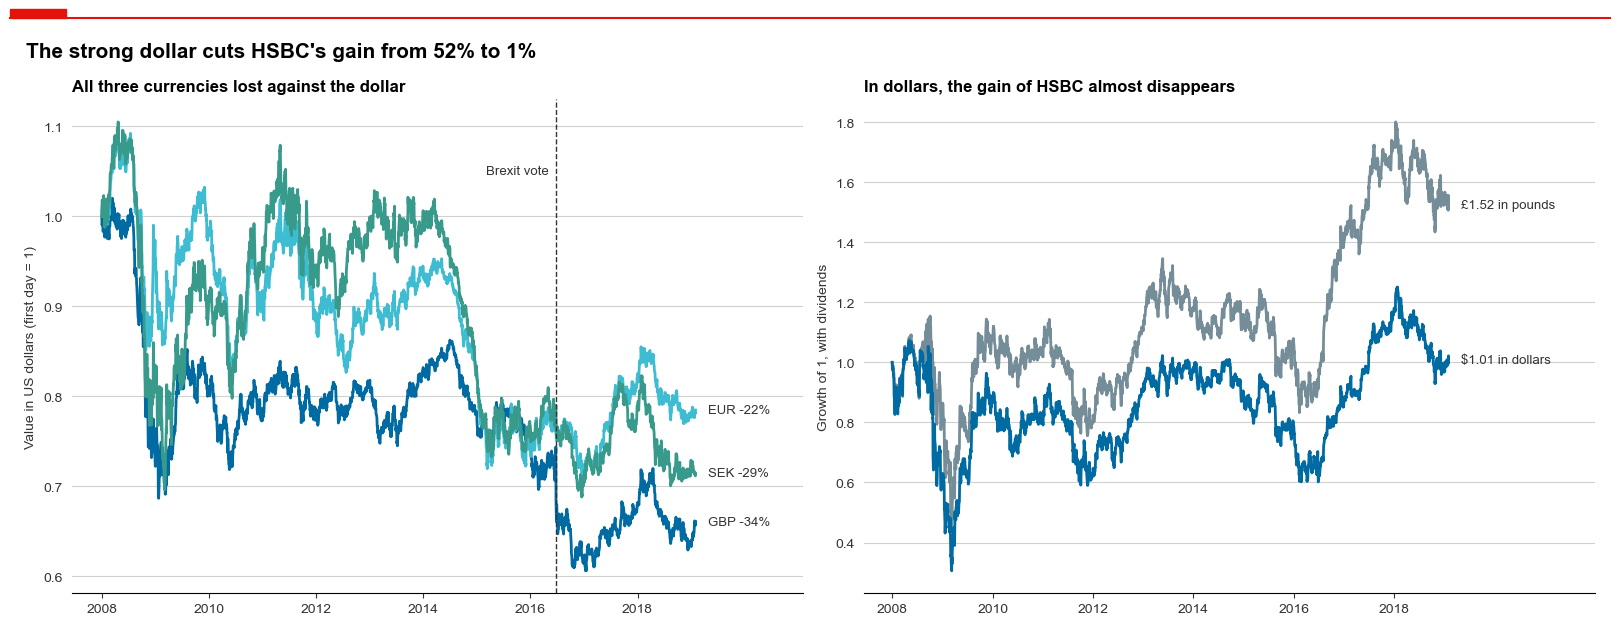

In [608]:
hsbc_pounds = growth_of_one(prices[BANK_EXAMPLE])
hsbc_dollars = growth_of_one(usd_prices[BANK_EXAMPLE])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_currencies(axes[0], fx)
plot_two_currencies(axes[1], hsbc_pounds, hsbc_dollars)
show(f"The strong dollar cuts HSBC's gain from {hsbc_pounds.iloc[-1] - 1:.0%} "
     f"to {hsbc_dollars.iloc[-1] - 1:.0%}")

**Comments – D2.10**
* **The currency matters a lot:** since January 2008 the pound lost 34% against the dollar, the krona 29%, the euro 22% (left). HSBC's gain of 52% in pounds is 1% in dollars (right).

* **It also matters on a single day:** on the day after the Brexit vote HSBC fell 1.4% in pounds, but 9.3% in dollars.

* **Our Nordea treatment holds:** the gap to the Swedish banks moves with the euro at a slope of −0.79 (t −9.9), against −0.03 for the placebo. So Nordea's series is in euros.

* **Removing holidays works where the calendar fits:** among event banks, zero returns fall from 4.8% to 1.3% in the US, 3.9% to 0.9% in the UK and 5.9% to 2.3% in Sweden, but only from 6.0% to 4.3% in the euro area, because of the local closures of D2.9. We count them in local currency, because in dollars a stale price still moves with the currency.

* **Volatility rises outside the US,** for example from 40.1% to 44.7% a year in the UK. This is the cost of conversion, and D2.12 shows what we get for it.

* **The checks pass:** our returns equal the formula on normal days, no return is left on a holiday, compounded returns rebuild every index, and US banks do not change.

### D2.11 Fama French five factors and momentum
Task #4 needs the five factors and momentum, daily, for North America and for Europe. We download them from Ken French's data library, where all returns are in US dollars. The notebook downloads them on every run and writes no file. The files mark missing values as −99.99.

In [ ]:
FACTOR_URL = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
              "{}_CSV.zip")
# The server may refuse a request without a browser name
BROWSER = {"User-Agent": "Mozilla/5.0 (Bocconi 20598 PC Lab, academic use)"}


def read_factor_file(name):
    '''Read one daily file of Ken French's library, in decimals.'''
    table = pd.read_csv(FACTOR_URL.format(name), compression="zip", skiprows=6,
                        index_col=0, storage_options=BROWSER)
    table.columns = table.columns.str.strip()
    dates = table.index.astype(str).str.strip()
    table.index = pd.to_datetime(dates, format="%Y%m%d")
    return table / 100      # the files are in percent

In [610]:
def daily_factors(region, first_day):
    '''Download the five factors and momentum of one region.'''
    five_factors = read_factor_file(f"{region}_5_Factors_Daily")
    momentum = read_factor_file(f"{region}_MOM_Factor_Daily")
    factors = five_factors.join(momentum, how="inner")
    # round(6) removes the float noise of the division by 100
    return factors.loc[first_day:SAMPLE_END].round(6)

In [611]:
factors_north_america = daily_factors("North_America", prices.index[0])
factors_europe = daily_factors("Europe", prices.index[0])

print(f"Days: {len(factors_europe):,}, columns:",
      list(factors_europe.columns))
print("Same days as the prices:", factors_europe.index.equals(prices.index))
# The files mark missing values as -99.99, so -0.9999 after our division
print("Missing values:", (factors_europe < -0.9).sum().sum()
      + (factors_north_america < -0.9).sum().sum())

Days: 2,893, columns: ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF', 'WML']
Same days as the prices: True
Missing values: 0


### D2.12 Risk free rate and market return
The factor files come with the US one month T-bill, which we use as the risk free rate of every bank (since we converted returns in USD). We compare it with the T-bill series of the course files, a second source. The market return of Krüger's model is the excess return of the market plus the risk free rate (raw returns).

In [612]:
# US T-bill rates of the course
RATE_FILE = "banks_data_bocconi/risk_free_rate.xlsm"

same_rate = factors_europe["RF"].equals(factors_north_america["RF"])
print("Same risk free rate in both regions:", same_rate)

course_rates = pd.read_excel(RATE_FILE, sheet_name="DAILY", header=2,
                             index_col=0)
course_rates = course_rates.loc[:SAMPLE_END] / 100  # annualised percent
print(course_rates.columns.tolist())

Same risk free rate in both regions: True
['US T-BILL SEC MARKET 3 MONTH (D) - MIDDLE RATE', 'US T-BILL SEC MARKET 4 WEEK (D) - MIDDLE RATE']


In [613]:
factor_rate = factors_europe["RF"] * DAYS  # daily to annual
course_rate = course_rates.iloc[:, 1]  # the 4 week bill

print(f"Average, factor files: {factor_rate.mean():.2%} a year")
print(f"Average, course file: {course_rate.mean():.2%} a year")
print(f"Correlation: {factor_rate.corr(course_rate):.3f}")

Average, factor files: 0.40% a year
Average, course file: 0.43% a year
Correlation: 0.878


In [614]:
# The files hold the market excess return, Krüger needs the raw one
factors_europe["market"] = factors_europe["Mkt-RF"] + factors_europe["RF"]
factors_north_america["market"] = (factors_north_america["Mkt-RF"]
                                   + factors_north_america["RF"])

summary = {
    "North America": factors_north_america.mean() * DAYS,
    "Europe": factors_europe.mean() * DAYS,
}
pd.DataFrame(summary).style.format("{:.1%}")

,North America,Europe
Mkt-RF,8.5%,3.1%
SMB,0.4%,0.9%
HML,-1.9%,-1.9%
RMW,2.4%,5.1%
CMA,0.4%,0.8%
RF,0.4%,0.4%
WML,-0.3%,6.5%
market,8.9%,3.5%


The first days of the European table, in decimals per day, not in percent.

In [615]:
factors_europe.head(3)

,Mkt-RF,SMB,HML,RMW,CMA,RF,WML,market
2008-01-01,0.0002,0.0000,0.0000,0.0000,-0.0001,0.0001,0.0002,0.0003
2008-01-02,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0001,0.0003,-0.0011
2008-01-03,-0.0013,-0.0020,0.0013,0.0003,0.0003,0.0001,0.0044,-0.0012


Does the conversion help? The European market factor is in dollars, so European banks in dollars should follow it more closely than the same banks in local currency.

In [616]:
EUROPEAN_REGIONS = ["UK", "Euro area", "Sweden"]


def region_average(table, region):
    '''Average the daily returns of a region's event banks.'''
    return table[region_event_banks(region)].mean(axis=1)


rows = []
for region in EUROPEAN_REGIONS:
    in_local = region_average(local_trading, region)
    in_dollars = region_average(usd_returns, region)
    rows.append({
        "local currency": in_local.corr(factors_europe["market"]),
        "US dollars": in_dollars.corr(factors_europe["market"]),
    })

market_fit = pd.DataFrame(rows, index=EUROPEAN_REGIONS)

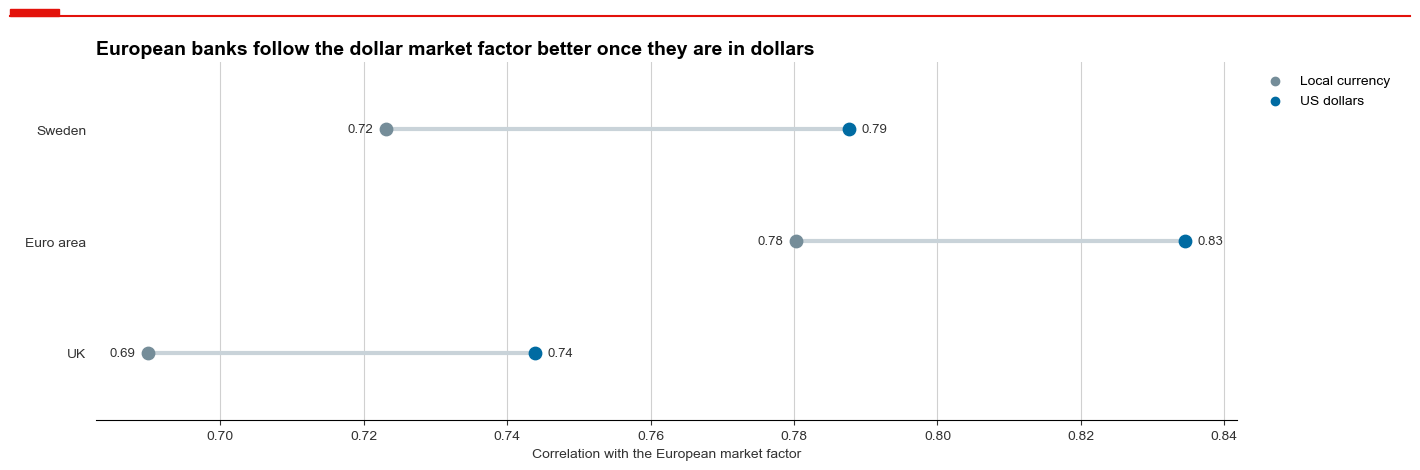

In [617]:
fig, ax = plt.subplots(figsize=(14, 4.5))

for position, region in enumerate(market_fit.index):
    local, dollars = market_fit.loc[region]
    ax.plot([local, dollars], [position, position], color=LIGHT_GREY, lw=3)
    ax.scatter(local, position, color=GREY, s=80, zorder=3)
    ax.scatter(dollars, position, color=ECONOMIST_COLORS[0], s=80, zorder=3)
    annotate(ax, f"{local:.2f}", (local, position), offset=(-9, 0))
    annotate(ax, f"{dollars:.2f}", (dollars, position), offset=(9, 0))

ax.scatter([], [], color=GREY, label="Local currency")
ax.scatter([], [], color=ECONOMIST_COLORS[0], label="US dollars")
ax.set_yticks(range(len(market_fit)), market_fit.index)
ax.set_ylim(-0.6, len(market_fit) - 0.4)
vertical_grid(ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_xlabel("Correlation with the European market factor")
ax.set_title("European banks follow the dollar market factor better "
             "once they are in dollars")
show()

**Comments – D2.11 and D2.12**
* **The factors fit our panel:** 2,893 days, the same days as our prices, no missing values, all in US dollars.

* **The risk free rate is small and the same for all:** both regions carry the same T-bill. It averages 0.40% a year, close to the 0.43% of the course file. The correlation is 0.878, because the factor files hold a one month rate through the month, while the course file moves daily.

* **Markets differ, so each region needs its own:** the market returns 8.9% a year in North America and 3.5% in Europe, and momentum −0.3% against 6.5%.

* **The conversion pays off:** the correlation with the European market rises in all three regions (0.69 to 0.74 in the UK, 0.78 to 0.83 in the euro area, 0.72 to 0.79 in Sweden). So we measure bank and market in the same currency, and Task #4 should give cleaner betas, despite the higher volatility of D2.10.

### D2.13 The panel
We now join everything into the panel of the slide: bank returns in dollars, market return, risk free rate and factors. US banks get the North American factors, all other banks the European ones. We also keep `usd_returns`, with one column per bank, because Task #4 runs one regression per bank.

In [618]:
FACTOR_COLUMNS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "WML", "RF", "market"]

# Long format, one row per region and day, for the merge below
all_factors = pd.concat({"North America": factors_north_america,
                         "Europe": factors_europe},
                        names=["factor_region", "date"])
all_factors = all_factors[FACTOR_COLUMNS].reset_index()

panel = usd_returns.stack().rename("usd_return")
panel = panel.rename_axis(["date", "bank"]).reset_index()
panel["region"] = panel["bank"].map(bank_region)
# All banks outside the US use the European factors
panel["factor_region"] = np.where(panel["region"] == "US", "North America",
                                  "Europe")

panel = panel.merge(all_factors, on=["factor_region", "date"],
                    validate="many_to_one")
panel["excess_return"] = panel["usd_return"] - panel["RF"]

In [619]:
expected_rows = usd_returns.notna().sum().sum()
print(f"Panel: {len(panel):,} rows, {panel['bank'].nunique()} banks")
print("Rows lost in the merge:", expected_rows - len(panel))
print("Duplicated bank days:", panel.duplicated(["bank", "date"]).sum())
print("Missing values:", panel.isna().sum().sum())

Panel: 314,917 rows, 126 banks
Rows lost in the merge: 0
Duplicated bank days: 0
Missing values: 0


In [620]:
event_pairs = zip(events["date"], events["bank"])
on_holiday = sum(is_bank_holiday.at[date, bank] for date, bank in event_pairs)
print("Events dated on a holiday of their region:", on_holiday)

Events dated on a holiday of their region: 27


One row per bank and day:

In [621]:
panel.head()

,date,bank,usd_return,region,factor_region,Mkt-RF,SMB,HML,RMW,CMA,WML,RF,market,excess_return
0,2008-01-02,AAREAL BANK,0.0157,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,0.0156
1,2008-01-02,COMDIRECT BANK,0.0060,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,0.0059
2,2008-01-02,COMMERZBANK,-0.0116,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,-0.0117
3,2008-01-02,UMWELTBANK,0.0036,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,0.0035
4,2008-01-02,DEUTSCHE BANK,-0.0118,Euro area,Europe,-0.0012,0.0094,0.0020,-0.0037,0.0018,0.0003,0.0001,-0.0011,-0.0119


The whole panel in one chart: event banks, equally weighted, against their market, all in dollars with dividends.

In [622]:
LOG_LEVELS = [0.125, 0.25, 0.5, 1, 2]  # halves and doubles of $1


def growth_line(ax, daily_returns, color, label, shift=0):
    '''Draw the growth of $1 from daily returns, labelled at its end.'''
    # A holiday counts as no change
    growth = (1 + daily_returns.fillna(0)).cumprod()
    ax.plot(growth, color=color, lw=2)
    annotate(ax, f"${growth.iloc[-1]:.2f}  {label}",
             (growth.index[-1], growth.iloc[-1]), offset=(9, shift))

In [623]:
def format_growth_axis(ax, title):
    '''Set the log scale, the ticks and the title of a growth panel.'''
    ax.set_yscale("log")
    ax.set_yticks(LOG_LEVELS, labels=[f"${level:g}" for level in LOG_LEVELS])
    ax.minorticks_off()
    ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
    ax.set_xlim(right=pd.Timestamp("2023-06-30"))  # room for the labels
    ax.set_title(title, fontsize=12)

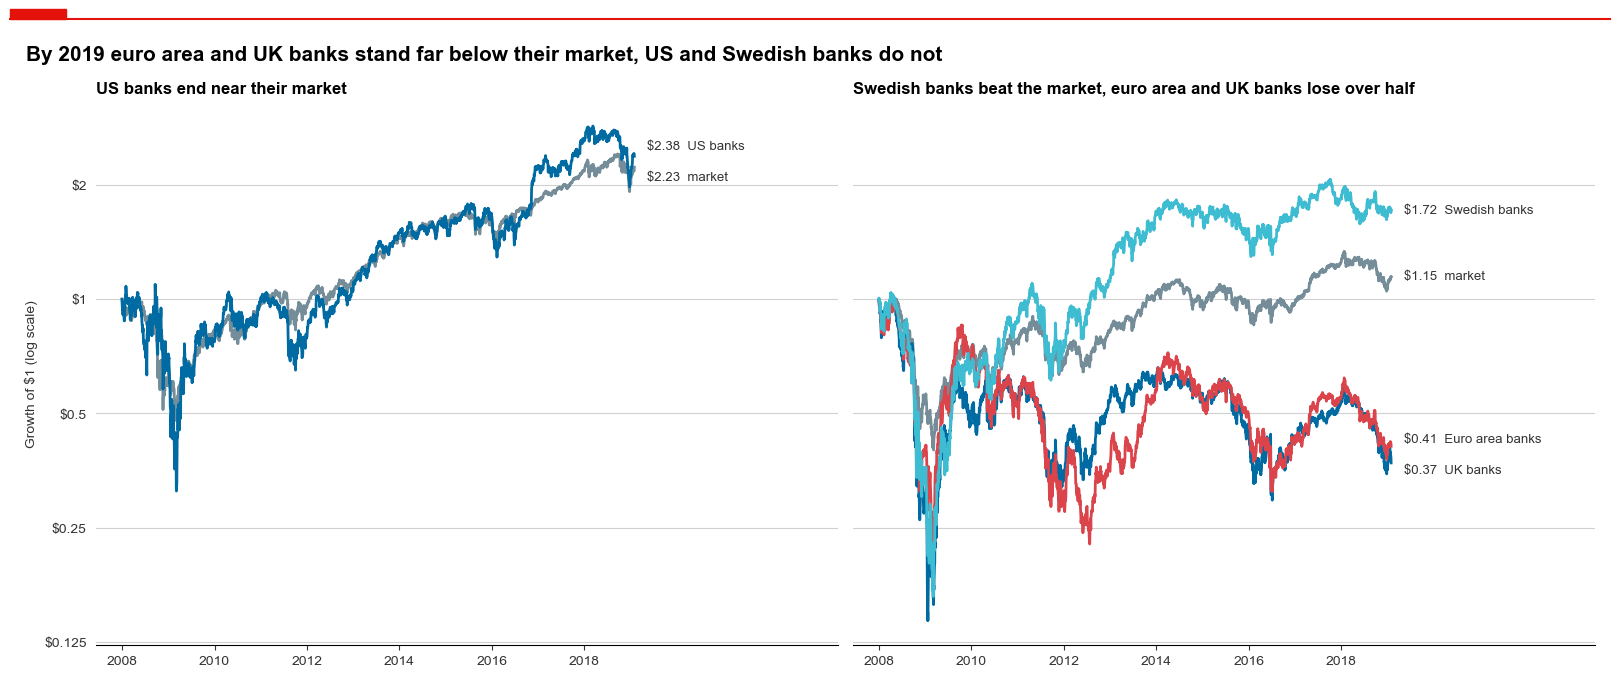

In [624]:
us_bank_average = region_average(usd_returns, "US")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)

growth_line(axes[0], factors_north_america["market"], GREY, "market", shift=-7)
growth_line(axes[0], us_bank_average, ECONOMIST_COLORS[0], "US banks", shift=7)
format_growth_axis(axes[0], "US banks end near their market")
axes[0].set_ylabel("Growth of $1 (log scale)")

growth_line(axes[1], factors_europe["market"], GREY, "market")
growth_line(axes[1], region_average(usd_returns, "UK"), ECONOMIST_COLORS[0],
            "UK banks", shift=-5)
growth_line(axes[1], region_average(usd_returns, "Euro area"),
            ECONOMIST_COLORS[8], "Euro area banks", shift=5)
growth_line(axes[1], region_average(usd_returns, "Sweden"),
            ECONOMIST_COLORS[1], "Swedish banks")
format_growth_axis(axes[1], "Swedish banks beat the market, euro area and "
                   "UK banks lose over half")
show("By 2019 euro area and UK banks stand far below their market, "
     "US and Swedish banks do not")

**Comments – D2.13**
* **The panel is complete:** 314,917 bank days on 126 banks, no row lost in the merge, no duplicate and no missing value.

* **Regions took very different paths:** $1 in 2008 ends at $2.38 in US event banks, against $2.23 for their market, and at $1.72 in Swedish banks, against $1.15 for the European market. Euro area banks end at $0.41 and UK banks at $0.37. These are equal weighted averages, and late listings join when they start trading.

* **So a bank's return must be judged against its own market,** which is why each region gets its own factors.

* **27 events are dated on a holiday of their region.** They stay in the table, and in Task #5 their day 0, the day from which we count the event window, becomes the next trading day.

* **One small mismatch remains:** after a holiday in one region, such as a UK bank holiday, the bank's return covers two days but the European factors only one. It happens on a few days a year, and we accept it.

* **Day 2 is complete:** `usd_returns` and `panel` hold returns in dollars without holidays, with market, risk free rate and factors. Task #4 starts from here.

## Task #4 – Estimate betas per event
To see an abnormal return, we need the normal one. For every event we estimate how the bank usually moves with the market, using only days long before the event. We use two models. The first is the market model of Krüger (2015), a regression of the raw bank return on the raw market return:

$$r_{i,t} = \alpha_i + \beta_i \, r_{M,t} + \varepsilon_{i,t}$$

Krüger also uses richer benchmarks, so we check the model against the five factors of Fama and French (2015) plus momentum, on excess returns:

$$r_{i,t} - r_{f,t} = \alpha_i + \beta_i (r_{M,t} - r_{f,t}) + s_i SMB_t + h_i HML_t + r_i RMW_t + c_i CMA_t + w_i WML_t + \varepsilon_{i,t}$$

All returns are in US dollars. US banks use the North American factors, all other banks the European ones. The slide writes the CAPM with the market excess return, while we use raw returns on both sides, as in equation (1) of Krüger (2015), so that our CARs compare directly with his. The slide also warns that the risk free rate differs between markets: all our returns are in US dollars, so the US T-bill fits every bank (D2.10).

### 4.1 The timing
The betas of an event on day $t$ come from the 250 trading days that end on day $t-50$, so the window runs from $t-299$ to $t-50$. They stay fixed for the whole event window $[t-10, t+10]$. The gap keeps news that leaks before the event out of the betas. We never use a window that ends later, because it would contain the event.

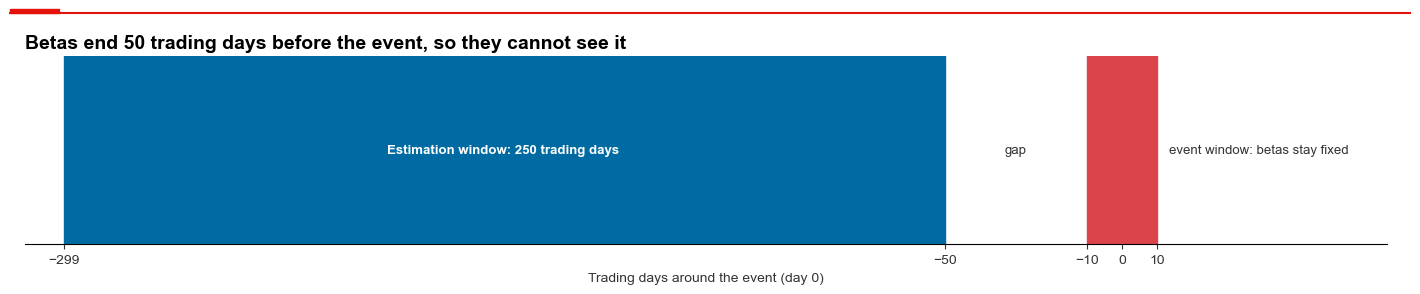

In [745]:
ESTIMATION_START, ESTIMATION_END = -299, -50    # days around day 0
EVENT_START, EVENT_END = -10, 10    # days around day 0

fig, ax = plt.subplots(figsize=(14, 2.8))
ax.axvspan(ESTIMATION_START, ESTIMATION_END, color=ECONOMIST_COLORS[0])
ax.axvspan(EVENT_START, EVENT_END, color=ECONOMIST_COLORS[8])
annotate(ax, "Estimation window: 250 trading days", (-175, 0.5), offset=(0, 0),
         color="white", fontweight="bold")
annotate(ax, "gap", (-30, 0.5), offset=(0, 0))
annotate(ax, "event window: betas stay fixed", (EVENT_END, 0.5), offset=(8, 0))

ax.set_xlim(-310, 75)  # room for the label
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xticks([ESTIMATION_START, ESTIMATION_END, EVENT_START, 0, EVENT_END])
ax.set_xlabel("Trading days around the event (day 0)")
ax.grid(False)
ax.set_title("Betas end 50 trading days before the event, so they cannot see it")
show()

Day 0 is the first trading day of the bank's region on or after the Sigwatch date. We count all windows in the trading days of that region.

In [626]:
trading_days = {}
for region in REGION_ORDER:
    trading_days[region] = holidays.index[~holidays[region]]


def first_trading_day(dates, calendar):
    '''Move each date to the first trading day on or after it.'''
    # searchsorted finds the first trading day on or after each date
    return calendar[calendar.searchsorted(dates)]


events["day_0"] = pd.NaT
for region, calendar in trading_days.items():
    is_region = event_region == region
    region_dates = events.loc[is_region, "date"]
    events.loc[is_region, "day_0"] = first_trading_day(region_dates, calendar)

moved = (events["day_0"] != events["date"]).sum()
same_bank_day = events.duplicated(["bank", "day_0"]).sum()
print(f"Events moved to the next trading day: {moved}")
print(f"Events sharing bank and day 0 after the move: {same_bank_day}")

Events moved to the next trading day: 27
Events sharing bank and day 0 after the move: 1


### 4.2 One rolling regression per bank
We run each model with windows of 120, 250 and 500 trading days. A window needs at least 80% valid returns, which is our rule of 200 returns in 250 days. Besides alpha and betas we keep the volatility of the residuals, which the BMP test of Task #6 needs.

In [627]:
GAP_DAYS = 50  # trading days, as in Krüger (2015)
WINDOWS = [120, 250, 500]  # trading days in an estimation window
BASE_WINDOW = 250  # as in Krüger (2015)
MIN_VALID_SHARE = 0.8  # 200 returns of 250
# The factor model
MODEL_FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "WML"]
BETA_MODELS = {"market": ["market"], "factors": MODEL_FACTORS}
BETA_NAMES = {"market": "Market model", "factors": "Five factors + momentum"}


def region_factors(region):
    '''Return the factors of a region on its trading days.'''
    table = factors_north_america if region == "US" else factors_europe
    return table.loc[trading_days[region]]

In [628]:
def model_data(bank, model):
    '''Return the dependent variable and the factors of one bank and model.'''
    region = bank_region[bank]
    factors = region_factors(region)
    y = usd_returns.loc[trading_days[region], bank]
    if model == "factors":
        y = y - factors["RF"]  # excess return, as in Fama and French
    return y, factors[BETA_MODELS[model]]

In [629]:
def rolling_estimates(bank, model, window):
    '''Run a rolling regression, with one row per last day of the window.'''
    y, factors = model_data(bank, model)
    min_valid = int(window * MIN_VALID_SHARE)
    # missing="drop": a gap in the returns does not end a window
    fit = RollingOLS(y, sm.add_constant(factors), window=window,
                     min_nobs=min_valid, missing="drop").fit()

    estimates = fit.params.rename(columns={"const": "alpha"})
    # Daily residual volatility, which the BMP test needs
    estimates["sigma"] = np.sqrt(fit.mse_resid)
    estimates["r2"] = fit.rsquared
    estimates["nobs"] = fit.nobs
    return estimates

In [630]:
# Event banks only: the other banks have no event to study
rolling = {}
for model in BETA_MODELS:
    for window in WINDOWS:
        rolling[model, window] = {bank: rolling_estimates(bank, model, window)
                                  for bank in event_banks}

print(f"Rolling regressions: {len(rolling) * len(event_banks)}")

Rolling regressions: 384


Now each event reads its estimates from the row of day $t$ after a shift of 50 trading days, which is the window ending on $t-50$.

In [631]:
def event_estimates(model, window):
    '''Read the estimates of every event from the window ending on t-50.'''
    tables = []
    for bank, group in events.groupby("bank"):
        # After the shift, row t holds the window that ended on t-50
        shifted = rolling[model, window][bank].shift(GAP_DAYS)
        table = shifted.reindex(group["day_0"])
        table.index = group.index
        tables.append(table)
    return pd.concat(tables).sort_index()


estimates = {}
for model, window in rolling:
    estimates[model, window] = event_estimates(model, window)

**Comments – 4.1 and 4.2**
* **Betas never use the event window:** the estimation window ends on $t-50$, 40 trading days before the event window starts on $t-10$.

* **Every event has its estimates:** 384 rolling regressions, for 64 banks, two models and three windows.

* **So one thing is left to prove, the timing itself,** which 4.3 does.

### 4.3 The timing safeguard
This is the check that must not fail. For 20 random events we run a direct regression on exactly the days of the estimation window, and compare it with the shifted rolling estimates, for both models and all three windows. Any difference stops the notebook. A check that cannot fail proves nothing, so we also confirm that it catches a window that ends one day too late.

In [632]:
CHECKED_EVENTS = 20  # events in the timing check


def window_days(event, window, gap=GAP_DAYS):
    '''List the trading days of an event's estimation window.'''
    calendar = trading_days[bank_region[event["bank"]]]
    day = calendar.get_loc(event["day_0"])
    last = day - gap
    # The last day of the window is included
    return calendar[last - window + 1:last + 1]


def direct_estimates(event, model, window, gap=GAP_DAYS):
    '''Estimate alpha and betas of one event by a direct regression.'''
    days = window_days(event, window, gap)
    y, factors = model_data(event["bank"], model)
    is_valid = y.loc[days].notna()
    valid_days = days[is_valid]
    return ols(y.loc[valid_days], factors.loc[valid_days]).params

In [633]:
def timing_failures(checked_events, gap=GAP_DAYS):
    '''Count the comparisons where direct and rolling estimates differ.'''
    failures = 0
    for index, event in checked_events.iterrows():
        for (model, window), table in estimates.items():
            columns = ["alpha", *BETA_MODELS[model]]
            rolling_values = table.loc[index, columns].values.astype(float)
            direct_values = direct_estimates(event, model, window, gap)
            failures += not np.allclose(direct_values, rolling_values)
    return failures

In [634]:
# Only events with estimates in both models and all windows
all_estimated = pd.concat([table["alpha"] for table in estimates.values()],
                          axis=1).notna().all(axis=1)
checked_events = events[all_estimated].sample(CHECKED_EVENTS, random_state=SEED)

failures = timing_failures(checked_events)
timing_checks = CHECKED_EVENTS * len(estimates)
if failures > 0:
    raise ValueError(f"Beta timing is wrong in {failures} comparisons")
print(f"Direct and rolling estimates equal: {timing_checks} of "
      f"{timing_checks}")

Direct and rolling estimates equal: 120 of 120


In [635]:
# Check of the check: a window ending on t-49 must be caught
caught = timing_failures(checked_events, gap=GAP_DAYS - 1)
print(f"A window one day too late is caught: {caught} of {timing_checks}")
if caught < timing_checks:
    raise ValueError("The timing check missed a window one day too late")

A window one day too late is caught: 120 of 120


Last, every window must end before the event window starts.

In [636]:
def ends_before_event_window(event):
    '''Check that the estimation window ends before day -10 of the event.'''
    calendar = trading_days[bank_region[event["bank"]]]
    first_event_day = calendar[calendar.get_loc(event["day_0"]) + EVENT_START]
    return window_days(event, BASE_WINDOW)[-1] < first_event_day


clean_timing = checked_events.apply(ends_before_event_window, axis=1)
print("All windows end before the event window:", clean_timing.all())

All windows end before the event window: True


**Comments – 4.3**
* **The timing is right:** all 120 comparisons (20 events, two models, three windows) match, and every window ends before the event window starts.

* **The check can fail:** it catches a window that ends one day too late in all 120 comparisons.

* **So no beta has seen its event.** Every number of Tasks #5 and #6 rests on this.

### 4.4 Which events have estimates?
A bank that was listed late has no estimation window for its early events. The longer the window, the more events we lose.

In [637]:
rows = []
for window in WINDOWS:
    table = estimates["market", window]
    rows.append({"window": window,
                 "minimum returns": int(window * MIN_VALID_SHARE),
                 "events with betas": table["alpha"].notna().sum(),
                 "events without": table["alpha"].isna().sum()})

coverage = pd.DataFrame(rows).set_index("window")
base_estimates = estimates["market", BASE_WINDOW]
lost_events = events.loc[base_estimates["alpha"].isna(), "bank"]
print(lost_events.value_counts().to_string())
coverage

bank
ABN AMRO BANK      43
NIBC HOLDING       16
BANKIA              9
UNICAJA BANCO       6
LIBERBANK           4
METRO BANK          3
VIRGIN MONEY UK     2


,minimum returns,events with betas,events without
window,,,
120,96,2559,72
250,200,2548,83
500,400,2540,91


Our rules also ask for three flags on the base window: other events of the same bank inside the estimation window, a daily move above 50%, and the share of zero returns.

In [638]:
LARGE_DAILY_MOVE = 0.5  # a daily move above 50%, up or down
# In local currency, because in dollars a stale price still moves
is_zero_return = (local_trading == 0).astype(float)
is_zero_return = is_zero_return.where(local_trading.notna())


def window_statistic(daily_values, statistic):
    '''Compute a statistic over the estimation window of every event.'''
    values = pd.Series(index=events.index, dtype=float)
    for bank, group in events.groupby("bank"):
        calendar = trading_days[bank_region[bank]]
        windows = daily_values.loc[calendar, bank].rolling(BASE_WINDOW,
                                                           min_periods=1)
        shifted = windows.agg(statistic).shift(GAP_DAYS)
        values[group.index] = shifted.reindex(group["day_0"]).values
    return values

In [639]:
def other_events_in_window(events):
    '''Count the other events of the same bank in each estimation window.'''
    counts = pd.Series(index=events.index, dtype=int)
    for bank, group in events.groupby("bank"):
        calendar = trading_days[bank_region[bank]]
        days = calendar.get_indexer(group["day_0"])
        ordered_days = np.sort(days)
        # First and last event of the bank inside each estimation window
        first = np.searchsorted(ordered_days, days - GAP_DAYS - BASE_WINDOW + 1)
        last = np.searchsorted(ordered_days, days - GAP_DAYS, side="right")
        counts[group.index] = last - first
    return counts


events["others_in_window"] = other_events_in_window(events)
events["largest_move"] = window_statistic(usd_returns.abs(), "max")
events["zero_share"] = window_statistic(is_zero_return, "mean")

In [640]:
has_betas = base_estimates["alpha"].notna()
usable = events[has_betas]
flagged_moves = usable[usable["largest_move"] > LARGE_DAILY_MOVE]

print(f"Events with betas: {len(usable):,}")
share_with_others = (usable["others_in_window"] > 0).mean()
print(f"Other events in the window: {share_with_others:.0%}, "
      f"median {usable['others_in_window'].median():.0f}")
print(f"Daily move above 50% in the window: {len(flagged_moves)}")
print(flagged_moves["bank"].value_counts().to_string())
print(f"Zero returns, median: {usable['zero_share'].median():.1%}")
print(f"Zero returns, largest: {usable['zero_share'].max():.1%}")
bank_zero_share = usable.groupby("bank")["zero_share"].mean()
print(bank_zero_share.nlargest(3).map("{:.3f}".format).to_string())

Events with betas: 2,548
Other events in the window: 95%, median 12
Daily move above 50% in the window: 4
bank
BANKIA                3
PERMANENT TSB GHG.    1
Zero returns, median: 0.8%
Zero returns, largest: 20.0%
bank
BANCA MONTE DEI PASCHI    0.120
AIB GROUP                 0.117
VAN LANSCHOT KEMPEN       0.105


What does one extreme day do to a beta? For the flagged events we compare the beta with the same regression without the days above 50%.

In [641]:
def beta_without_large_days(event):
    '''Estimate the market beta without the days above the large move.'''
    days = window_days(event, BASE_WINDOW)
    y, factors = model_data(event["bank"], "market")
    y = y.loc[days]
    keep = y.notna() & (y.abs() <= LARGE_DAILY_MOVE)
    return ols(y[keep], factors.loc[days][keep]).params[1]


flagged_betas = pd.DataFrame({
    "bank": flagged_moves["bank"],
    "day_0": flagged_moves["day_0"],
    "largest_move": flagged_moves["largest_move"],
    "with": base_estimates.loc[flagged_moves.index, "market"],
})
flagged_betas["without"] = [beta_without_large_days(event)
                            for index, event in flagged_moves.iterrows()]
beta_gap = flagged_betas["with"] - flagged_betas["without"]
print(f"Largest change of a beta: {beta_gap.abs().max():.2f}")
print(f"Median change of a beta: {beta_gap.abs().median():.2f}")

Largest change of a beta: 0.82
Median change of a beta: 0.73


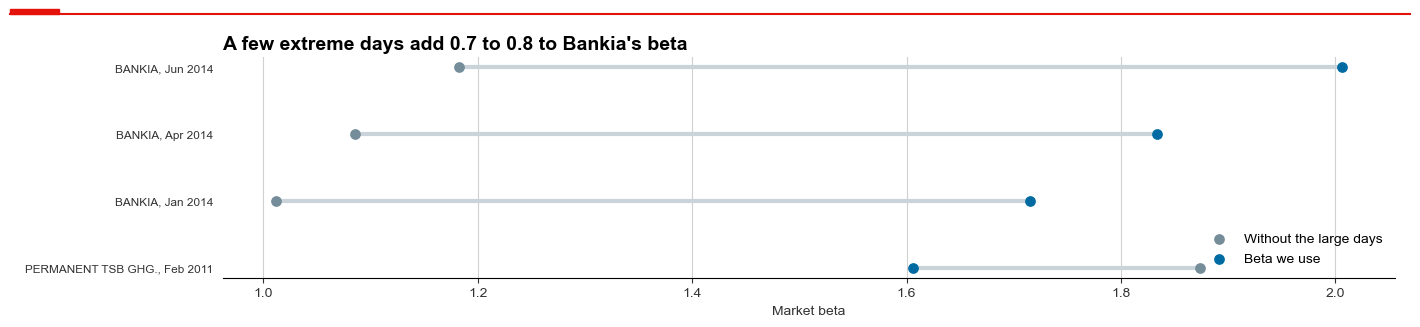

In [642]:
ordered = flagged_betas.sort_values("with").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 0.28 * len(ordered) + 2))
ax.hlines(ordered.index, ordered["without"], ordered["with"], color=LIGHT_GREY,
          lw=3)
ax.scatter(ordered["without"], ordered.index, color=GREY, s=45, zorder=3,
           label="Without the large days")
ax.scatter(ordered["with"], ordered.index, color=ECONOMIST_COLORS[0], s=45,
           zorder=3, label="Beta we use")
labels = [f"{row.bank}, {row.day_0:%b %Y}" for row in ordered.itertuples()]
ax.set_yticks(ordered.index, labels, fontsize=8.5)
ax.set_xlabel("Market beta")
vertical_grid(ax)
ax.legend(loc="lower right")
bankia_gap = beta_gap[flagged_betas["bank"] == "BANKIA"].abs()
ax.set_title(f"A few extreme days add {bankia_gap.min():.1f} to "
             f"{bankia_gap.max():.1f} to Bankia's beta")
show()

**Comments – 4.4**
* **Late listings cost 83 events at 250 days:** 2,548 of 2,631 events have betas. ABN AMRO loses 43, NIBC 16 and Bankia 9. The window hardly matters here, with 2,559 events at 120 days and 2,540 at 500.

* **We cannot avoid other campaigns:** 95% of events have another event of the same bank in their window, with a median of 12. Large banks are targeted all the time, so dropping these events would leave almost nothing. We keep the count in `others_in_window`.

* **Illiquidity is no problem for our banks:** the median event has 0.8% zero returns in its window, the largest 20.0%. Monte dei Paschi (12.0%), AIB (11.7%) and Van Lanschot (10.5%) stand highest on average.

* **Only four events have a daily move above 50% in their window:** three of Bankia and one of Permanent TSB. Without those days, Bankia's beta falls from about 1.7 to 2.0 to about 1.0 to 1.2, while Permanent TSB's rises. We keep the estimates. `largest_move` marks these events, and the winsorising of Task #6 limits their CARs.

### 4.5 Did bank risk change?
We follow the market beta of the event banks through time, with the 250 day window. Each date shows the window that ends there, and the band covers the middle half of a region's banks.

In [643]:
def region_betas(region):
    '''Collect the rolling market betas of a region's event banks.'''
    banks = region_event_banks(region)
    tables = rolling["market", BASE_WINDOW]
    return pd.DataFrame({bank: tables[bank]["market"] for bank in banks})


def plot_region_betas(ax, region):
    '''Show the median beta of a region, with the band and event dates.'''
    betas = region_betas(region)
    median = betas.median(axis=1)
    ax.fill_between(betas.index, betas.quantile(0.25, axis=1),
                    betas.quantile(0.75, axis=1), color=LIGHT_GREY)
    ax.plot(median, color=ECONOMIST_COLORS[0], lw=2)
    ax.axhline(1, color=ECONOMIST_RED, ls="--", lw=1)
    ax.axvline(COP21, color=DARK, ls="--", lw=1)
    ax.axvline(TRUMP, color=DARK, ls="--", lw=1)
    ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
    ax.set_title(f"{region}: {betas.shape[1]} banks", fontsize=12)

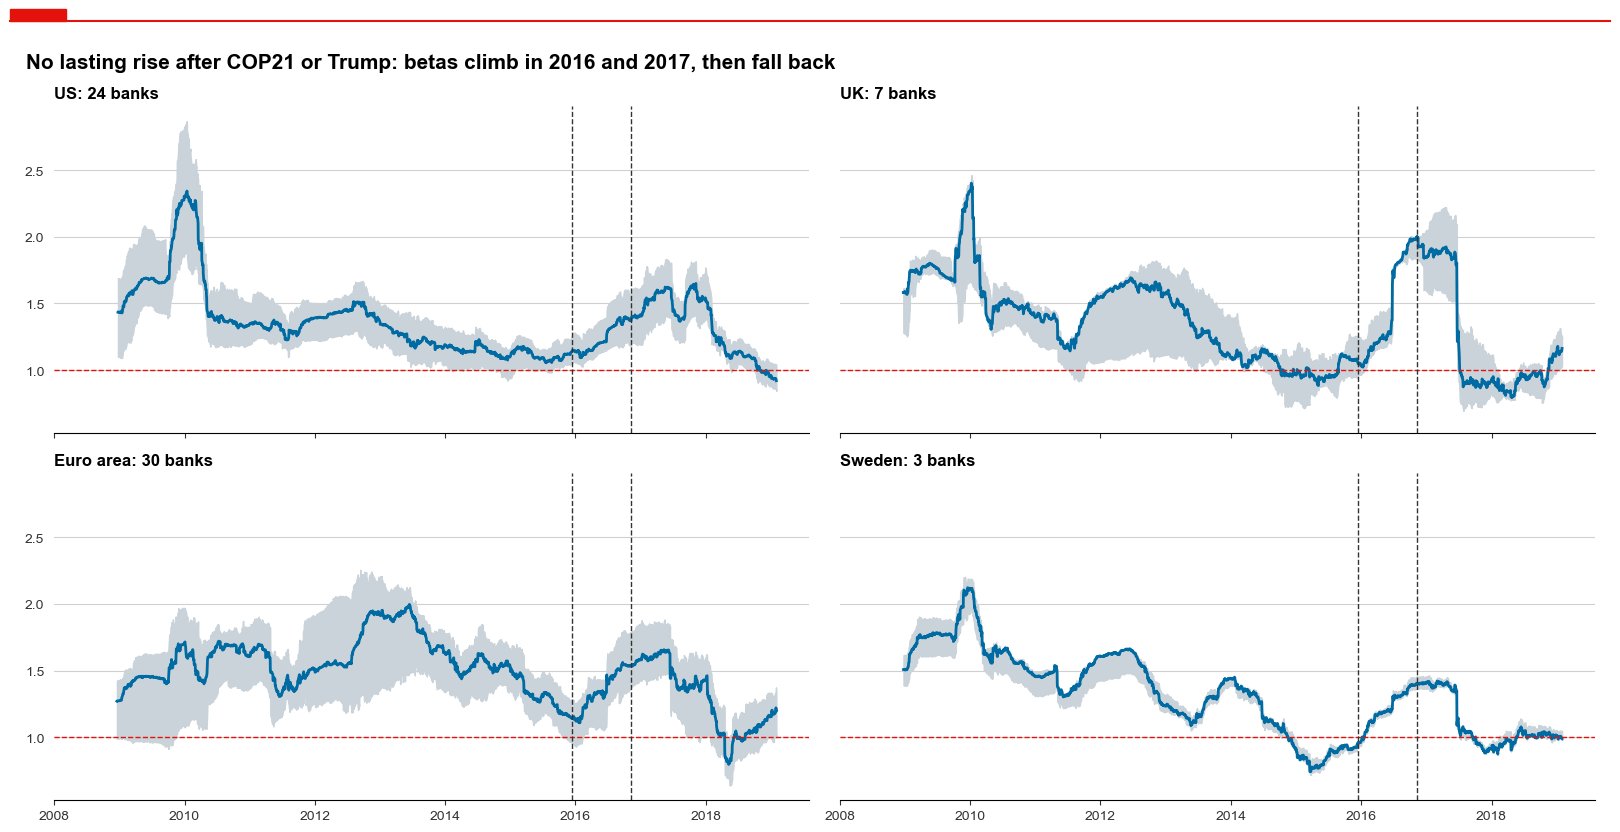

In [644]:
rows = []
for region in REGION_ORDER:
    median = region_betas(region).median(axis=1)
    rows.append({
        "2015": median.loc["2015"].mean(),
        "2017": median.loc["2017"].mean(),
        "2018": median.loc["2018"].mean(),
    })
beta_change = pd.DataFrame(rows, index=REGION_ORDER)

fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax, region in zip(axes.flat, REGION_ORDER):
    plot_region_betas(ax, region)
show("No lasting rise after COP21 or Trump: betas climb in 2016 and 2017, "
     "then fall back")

In [645]:
beta_change.style.format("{:.2f}")

,2015,2017,2018
US,1.11,1.53,1.14
UK,1.00,1.37,0.93
Euro area,1.30,1.50,1.06
Sweden,0.87,1.17,0.99


The sharp cliffs need an explanation. In the UK panel the beta jumps in June 2016 and falls in June 2017, and Sweden and the euro area move at the same time. We suspect the two trading days of the Brexit vote, 24 and 27 June 2016, which enter the window and leave it 250 trading days later. So we read the median beta around these dates. The moves of these days stay below 50%, so our flag does not see them.

In [646]:
MONTH_DAYS = 21  # trading days in a month


def vote_position(calendar):
    '''Find the first trading day of a region after the Brexit vote.'''
    return calendar.searchsorted(BREXIT)  # Sweden was closed on 24 June


rows = []
for region in EUROPEAN_REGIONS:
    median = region_betas(region).median(axis=1)
    calendar = trading_days[region]
    vote_day = vote_position(calendar)
    # The vote is the first day of this window, so it leaves on the next day
    last_with_vote = vote_day + BASE_WINDOW - 1
    two_days_later = last_with_vote + 2  # both days of the vote have left
    rows.append({
        "before the vote": median.loc[calendar[vote_day - 1]],
        "last window with the vote": median.loc[calendar[last_with_vote]],
        "two days later": median.loc[calendar[two_days_later]],
        "a month later": median.loc[calendar[two_days_later + MONTH_DAYS]],
    })

brexit_effect = pd.DataFrame(rows, index=EUROPEAN_REGIONS)
brexit_effect.style.format("{:.2f}")

,before the vote,last window with the vote,two days later,a month later
UK,1.37,1.80,1.32,0.95
Euro area,1.34,1.62,1.44,1.43
Sweden,1.21,1.35,1.11,1.08


In [647]:
in_brexit_window = pd.Series(False, index=events.index)
for region in EUROPEAN_REGIONS:
    calendar = trading_days[region]
    vote_day = vote_position(calendar)
    is_region = event_region == region
    days = calendar.get_indexer(events.loc[is_region, "day_0"])
    # The vote lies in the window if it starts before and ends after the vote
    in_brexit_window[is_region] = (days - GAP_DAYS >= vote_day) & (
        days + ESTIMATION_START <= vote_day)

events["brexit_in_window"] = in_brexit_window
print("Events with the vote in their window:", in_brexit_window.sum())
print(events.loc[in_brexit_window, "country_group"].value_counts().to_string())

Events with the vote in their window: 301
country_group
Euro area    191
UK            76
Sweden        34


**Comments – 4.5**
* **No lasting rise in bank risk:** from 2015 to 2018 the median beta stays near 1.1 in the US (1.11 to 1.14) and near 1 in the UK (1.00 to 0.93) and Sweden (0.87 to 0.99), and it falls in the euro area (1.30 to 1.06). In between it climbs, to 1.53 in the US and 1.50 in the euro area in 2017. So we see no lasting change after COP21 or the Trump election, and we would write "after", not "because of".

* **In Europe part of that climb is two days:** when 24 and 27 June 2016 leave the window, the UK beta falls from 1.80 to 1.32, about its level before the vote (1.37). The euro area falls from 1.62 to 1.44 and Sweden from 1.35 to 1.11. Sweden was closed on the day of the result, so its reaction came on the Monday.

* **Other days count too:** a month later the UK beta stands at 0.95, so the two days are not the whole fall.

* **Our 50% flag misses this,** because these moves stay below 50%. 301 events have the vote in their window (191 euro area, 76 UK, 34 Sweden), and `brexit_in_window` marks them. We keep their betas, but they are higher than normal, so we expect noisier abnormal returns for these events.

### 4.6 Market model against five factors plus momentum
We compare the two models on the betas of our events. If the simple model were enough, the dots would lie on the 45 degree line and the extra factors would add little.

In [648]:
BETA_LIMITS = [0, 3]  # beta axis, which holds nearly all events
market_table = estimates["market", BASE_WINDOW][has_betas]
factor_table = estimates["factors", BASE_WINDOW][has_betas]


def plot_45_degree(ax, limits):
    '''Draw the 45 degree line between the two limits.'''
    ax.plot(limits, limits, color=ECONOMIST_RED, ls="--",
            label="45 degree line")


def plot_model_betas(ax, market_table, factor_table):
    '''Compare the market betas of the two models, event by event.'''
    for region in REGION_ORDER:
        is_region = event_region[has_betas] == region
        ax.scatter(market_table.loc[is_region, "market"],
                   factor_table.loc[is_region, "Mkt-RF"], s=10, alpha=0.5,
                   label=region)
    plot_45_degree(ax, BETA_LIMITS)
    ax.set_xlim(BETA_LIMITS)
    ax.set_ylim(BETA_LIMITS)
    ax.set_xlabel("Beta, market model")
    ax.set_ylabel("Beta on Mkt-RF, five factors + momentum")
    ax.legend(loc="upper left")

In [649]:
BAR_SHIFT = 0.2  # two bars side by side around each tick
BAR_WIDTH = 0.38


def plot_model_fit(ax, market_table, factor_table):
    '''Show the average fit of the two models per region.'''
    fit = pd.DataFrame({"Market model": market_table["r2"],
                        "Five factors + momentum": factor_table["r2"]})
    means = fit.groupby(event_region[has_betas]).mean().loc[REGION_ORDER]
    positions = np.arange(len(means))

    for shift, column, color in [(-BAR_SHIFT, "Market model", GREY),
                                 (BAR_SHIFT, "Five factors + momentum",
                                  ECONOMIST_COLORS[0])]:
        bars = ax.bar(positions + shift, means[column], width=BAR_WIDTH,
                      color=color, label=column)
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9.5, color=DARK)

    ax.set_xticks(positions, means.index)
    ax.set_ylabel("Average R²")
    ax.legend(loc="upper right")

In [650]:
beta_gap_models = factor_table["Mkt-RF"] - market_table["market"]
beta_correlation = factor_table["Mkt-RF"].corr(market_table["market"])

print(f"Correlation of the betas: {beta_correlation:.2f}")
print(f"Mean gap, factors minus market: {beta_gap_models.mean():+.2f}")
print(f"Median residual volatility, market model: "
      f"{market_table['sigma'].median():.2%} a day")
print(f"Median residual volatility, factors: "
      f"{factor_table['sigma'].median():.2%} a day")

Correlation of the betas: 0.51
Mean gap, factors minus market: -0.36
Median residual volatility, market model: 1.29% a day
Median residual volatility, factors: 1.09% a day


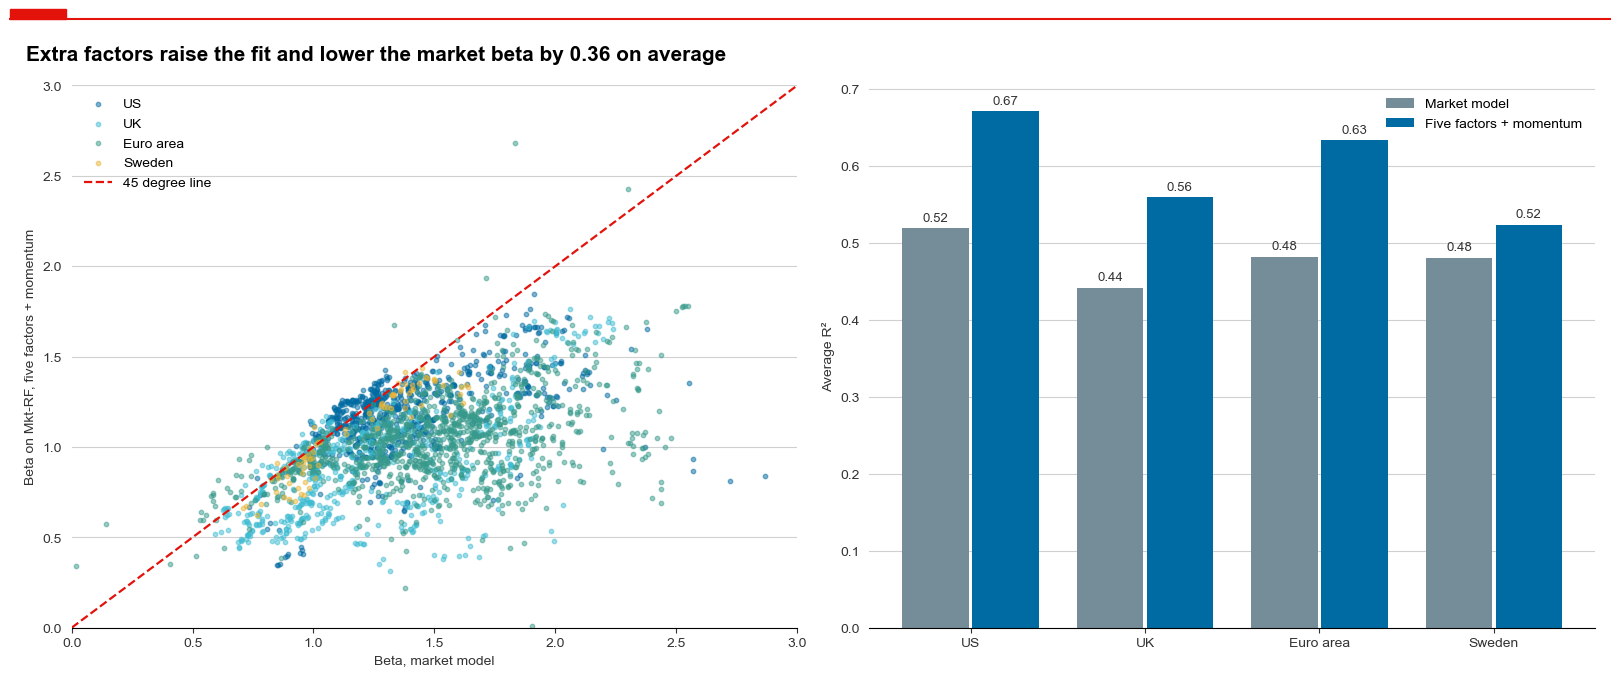

In [651]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_model_betas(axes[0], market_table, factor_table)
plot_model_fit(axes[1], market_table, factor_table)
show(f"Extra factors raise the fit and lower the market beta by "
     f"{-beta_gap_models.mean():.2f} on average")

The five extra loadings show what the market model leaves out. We average them per group, with 95% intervals. Events of one bank share much of their window, so we first average per bank and treat each bank as one observation.

In [652]:
LOADINGS = ["SMB", "HML", "RMW", "CMA", "WML"]
is_us_event = event_region[has_betas] == "US"


def mean_loadings(table):
    '''Average the loadings per bank, then across banks, with intervals.'''
    per_bank = table.groupby(events.loc[table.index, "bank"])[LOADINGS].mean()
    half_width = Z_95 * per_bank.std() / np.sqrt(len(per_bank))
    return per_bank.mean(), half_width

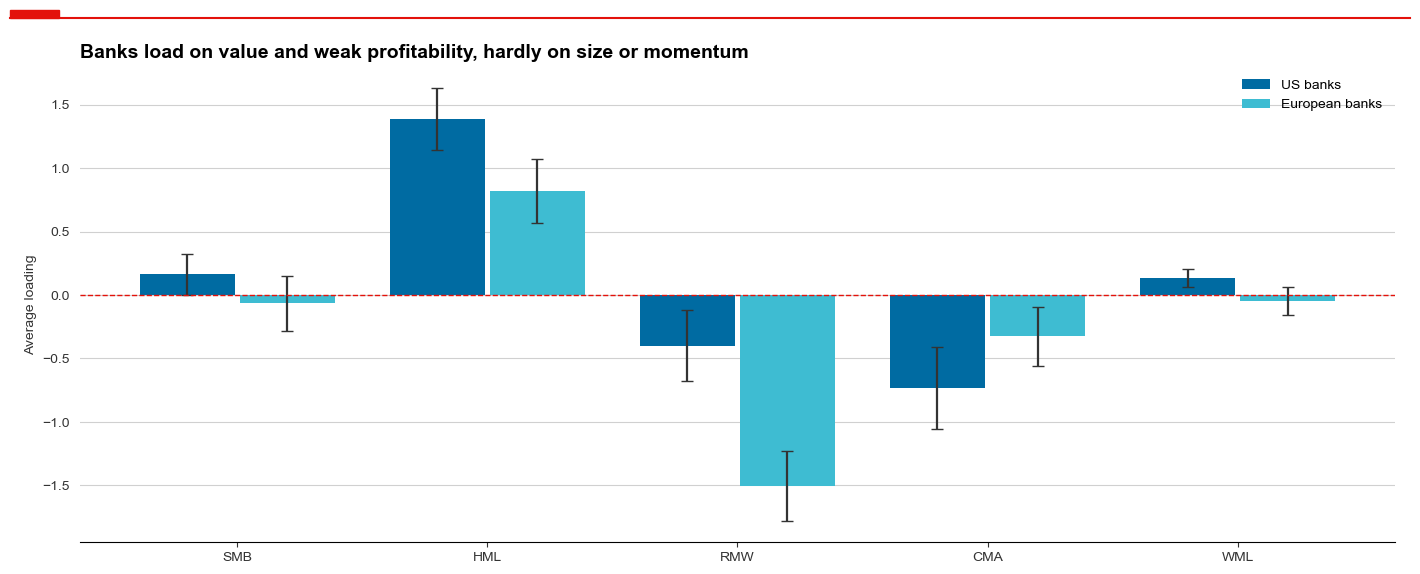

In [653]:
us_mean, us_width = mean_loadings(factor_table[is_us_event])
europe_mean, europe_width = mean_loadings(factor_table[~is_us_event])
positions = np.arange(len(LOADINGS))

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.bar(positions - BAR_SHIFT, us_mean, width=BAR_WIDTH, yerr=us_width,
       capsize=4, color=ECONOMIST_COLORS[0], ecolor=DARK, label="US banks")
ax.bar(positions + BAR_SHIFT, europe_mean, width=BAR_WIDTH, yerr=europe_width,
       capsize=4, color=ECONOMIST_COLORS[1], ecolor=DARK,
       label="European banks")
ax.axhline(0, color=ECONOMIST_RED, ls="--", lw=1)
ax.set_xticks(positions, LOADINGS)
ax.set_ylabel("Average loading")
ax.legend(loc="upper right")
ax.set_title("Banks load on value and weak profitability, hardly on size or "
             "momentum")
show()

In [654]:
loadings = pd.DataFrame({"US": us_mean, "Europe": europe_mean})
print(loadings.map("{:.2f}".format).to_string())

        US Europe
SMB   0.16  -0.06
HML   1.39   0.82
RMW  -0.40  -1.51
CMA  -0.74  -0.33
WML   0.13  -0.05


**Comments – 4.6**
* **The extra factors explain much more:** average R² rises from 0.52 to 0.67 in the US, 0.44 to 0.56 in the UK and 0.48 to 0.63 in the euro area, and less in Sweden (0.48 to 0.52). The daily residual volatility falls from 1.29% to 1.09%.

* **The market beta itself changes:** the two betas correlate at only 0.51, and the factor model's is 0.36 lower on average. A market model gives the market credit for exposures that belong to other factors.

* **Banks are not just market bets:** they load strongly on value (HML 1.39 in the US, 0.82 in Europe) and negatively on profitability (RMW −0.40 and −1.51) and investment (CMA −0.74 and −0.33). Size and momentum matter little (SMB 0.16 and −0.06, WML 0.13 and −0.05).

* **So the extra factors matter for the fit.** Whether it changes the answer is a different question: Task #5 computes abnormal returns with both models, and we compare them there.

### 4.7 Does the window change the picture?
We report all three windows and choose none by fit. The left panel shows one bank, the right panel all events against the base window.

In [655]:
def plot_window_lines(ax, bank):
    '''Show the rolling market beta of one bank for all three windows.'''
    # The base window stands out, the short one stays in the background
    colors = {120: LIGHT_GREY, 250: ECONOMIST_COLORS[0],
              500: ECONOMIST_COLORS[3]}
    for window, color in colors.items():
        ax.plot(rolling["market", window][bank]["market"], color=color,
                label=f"{window} days")
    ax.axvline(COP21, color=DARK, ls="--", lw=1)
    ax.axvline(TRUMP, color=DARK, ls="--", lw=1)
    ax.set_xticks(YEAR_TICKS, YEAR_TICKS.year)
    ax.set_ylabel("Market beta")
    ax.legend(loc="lower left", ncol=3)

In [656]:
def plot_window_scatter(ax, base, other, color, label):
    '''Compare the event betas of one window with the base window.'''
    ax.scatter(base, other, s=8, alpha=0.4, color=color, label=label)


base_beta = estimates["market", BASE_WINDOW]["market"]
rows = []
for window in WINDOWS:
    other = estimates["market", window]["market"]
    both = base_beta.notna() & other.notna()
    rows.append({
        "window": window,
        "events": both.sum(),
        "correlation with 250 days": base_beta[both].corr(other[both]),
        "mean absolute gap": (other[both] - base_beta[both]).abs().mean(),
        "sd of betas": other[both].std(),
    })
window_table = pd.DataFrame(rows).set_index("window")
window_table.style.format({"correlation with 250 days": "{:.2f}",
                           "mean absolute gap": "{:.2f}",
                           "sd of betas": "{:.2f}"})

,events,correlation with 250 days,mean absolute gap,sd of betas
window,,,,
120,2548,0.86,0.15,0.40
250,2548,1.00,0.00,0.38
500,2540,0.79,0.18,0.34


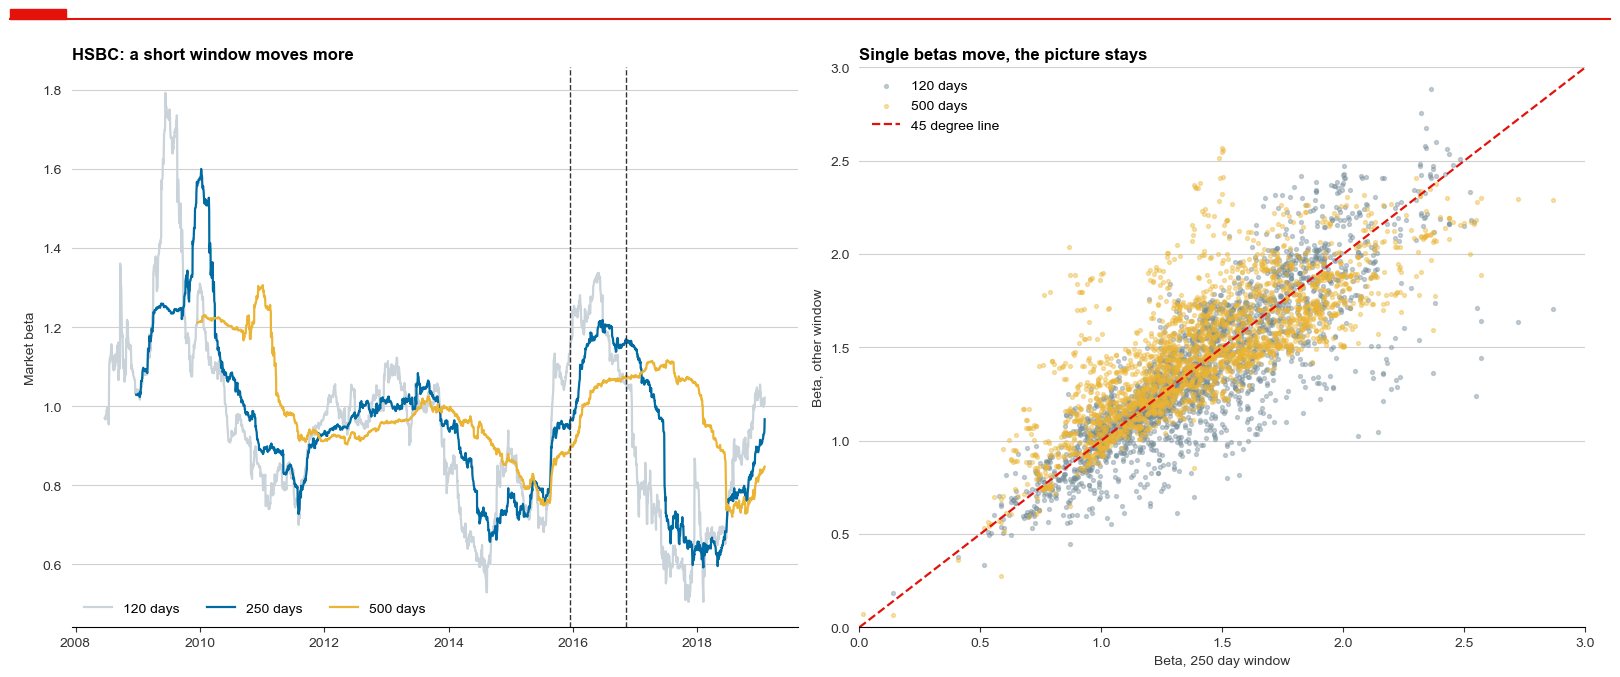

In [657]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
plot_window_lines(axes[0], BANK_EXAMPLE)
axes[0].set_title("HSBC: a short window moves more", fontsize=12)

plot_window_scatter(axes[1], base_beta, estimates["market", 120]["market"],
                    GREY, "120 days")
plot_window_scatter(axes[1], base_beta, estimates["market", 500]["market"],
                    ECONOMIST_COLORS[3], "500 days")
plot_45_degree(axes[1], BETA_LIMITS)
axes[1].set_xlim(BETA_LIMITS)
axes[1].set_ylim(BETA_LIMITS)
axes[1].set_xlabel("Beta, 250 day window")
axes[1].set_ylabel("Beta, other window")
axes[1].legend(loc="upper left")
axes[1].set_title("Single betas move, the picture stays", fontsize=12)
show()

**Comments – 4.7**
* **The window moves single betas by 0.15 to 0.18 on average:** the correlation with the 250 day window is 0.86 at 120 days and 0.79 at 500 days.

* **Short windows react faster and are noisier:** the standard deviation of the betas is 0.40 at 120 days, 0.38 at 250 and 0.34 at 500. HSBC shows both effects (left).

* **The picture stays:** the dots lie around the 45 degree line (right). We keep 250 days as our base, as in Krüger (2015), because no window is chosen by fit, and we report the other two.

**Result of Task #4.** `estimates` holds, for each of the two models and three windows, the alpha, betas, residual volatility, R² and number of returns of every event, and `events` holds day 0 and the flags. No beta has seen its event. Task #5 now turns these estimates into abnormal returns.

## Task #5 – Abnormal returns and CARs
The abnormal return of a bank on a day is what it earned beyond its normal return, predicted with the betas of Task #4. The cumulative abnormal return (CAR) adds these up over a window around the event:

$$AR_{i,t} = r_{i,t} - \hat{r}_{i,t}, \qquad CAR_i = \sum_{t=t_1}^{t_2} AR_{i,t}$$

For the market model the prediction is $\hat{\alpha}_i + \hat{\beta}_i r_{M,t}$, for the factor model the same on excess returns with all six factors. The betas stay fixed over the event window.

### 5.1 Merge events and returns
Our key is the bank and day 0. No event may get lost by accident, so we count every step and give a reason for each event we drop.

**Two events on the same bank and day.** HSBC has an event on 30 May 2011, a UK bank holiday, and one on 31 May, so both have the same day 0. Their event windows are the same 21 days, and counting them twice would count the same returns twice. Both are negative, so we count this window once, with the rule of Day 1: the worst sentiment and the highest prominence, and both NGOs in `n_ngos`.

In [658]:
same_window = events[events.duplicated(["bank", "day_0"], keep=False)]
# Both NGOs count, which merge_rows alone would lose
ngos_per_window = events.groupby(["bank", "day_0"])["n_ngos"].transform("sum")

unique_events = merge_rows(events, ["bank", "day_0"]).sort_index()
unique_events["n_ngos"] = ngos_per_window.loc[unique_events.index]
unique_events = unique_events.reset_index(names="event_id")

shown = ["bank", "date", "day_0", "sentiment", "prominence", "ngo"]
print(f"Events: {len(events):,} to {len(unique_events):,}")
same_window[shown]

Events: 2,631 to 2,630


,bank,date,day_0,sentiment,prominence,ngo
225,HSBC HOLDINGS,2011-05-30,2011-05-31,-2,4,UK Uncut
227,HSBC HOLDINGS,2011-05-31,2011-05-31,-1,3,IDEC Instituto Brasileiro de Defesa do Consumidor


Now the merge with the panel. An event without a row on day 0 has no return that day, because its bank was not listed yet.

In [659]:
day_zero_rows = panel[["bank", "date"]].rename(columns={"date": "day_0"})

# _merge shows which events found a return on day 0
merged_events = unique_events.merge(day_zero_rows, on=["bank", "day_0"], how="left", indicator=True, validate="many_to_one")
print(merged_events["_merge"].value_counts().to_string())
print("Rows after the merge:", len(merged_events))

_merge
both          2563
left_only       67
right_only       0
Rows after the merge: 2630


In [660]:
market_estimates = estimates["market", BASE_WINDOW]
factor_estimates = estimates["factors", BASE_WINDOW]

has_day_zero = merged_events["_merge"] == "both"
event_ids = merged_events["event_id"]
has_market_betas = market_estimates["alpha"].reindex(event_ids).notna().values
has_factor_betas = factor_estimates["alpha"].reindex(event_ids).notna().values
# Both models must exist, so that they use the same events
has_estimates = has_market_betas & has_factor_betas

print("Events with a return on day 0:", has_day_zero.sum())
print("Events with betas in both models:", has_estimates.sum())

Events with a return on day 0: 2563
Events with betas in both models: 2547


### 5.2 The event window
For every event we list the 21 trading days from −10 to +10 of its region, and read the returns and factors of each day from the panel. We require a return on every day of the window.

In [661]:
PANEL_COLUMNS = ["bank", "date", "usd_return", "excess_return",
                 *MODEL_FACTORS, "market"]


def window_rows(region_events, calendar):
    '''List the 21 trading days around each event of one region.'''
    positions = calendar.get_indexer(region_events["day_0"])
    tables = []
    for day in range(EVENT_START, EVENT_END + 1):
        tables.append(pd.DataFrame({
            "event_id": region_events["event_id"].values,
            "bank": region_events["bank"].values,
            "day": day,
            "date": calendar[positions + day],
        }))
    return pd.concat(tables, ignore_index=True)

In [662]:
estimated_events = merged_events[has_estimates]
estimated_region = estimated_events["bank"].map(bank_region)

tables = []
for region, calendar in trading_days.items():
    region_events = estimated_events[estimated_region == region]
    tables.append(window_rows(region_events, calendar))

event_days = pd.concat(tables, ignore_index=True)
event_days = event_days.merge(panel[PANEL_COLUMNS], on=["bank", "date"],
                              how="left", indicator=True,
                              validate="many_to_one")

# A complete window has a return on all 21 trading days of its region
returns_in_window = event_days["usd_return"].notna().groupby(
    event_days["event_id"]).sum()
window_length = EVENT_END - EVENT_START + 1
incomplete = returns_in_window[returns_in_window < window_length]

print(f"Event days: {len(event_days):,}")
print(f"Events with an incomplete window: {len(incomplete)}")

Event days: 53,487
Events with an incomplete window: 0


Every event now has its fate. Here is the count, and the full list of what we drop.

In [663]:
has_full_window = event_ids.isin(returns_in_window.index) & ~event_ids.isin(
    incomplete.index)
# The first condition that holds gives the reason
reasons = np.select(
    [~has_day_zero, ~has_estimates, ~has_full_window],
    ["not listed yet on day 0", "too little history for betas",
     "incomplete event window"],
    default="kept",
)
merged_events["reason"] = reasons

first_prices = merged_events["bank"].map(first_price)
merged_events["listed"] = first_prices
print(merged_events["reason"].value_counts().to_string())

reason
kept                            2547
not listed yet on day 0           67
too little history for betas      16


In [ ]:
dropped = merged_events[merged_events["reason"] != "kept"]
dropped = dropped.sort_values(["bank", "date"])
dropped_columns = ["bank", "date", "sign", "listed", "reason"]

dropped[dropped_columns].style.hide(axis="index").format({
    "date": "{:%d %b %Y}",
    "listed": "{:%d %b %Y}",
});     # please remove the semicolon to see the full list

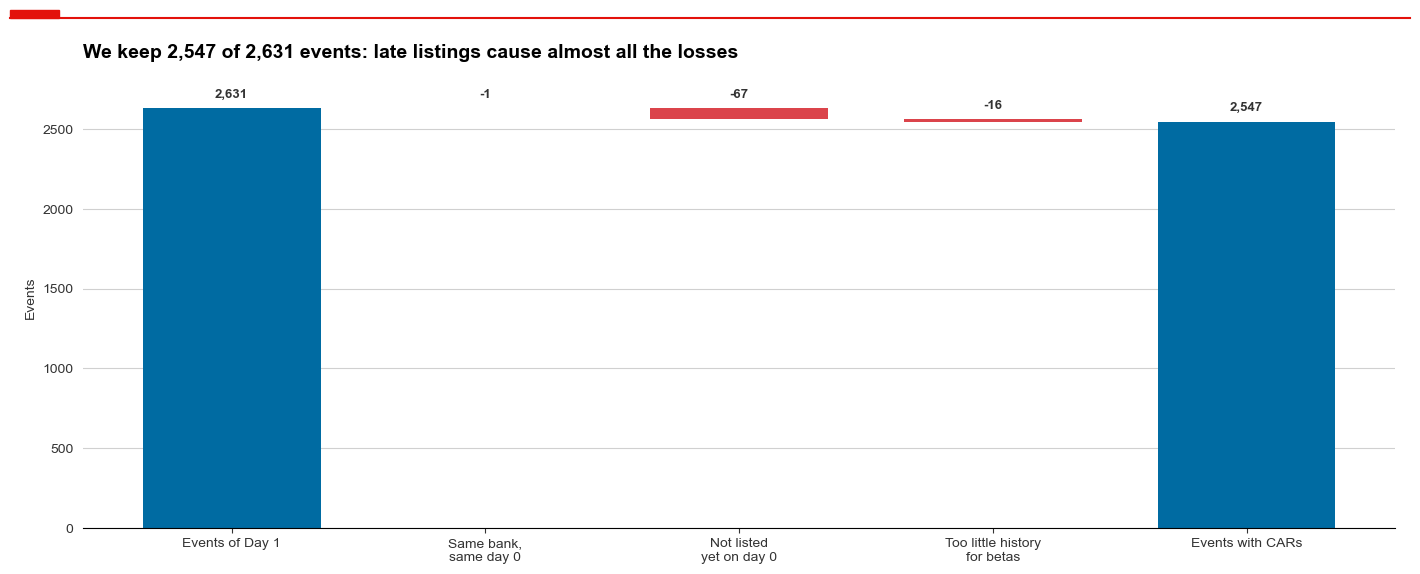

In [665]:
kept_events = merged_events[merged_events["reason"] == "kept"]
listed_events = (merged_events["reason"] != "not listed yet on day 0").sum()
event_counts_steps = [len(events), len(unique_events), listed_events,
                      len(kept_events)]
step_names_events = ["Same bank,\nsame day 0", "Not listed\nyet on day 0",
                     "Too little history\nfor betas"]

fig, ax = plt.subplots(figsize=(14, 5.5))
plot_waterfall(ax, event_counts_steps, step_names_events, "Events of Day 1",
               "Events with CARs")
ax.set_ylabel("Events")
ax.set_title(f"We keep {len(kept_events):,} of {len(events):,} events: "
             "late listings cause almost all the losses")
show()

**Comments – 5.1 and 5.2**
* **No event is lost by accident:** 2,631 events become 2,547. Of the 84 we lose, 67 fall before the bank was listed, 16 have too little history for betas, and one is the HSBC event we merge. The table `dropped` names each one. The 84 of D2.8 was a first count of a different set: it held 44 ABN AMRO events and not the HSBC merge.

* **Late listings explain the losses:** they cost 83 of the 84 events, led by ABN AMRO, NIBC and Bankia (Task #4).

* **The merge is clean:** 2,563 events find a return on day 0, 67 do not, and `validate` confirms one panel row per bank and day.

* **No window is incomplete:** every event with betas has a return on all 21 days.

### 5.3 Abnormal returns
The prediction uses the alpha and betas of each event, fixed over the window. We compute it for both models and for all three estimation windows, so that Task #6 can report them.

In [666]:
def abnormal_returns(event_days, model, window):
    '''Compute the abnormal return of every event day.'''
    columns = ["alpha", *BETA_MODELS[model]]
    # One event sits on 21 rows, so we use positions, not labels
    parameters = estimates[model, window].loc[event_days["event_id"], columns]
    alphas = parameters["alpha"].values
    betas = parameters[BETA_MODELS[model]].values
    factors = event_days[BETA_MODELS[model]].values

    predicted = alphas + (betas * factors).sum(axis=1)
    # The market model uses raw returns, the factor model excess returns
    return_column = "usd_return" if model == "market" else "excess_return"
    return event_days[return_column].values - predicted

In [667]:
kept_days = event_days[event_days["event_id"].isin(kept_events["event_id"])]
kept_days = kept_days.drop(columns="_merge").reset_index(drop=True)

for model, window in estimates:
    kept_days[f"ar_{model}_{window}"] = abnormal_returns(kept_days, model,
                                                         window)

AR_MARKET = f"ar_market_{BASE_WINDOW}"
AR_FACTORS = f"ar_factors_{BASE_WINDOW}"
print(f"Event days with abnormal returns: {len(kept_days):,}")
print(f"Mean AR, market model: {kept_days[AR_MARKET].mean():+.3%} a day")
print(f"Mean AR, factors: {kept_days[AR_FACTORS].mean():+.3%} a day")

Event days with abnormal returns: 53,487
Mean AR, market model: -0.020% a day
Mean AR, factors: -0.010% a day


We check the arithmetic with a second method: one event by hand, with a direct regression on its window and a plain loop over its days.

In [668]:
def car_by_hand(event, model):
    '''Compute the 21 day CAR of one event with a direct regression.'''
    parameters = direct_estimates(event, model, BASE_WINDOW)
    y, factors = model_data(event["bank"], model)
    calendar = trading_days[bank_region[event["bank"]]]
    day = calendar.get_loc(event["day_0"])

    car = 0
    for date in calendar[day + EVENT_START:day + EVENT_END + 1]:
        predicted = parameters[0] + (parameters[1:] * factors.loc[date]).sum()
        car += y.loc[date] - predicted
    return car

### 5.4 CARs over the four windows
We use four windows. Krüger (2015) reports $[-5, +5]$ and $[-10, +10]$, and the second is the baseline of the slide and of our tests. $[-10, -1]$ catches news before the Sigwatch date, a leak or a late record, and $[0, +10]$ the reaction from that date on. The last two add up to the baseline.

In [669]:
CAR_WINDOWS = {
    "[-5, +5]": (-5, 5),
    "[-10, +10]": (-10, 10),
    "[-10, -1]": (-10, -1),
    "[0, +10]": (0, 10),
}


def event_cars(kept_days, ar_column):
    '''Sum the abnormal returns of every event over the four windows.'''
    cars = {}
    for name, (first, last) in CAR_WINDOWS.items():
        in_window = kept_days["day"].between(first, last)
        days_in_window = kept_days[in_window]
        # min_count: a gap gives a missing CAR, not a smaller sum
        cars[name] = days_in_window.groupby("event_id")[ar_column].sum(
            min_count=last - first + 1)
    return pd.DataFrame(cars)

In [670]:
all_cars = {}
for model, window in estimates:
    all_cars[model, window] = event_cars(kept_days, f"ar_{model}_{window}")

market_cars = all_cars["market", BASE_WINDOW]
factor_cars = all_cars["factors", BASE_WINDOW]

# Check: the pre and post windows add up to the baseline
pre_and_post = market_cars["[-10, -1]"] + market_cars["[0, +10]"]
adds_up = np.allclose(pre_and_post, market_cars["[-10, +10]"])
print("Pre + post = baseline:", adds_up)

# Check: the same CAR by hand, for a few events
hand_events = kept_events.sample(5, random_state=SEED)
for model, table in [("market", market_cars), ("factors", factor_cars)]:
    by_hand = [car_by_hand(event, model)
               for index, event in hand_events.iterrows()]
    from_table = table.loc[hand_events["event_id"], "[-10, +10]"]
    print(f"Same by hand, {model}:", np.allclose(by_hand, from_table))

Pre + post = baseline: True
Same by hand, market: True
Same by hand, factors: True


Now the table for Task #6: one row per event, with both models, the volatility for the BMP test and every flag. 

Two flags are new:
 `overlap` marks an event whose window overlaps the previous one of the same bank, less than 21 trading days apart. `same_day_events` counts the events on the same day 0, whose abnormal returns move together.

In [671]:
def trading_days_since_last(group):
    '''Count the trading days since the previous event of the same bank.'''
    calendar = trading_days[bank_region[group["bank"].iloc[0]]]
    days = pd.Series(calendar.get_indexer(group["day_0"]), index=group.index)
    return days.sort_values().diff()

In [672]:
car_table = kept_events.set_index("event_id").drop(columns=["_merge", "reason"])
car_table["region"] = car_table["bank"].map(bank_region)

for name in CAR_WINDOWS:
    car_table[f"market {name}"] = market_cars[name]
    car_table[f"factors {name}"] = factor_cars[name]

car_table["sigma_market"] = market_estimates["sigma"]
car_table["sigma_factors"] = factor_estimates["sigma"]

gaps = [trading_days_since_last(group)
        for bank, group in car_table.groupby("bank")]
car_table["days_since_last"] = pd.concat(gaps)
# Closer than 21 days two windows share returns. A bank's first event has
# no gap, so it counts as no overlap
car_table["overlap"] = car_table["days_since_last"] < window_length
events_on_day = car_table.groupby("day_0")["bank"]
car_table["same_day_events"] = events_on_day.transform("size")

In [673]:
FLAGS = ["conflict_5_days", "brexit_in_window", "overlap"]

print(f"CAR table: {len(car_table):,} events, {car_table.shape[1]} columns")
print(car_table[FLAGS].sum().to_string())
print(f"Share of events overlapping: {car_table['overlap'].mean():.1%}")
print(f"Daily move above 50% in the window: "
      f"{(car_table['largest_move'] > LARGE_DAILY_MOVE).sum()}")
print(f"Events sharing day 0 with others: "
      f"{(car_table['same_day_events'] > 1).mean():.1%}")
print(car_table["sign"].value_counts().to_string())

CAR table: 2,547 events, 40 columns
conflict_5_days      199
brexit_in_window     297
overlap             1560
Share of events overlapping: 61.2%
Daily move above 50% in the window: 4
Events sharing day 0 with others: 85.4%
sign
negative    2076
positive     337
neutral      134


**Comments – 5.3 and 5.4**
* **The mean abnormal return is small on one day, but it adds up:** −0.020% a day in the market model and −0.010% with the factors. Over 21 days the market model's figure reaches −0.43%, and Task #6 tests whether this has anything to do with the events.

* **The arithmetic holds:** the pre and post windows add up to the baseline, and five events computed by hand match in both models.

* **The table is ready for Task #6:** 2,547 events (2,076 negative, 337 positive, 134 neutral) with both models, all four windows, the volatility for the BMP test and the flags.

* **Windows often overlap:** 1,560 events (61.2%) start less than 21 trading days after the previous event of the same bank, so one return can enter two CARs. Clustering by date does not remove this, so we read the intervals of Task #6 with care.

* **Events are not independent:** 85.4% share day 0 with another event, which is why we cluster by that date.

### 5.5 Extreme abnormal returns
A few days can move an average, so we look at them before we average anything.

In [674]:
TOP_DAYS = 12  # days in the table

ordered_days = kept_days[AR_MARKET].abs().sort_values(ascending=False)
largest_days = kept_days.loc[ordered_days.index[:TOP_DAYS]]
largest_days = largest_days.assign(sign=largest_days["event_id"].map(
    car_table["sign"]))
day_columns = ["bank", "date", "day", "sign", "usd_return", AR_MARKET]

largest_days[day_columns].style.hide(axis="index").format({
    "date": "{:%d %b %Y}",
    "usd_return": "{:+.1%}",
    AR_MARKET: "{:+.1%}",
})

bank,date,day,sign,usd_return,ar_market_250
BANKIA,23 May 2013,0,negative,-51.2%,-48.5%
BANKIA,20 May 2013,-3,negative,-45.6%,-45.9%
BANKIA,16 May 2013,-5,negative,+29.8%,+30.6%
BANKIA,31 May 2013,6,negative,+27.9%,+30.3%
BANKIA,30 Nov 2012,2,negative,-25.2%,-24.7%
BANKIA,22 May 2013,-1,negative,-24.4%,-23.5%
BANKIA,21 May 2013,-2,negative,-20.8%,-20.4%
SVB FINANCIAL GROUP,27 Apr 2018,0,negative,+18.7%,+18.7%
LLOYDS BANKING GROUP,24 Jun 2016,-6,negative,-27.3%,-17.8%
BANCA MONTE DEI PASCHI,29 Nov 2016,-8,negative,+17.9%,+17.3%


In [748]:
BASE_CAR = "market [-10, +10]"  # our baseline
TOP_CARS = 10  # events in the table

ordered_cars = car_table[BASE_CAR].abs().sort_values(ascending=False)
largest_cars = car_table.loc[ordered_cars.index[:TOP_CARS]]
car_columns = ["bank", "day_0", "sign", BASE_CAR, "factors [-10, +10]"]

largest_cars[car_columns].style.hide(axis="index").format({
    "day_0": "{:%d %b %Y}",
    BASE_CAR: "{:+.1%}",
    "factors [-10, +10]": "{:+.1%}",
})

bank,day_0,sign,"market [-10, +10]","factors [-10, +10]"
BANKIA,23 May 2013,negative,-138.4%,-141.6%
UNICREDIT,21 Dec 2011,negative,-53.8%,-44.4%
KBC GROUP,18 Jan 2012,negative,+40.3%,+25.3%
BANCA MONTE DEI PASCHI,09 Dec 2016,negative,-32.3%,-36.5%
ROYAL BANK OF SCTL.GP.,29 Apr 2010,negative,+31.8%,+28.0%
DEUTSCHE BANK,13 Oct 2016,negative,+30.4%,+16.5%
BANKINTER 'R',29 May 2012,negative,-30.0%,-33.3%
BARCLAYS,28 Oct 2016,negative,+29.9%,+14.9%
BANKIA,28 Nov 2012,negative,-27.8%,-28.3%
BANCO COMR.PORTUGUES 'R',15 Sep 2015,negative,-27.6%,-27.4%


How much do these events matter? We compare the mean with the median, and the mean without the ten largest CARs.

In [676]:
rows = []
for sign in ["negative", "positive"]:
    cars = car_table.loc[car_table["sign"] == sign, BASE_CAR]
    largest = cars.abs().sort_values(ascending=False).index[:TOP_CARS]
    rows.append({
        "events": len(cars),
        "mean": cars.mean(),
        "median": cars.median(),
        "mean without the 10 largest": cars.drop(largest).mean(),
        "standard deviation": cars.std(),
    })

car_summary = pd.DataFrame(rows, index=["negative", "positive"])
car_summary.style.format({"events": "{:,}", "mean": "{:+.2%}",
                          "median": "{:+.2%}",
                          "mean without the 10 largest": "{:+.2%}",
                          "standard deviation": "{:.2%}"})

,events,mean,median,mean without the 10 largest,standard deviation
negative,"2,076",-0.46%,-0.88%,-0.38%,7.72%
positive,337,-0.56%,-0.68%,-0.58%,6.07%


In [677]:
CAR_EDGE = 0.6  # CARs beyond 60% are shown at the edge of the chart
CAR_BINS = np.linspace(-CAR_EDGE, CAR_EDGE, 61)  # bins of 2 points


def plot_car_distribution(ax, car_table, column):
    '''Show the CARs of negative and positive events as densities.'''
    for sign in ["negative", "positive"]:
        values = car_table.loc[car_table["sign"] == sign, column]
        ax.hist(values.clip(-CAR_EDGE, CAR_EDGE), bins=CAR_BINS, density=True,
                alpha=0.6, color=SENTIMENT_COLORS[sign],
                label=sign.capitalize())
    ax.axvline(0, color=DARK, lw=0.8)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("CAR over [-10, +10], values beyond 60% shown at the edge")

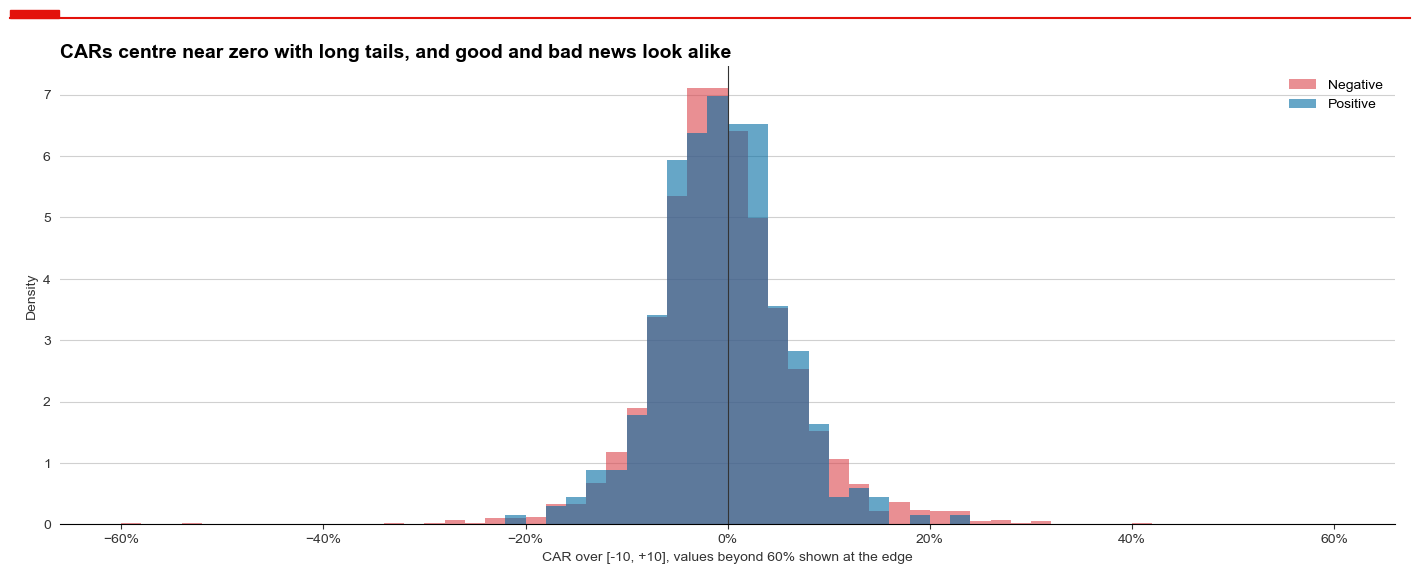

In [678]:
fig, ax = plt.subplots(figsize=(14, 5.5))
plot_car_distribution(ax, car_table, BASE_CAR)
ax.set_ylabel("Density")
ax.legend(loc="upper right")
ax.set_title("CARs centre near zero with long tails, and good and bad news "
             "look alike")
show()

**Comments – 5.5**
* **Bankia dominates the extremes:** it holds 7 of the 12 largest abnormal returns, all but one in May 2013, the month of its recapitalisation.

* **Its CAR of −138.4% is not a real loss:** a CAR adds up simple returns, so over a collapse it can pass −100%. The event stays, and the winsorising of Task #6 limits it.

* **The mean does not hang on a few events:** the negative mean is −0.46%, and −0.38% without the ten largest CARs. The positive mean is −0.56%, and −0.58% without them.

* **The median tells a little more:** −0.88% for negative events, against −0.68% for positive ones.

* **The largest days are not campaigns:** Lloyds lost 27.3% on the Brexit vote, and one return of Standard Chartered enters two events. We have no filter for other news, so the median and the sign test of Task #6 matter.

### 5.6 The average CAR path
This is our main figure: the average CAR, day by day from −10 to +10. On many days several events fall together and their abnormal returns move together, so we cluster the 95% band by day 0.

In [679]:
def clustered_mean(values, clusters):
    '''Compute a mean and its standard error, clustered by date.'''
    # statsmodels needs the clusters as numbers
    groups = pd.factorize(clusters)[0]
    # A regression on a constant alone gives the mean and its clustered error
    fit = sm.OLS(values, np.ones(len(values))).fit(
        cov_type="cluster", cov_kwds={"groups": groups})
    return fit.params[0], fit.bse[0]

In [680]:
def car_path(kept_days, ar_column, car_table, sign):
    '''Compute the average CAR of one sign for every day of the window.'''
    daily = kept_days.pivot(index="event_id", columns="day", values=ar_column)
    cumulative = daily.cumsum(axis=1)  # CAR from day -10 to each day

    events_of_sign = car_table[car_table["sign"] == sign]
    cumulative = cumulative.loc[events_of_sign.index]

    rows = {}
    for day in cumulative.columns:
        mean, error = clustered_mean(cumulative[day].values,
                                     events_of_sign["day_0"])
        rows[day] = {"mean": mean, "half_width": Z_95 * error}
    return pd.DataFrame(rows).T

In [681]:
def plot_car_path(ax, path, color, label, label_shift=0):
    '''Draw an average CAR path with its 95% band, labelled at its end.'''
    ax.fill_between(path.index, path["mean"] - path["half_width"],
                    path["mean"] + path["half_width"], color=color, alpha=0.2)
    ax.plot(path.index, path["mean"], color=color, lw=2)
    end = path.iloc[-1]
    annotate(ax, f"{end['mean']:+.2%}  {label}", (EVENT_END, end["mean"]),
             offset=(9, label_shift))

In [682]:
CAR_TICKS = np.arange(-0.015, 0.0101, 0.005)  # the same ticks on all CAR panels


def format_car_axis(ax, title):
    '''Set the lines, ticks and title of a CAR path panel.'''
    ax.axhline(0, color=DARK, lw=0.8)
    ax.axvline(0, color=DARK, ls="--", lw=1)
    ax.set_yticks(CAR_TICKS)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_xticks(range(EVENT_START, EVENT_END + 1, 5))
    ax.set_xlim(EVENT_START, EVENT_END + 7)  # room for the labels
    ax.set_xlabel("Trading days around the event")
    ax.set_title(title, fontsize=12)

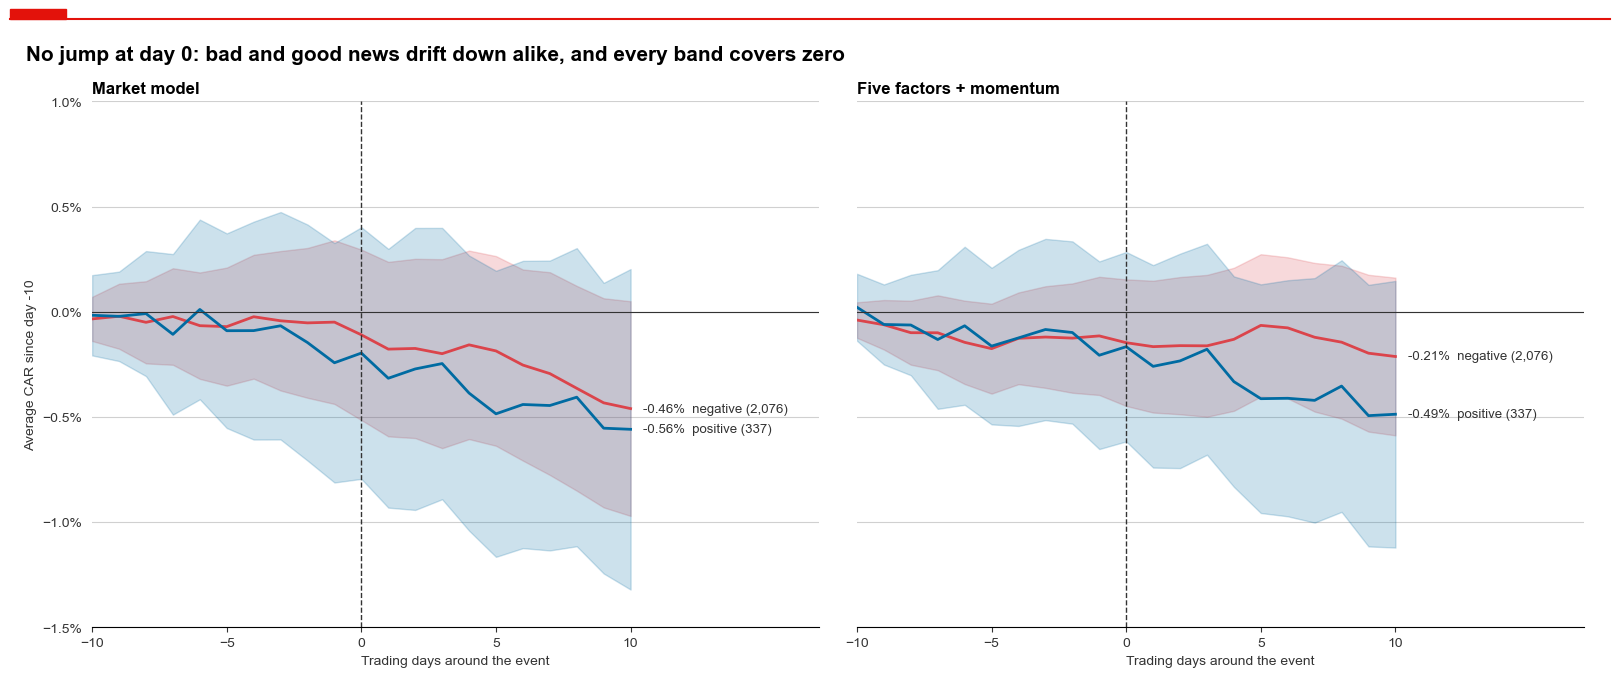

In [683]:
paths = {}
for model, column in [("market", AR_MARKET), ("factors", AR_FACTORS)]:
    for sign in ["negative", "positive"]:
        paths[model, sign] = car_path(kept_days, column, car_table, sign)

counts = car_table["sign"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
for ax, model in zip(axes, ["market", "factors"]):
    for sign in ["negative", "positive"]:
        plot_car_path(ax, paths[model, sign], SENTIMENT_COLORS[sign],
                      f"{sign} ({counts[sign]:,})")
    format_car_axis(ax, BETA_NAMES[model])
axes[0].set_ylabel("Average CAR since day -10")
show("No jump at day 0: bad and good news drift down alike, and every band "
     "covers zero")

In [684]:
rows = []
for model in ["market", "factors"]:
    for sign in ["negative", "positive"]:
        path = paths[model, sign]
        rows.append({
            "model": BETA_NAMES[model],
            "sign": sign,
            "day -1": path.loc[-1, "mean"],
            "day +1": path.loc[1, "mean"],
            "day +10": path.loc[10, "mean"],
            "half width, day +10": path.loc[10, "half_width"],
        })

path_table = pd.DataFrame(rows).set_index(["model", "sign"])
path_table.style.format("{:+.2%}")

**Comments – 5.6**
* **There is no jump at day 0:** for negative events the average CAR goes from −0.05% on day −1 to −0.18% on day +1 in the market model. Sigwatch dates can lag the news, but we see no reaction just before day 0 either.

* **Negative events drift down slowly,** a fall without a jump: to −0.46% on day +10 in the market model and −0.21% with the factors. Krüger (2015) finds −1.31% over the same window.

* **Good news looks like bad news:** positive events end at −0.56% and −0.49%, so the two groups do not separate. Krüger (2015) also finds a weakly negative reaction to positive events (−0.47%).

* **Every band covers zero on day +10:** the half widths (half the length of a 95% band) are 0.51 and 0.37 percentage points, or points from here on, for negative events, 0.76 and 0.63 for positive ones. These are clustered bands around raw means.

* **So we see no clear reaction so far,** and the formal tests of Task #6 will decide.

### 5.7 Do the models and windows agree?
We compare the two models event by event, and the average CAR over all four windows. These are descriptions only. The tests follow in Task #6.

In [751]:
rows = []
for name in CAR_WINDOWS:
    for sign in ["negative", "positive"]:
        for model in ["market", "factors"]:
            table = car_table[car_table["sign"] == sign]
            mean, error = clustered_mean(table[f"{model} {name}"].values,
                                         table["day_0"])
            rows.append({"window": name, "sign": sign, "model": model,
                         "mean": mean, "half_width": Z_95 * error})

window_means = pd.DataFrame(rows)
excludes_zero = window_means["mean"].abs() > window_means["half_width"]

print("Intervals without zero:")
print(window_means[excludes_zero].round(4).to_string(index=False))

Intervals without zero:
  window     sign  model    mean  half_width
[0, +10] negative market -0.0041      0.0033


In [686]:
def plot_window_bars(ax, window_means, sign):
    '''Show the mean CAR of one sign per window, for both models.'''
    means = window_means[window_means["sign"] == sign]
    positions = np.arange(len(CAR_WINDOWS))
    for shift, model, color in [(-BAR_SHIFT, "market", GREY),
                                (BAR_SHIFT, "factors", ECONOMIST_COLORS[0])]:
        bars = means[means["model"] == model]
        ax.bar(positions + shift, bars["mean"], width=BAR_WIDTH, color=color,
               yerr=bars["half_width"], capsize=4, ecolor=DARK,
               label=BETA_NAMES[model])
    ax.axhline(0, color=ECONOMIST_RED, ls="--", lw=1)
    ax.set_xticks(positions, list(CAR_WINDOWS))
    ax.set_yticks(CAR_TICKS)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_title(f"{sign.capitalize()} events", fontsize=12)

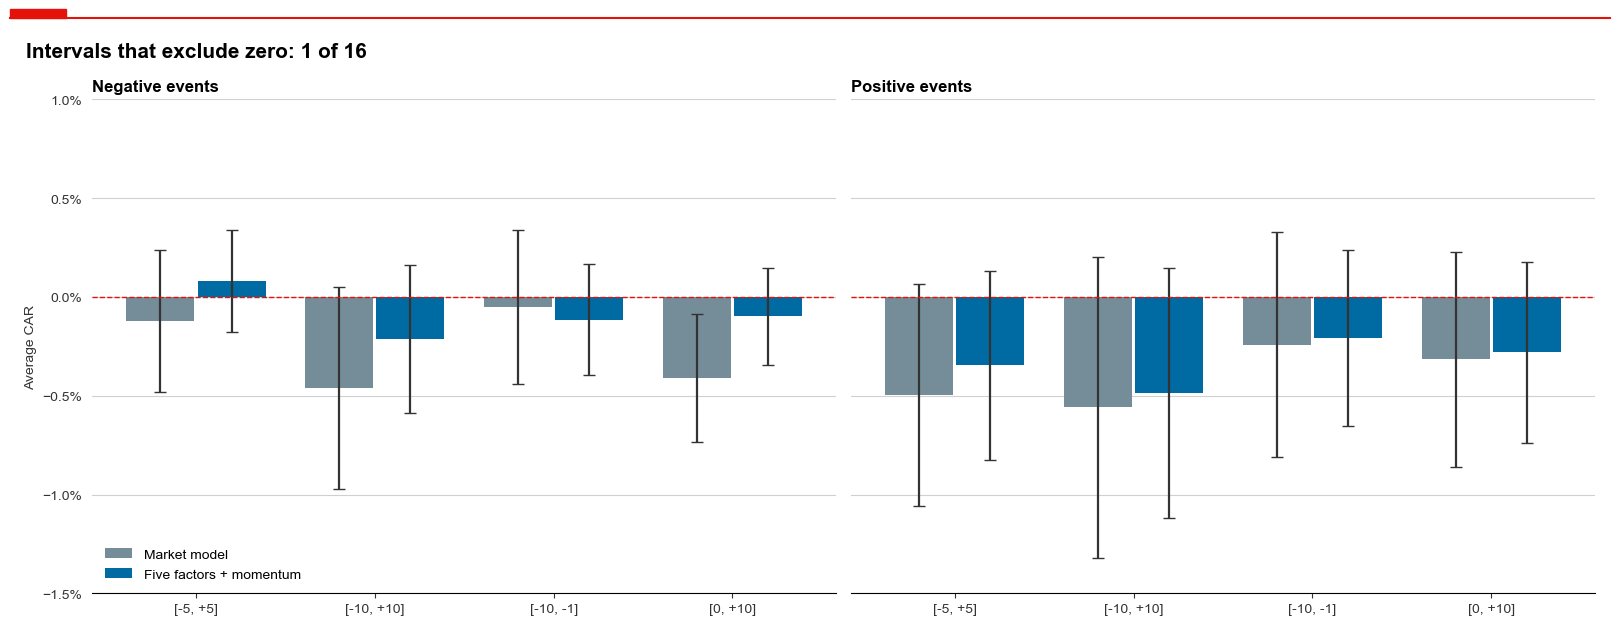

In [687]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
plot_window_bars(axes[0], window_means, "negative")
plot_window_bars(axes[1], window_means, "positive")
axes[0].set_ylabel("Average CAR")
axes[0].legend(loc="lower left")
show(f"Intervals that exclude zero: {excludes_zero.sum()} of "
     f"{len(window_means)}")

In [688]:
LIMIT = 0.5  # CARs beyond 50% are shown at the edge of the chart


def plot_model_cars(ax, car_table):
    '''Compare the baseline CAR of the two models, event by event.'''
    ax.scatter(car_table[BASE_CAR].clip(-LIMIT, LIMIT),
               car_table["factors [-10, +10]"].clip(-LIMIT, LIMIT), s=8,
               alpha=0.4, color=ECONOMIST_COLORS[0])
    plot_45_degree(ax, [-LIMIT, LIMIT])
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("CAR, market model")
    ax.set_ylabel("CAR, five factors + momentum")
    ax.legend(loc="upper left")

In [689]:
car_gap = car_table["factors [-10, +10]"] - car_table[BASE_CAR]
car_correlation = car_table[BASE_CAR].corr(car_table["factors [-10, +10]"])
print(f"Correlation of the CARs: {car_correlation:.2f}")
print(f"Median absolute gap: {car_gap.abs().median():.2%}")
print(f"Volatility of the CARs, market model: {car_table[BASE_CAR].std():.2%}")
print(f"Volatility of the CARs, factors: "
      f"{car_table['factors [-10, +10]'].std():.2%}")

Correlation of the CARs: 0.85
Median absolute gap: 2.03%
Volatility of the CARs, market model: 7.44%
Volatility of the CARs, factors: 6.62%


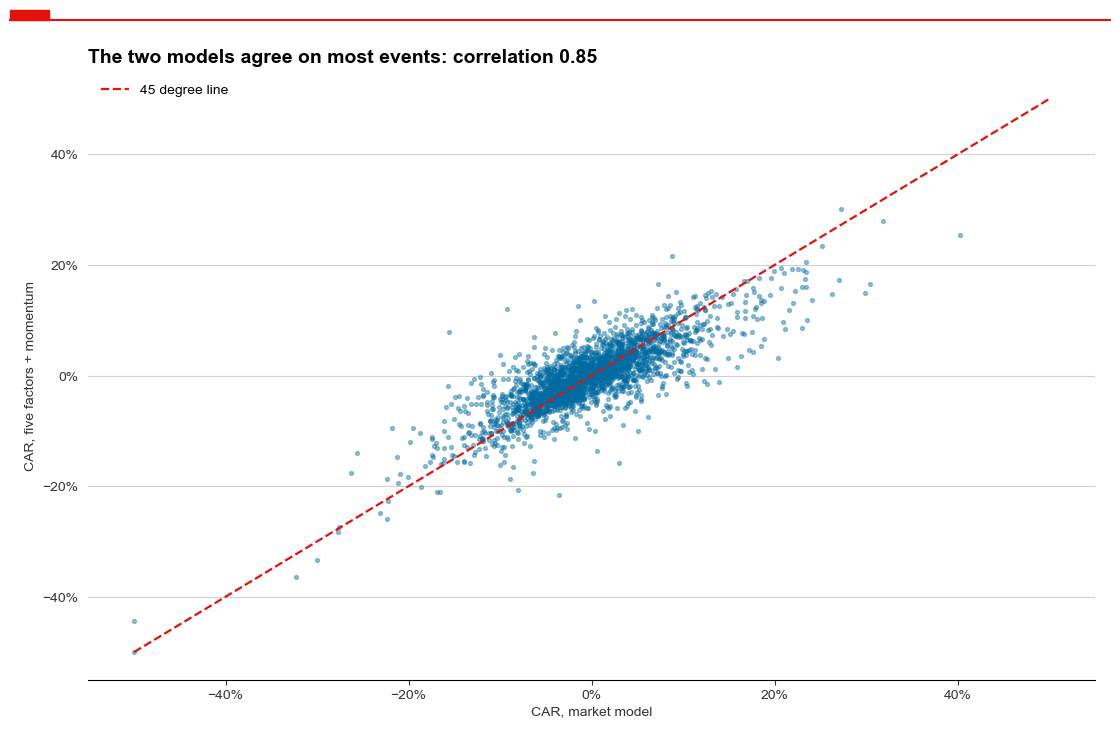

In [690]:
fig, ax = plt.subplots(figsize=(11, 7))
plot_model_cars(ax, car_table)
ax.set_title(f"The two models agree on most events: correlation "
             f"{car_correlation:.2f}")
show()

**Comments – 5.7**
* **The models agree on single events:** the correlation of the CARs is 0.85, with a median gap of 2.03 points.

* **The factors remove noise:** the volatility of the CARs falls from 7.44% to 6.62%.

* **They also shrink the average:** the negative mean falls from −0.46% to −0.21%, so about half of the market model's drift is exposure to other factors. This answers the question of Task #4 on our baseline window: the simple model changes the size, not the sign. Over $[-5, +5]$ the factor mean is slightly positive, but close to zero.

* **Windows add little:** one interval of 16 excludes zero, about what chance gives, and it is the market model only: negative events over $[0, +10]$. With the factors the same window covers zero.

**Result of Task #5.** `car_table` holds 2,547 events, with CARs for both models over the four windows, the volatility for the BMP test and the flags `conflict_5_days`, `brexit_in_window`, `largest_move` and `overlap`. `all_cars` holds the same CARs for the 120 and 500 day estimation windows. On average we see a small drift and no jump, for bad news and good news alike. Task #6 tests this properly.

## Task #6 – Do NGO campaigns matter?
Do bank shares fall when NGOs attack? Our main test takes the negative events over $[-10, +10]$ with the market model, as Krüger (2015) does. We then compare negative with positive events, split the negative events by period, issue and tone, and rerun the main test in several ways. Neutral events stay out of the tests. We chose the main test and the splits before we ran them, but after the descriptive results of Task #5. The tests on positive events, the clustered BMP test and the Brexit and overlap rows came later still. We report every test we ran.

### 6.1 Winsorised CARs
A few events have extreme CARs, such as Bankia at −138%. We set values beyond the 1st and 99th percentile to those percentiles. The limits come from the negative and positive events together, so both groups are treated alike. The raw CARs come back as a robustness row.

In [691]:
WINSOR_LEVELS = [0.01, 0.99]  # the 1st and 99th percentile


def winsorise(table, column):
    '''Limit a CAR to the percentiles of the signed events.'''
    signed_cars = table.loc[table["sign"] != "neutral", column]
    low, high = signed_cars.quantile(WINSOR_LEVELS)
    return table[column].clip(low, high)

In [692]:
# The other estimation windows are needed only for the robustness checks
for window in [120, 500]:
    window_cars = all_cars["market", window]["[-10, +10]"]
    car_table[f"market {window} days"] = window_cars

CAR_COLUMNS = [f"{model} {name}" for model in ["market", "factors"]
               for name in CAR_WINDOWS]
CAR_COLUMNS += ["market 120 days", "market 500 days"]

for column in CAR_COLUMNS:
    car_table[f"w {column}"] = winsorise(car_table, column)

In [693]:
MAIN_CAR = f"w {BASE_CAR}"
FACTOR_CAR = "w factors [-10, +10]"

is_signed = car_table["sign"] != "neutral"
main_cars = car_table.loc[is_signed, MAIN_CAR]
raw_cars = car_table.loc[is_signed, BASE_CAR]
changed = (main_cars != raw_cars).sum()
print(f"Limits: {main_cars.min():+.1%} and {main_cars.max():+.1%}")
print(f"Signed events changed: {changed} of {len(main_cars):,}")

Limits: -17.4% and +20.8%
Signed events changed: 50 of 2,413


**Comments – 6.1**
* **The limits are −17.4% and +20.8%:** they touch only 50 of 2,413 signed events, so Bankia's −138% counts as −17.4%.

* **We cap, we do not delete:** every event keeps its place and its sign, so the sign test does not change, and the raw CARs return in 6.5.

### 6.2 The main test
We report four numbers, because each guards against something else.

* **The mean, with standard errors clustered by day 0.** Events on the same day move together.

* **The median.** One event cannot move it.

* **The BMP test** (Boehmer, Musumeci and Poulsen, 1991). Each CAR is divided by the bank's residual volatility in its estimation window, scaled to the 21 days, so volatile banks do not dominate: $SCAR_i = CAR_i / (\hat{\sigma}_i \sqrt{21})$. The statistic compares the mean $SCAR$ with its standard deviation across events.

* **The generalised sign test** (Cowan, 1992). It asks whether the share of positive CARs differs from normal, and normal is the share of positive residuals in the estimation windows, not one half: $Z = (w - n\hat{p}) / \sqrt{n\hat{p}(1-\hat{p})}$.

In [694]:
def p_value(statistic):
    '''Compute the two sided p value of a normal statistic.'''
    return 2 * stats.norm.sf(abs(statistic))


def standardised_cars(table, column, sigma_column="sigma_market"):
    '''Divide each CAR by the bank's volatility over the 21 days.'''
    # sigma is a daily volatility, so a 21 day sum scales with the root of 21
    return table[column] / (table[sigma_column] * np.sqrt(window_length))


def bmp_statistic(table, column, sigma_column="sigma_market"):
    '''Compute the BMP statistic from the standardised CARs.'''
    standardised = standardised_cars(table, column, sigma_column)
    error = standardised.std() / np.sqrt(len(standardised))
    return standardised.mean() / error

In [695]:
def positive_residual_share(event):
    '''Compute the share of positive residuals in an event's window.'''
    days = window_days(event, BASE_WINDOW)
    y, factors = model_data(event["bank"], "market")
    estimate = market_estimates.loc[event.name]  # event.name is its event_id
    market = factors.loc[days, "market"]
    predicted = estimate["alpha"] + estimate["market"] * market
    residuals = (y.loc[days] - predicted).dropna()
    return (residuals > 0).mean()


def sign_statistic(cars, expected_share):
    '''Compute the generalised sign test of Cowan (1992).'''
    n_events = len(cars)
    positive = (cars > 0).sum()
    expected = n_events * expected_share
    spread = np.sqrt(n_events * expected_share * (1 - expected_share))
    return (positive - expected) / spread

In [696]:
car_table["positive_share"] = car_table.apply(positive_residual_share, axis=1)
signed_events = car_table[is_signed]
negative_events = signed_events[signed_events["sign"] == "negative"]
positive_events = signed_events[signed_events["sign"] == "positive"]

In [697]:
def main_tests(table, column=MAIN_CAR):
    '''Run the four tests of the main test on one group of events.'''
    mean, error = clustered_mean(table[column].values, table["day_0"])
    standardised = standardised_cars(table, column).values
    bmp_mean, bmp_error = clustered_mean(standardised, table["day_0"])
    bmp = bmp_statistic(table, column)
    # Each event has its own normal share, the group has their mean
    normal_share = table["positive_share"].mean()
    sign_z = sign_statistic(table[column], normal_share)

    return pd.Series({
        "events": len(table),
        "mean": mean,
        "half width": Z_95 * error,
        "p value, clustered": p_value(mean / error),
        "median": table[column].median(),
        "BMP statistic": bmp,
        "p value, BMP": p_value(bmp),
        "p value, BMP clustered": p_value(bmp_mean / bmp_error),
        "positive CARs": (table[column] > 0).mean(),
        "normal share": normal_share,
        "sign statistic": sign_z,
        "p value, sign": p_value(sign_z),
    })

The drift of Task #5 touches both groups, so we run the same tests on the positive events. A test that only picks up the drift rejects for them too, in the same direction.

In [698]:
main_results = pd.DataFrame({"negative": main_tests(negative_events),
                             "positive": main_tests(positive_events)})
mean_car = main_results.loc["mean", "negative"]
mean_half_width = main_results.loc["half width", "negative"]

percent_rows = ["mean", "half width", "median", "positive CARs", "normal share"]
shown_results = main_results.astype(object)
for row in main_results.index:
    number = "{:+.2%}" if row in percent_rows else "{:.3f}"
    if row == "events":
        number = "{:,.0f}"
    shown_results.loc[row] = main_results.loc[row].map(number.format)
shown_results

,negative,positive
events,"2,076",337
mean,-0.38%,-0.55%
half width,+0.47%,+0.76%
"p value, clustered",0.115,0.153
median,-0.88%,-0.68%
BMP statistic,-3.637,-2.137
"p value, BMP",0.000,0.033
"p value, BMP clustered",0.033,0.069
positive CARs,+44.27%,+45.70%
normal share,+48.63%,+48.57%


The figure shows the path of Task #5 and the main estimate next to it.

In [699]:
def plot_main_estimate(ax, negative_events, mean_car, mean_half_width):
    '''Show the mean, the raw mean and the median of the negative CARs.'''
    ax.errorbar([0], [mean_car], yerr=mean_half_width, fmt="o", ms=9, capsize=5,
                color=ECONOMIST_COLORS[8], ecolor=ECONOMIST_COLORS[8])
    ax.scatter([1], [negative_events[BASE_CAR].mean()], s=70, color=GREY)
    ax.scatter([2], [negative_events[MAIN_CAR].median()], s=70,
               color=ECONOMIST_COLORS[3], edgecolors="black")

    values = [mean_car, negative_events[BASE_CAR].mean(),
              negative_events[MAIN_CAR].median()]
    for position, value in enumerate(values):
        annotate(ax, f"{value:+.2%}", (position, value), offset=(12, 0))

    ax.axhline(0, color=ECONOMIST_RED, ls="--", lw=1)
    ax.set_xticks([0, 1, 2], ["Winsorised\nmean", "Raw\nmean", "Median"])
    ax.set_xlim(-0.5, 2.7)
    ax.set_yticks(CAR_TICKS)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_title("Main estimate over [-10, +10]", fontsize=12)

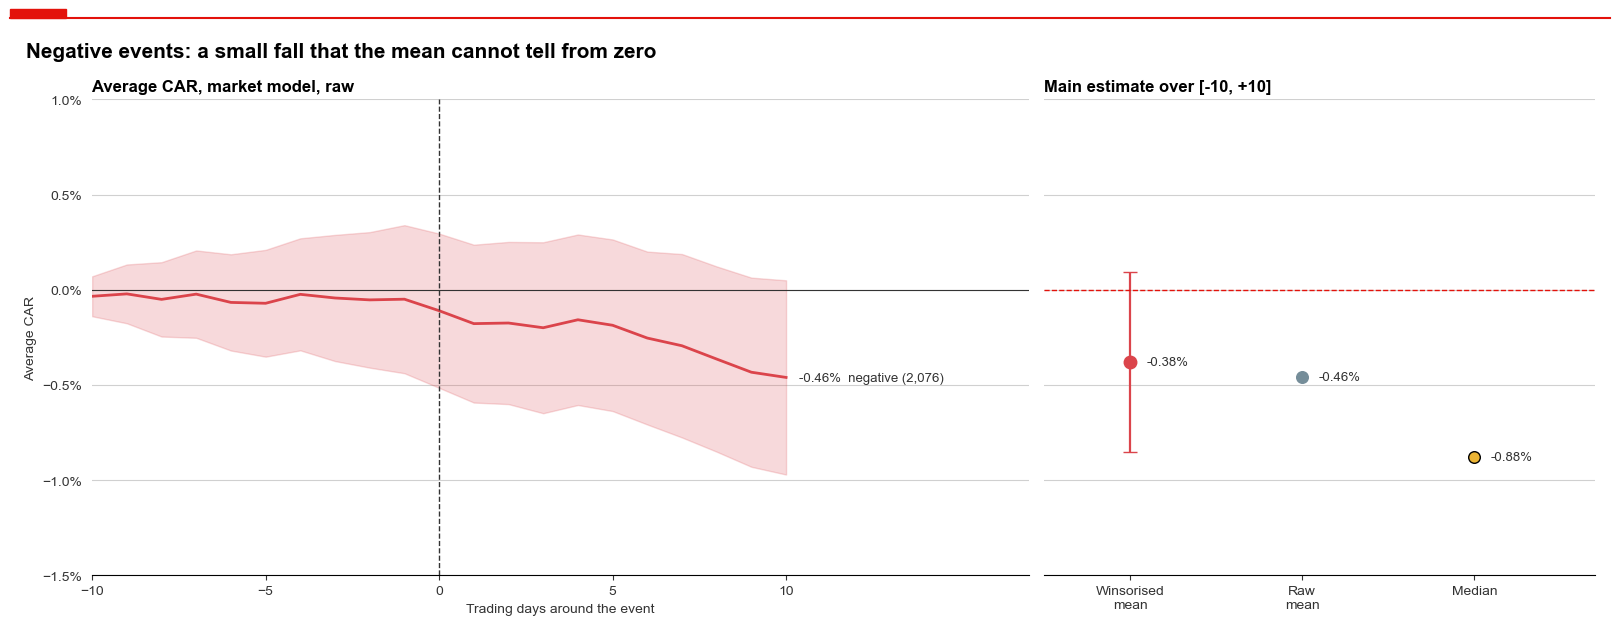

In [700]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True,
                         gridspec_kw={"width_ratios": [1.7, 1]})
negative_path = paths["market", "negative"]
plot_car_path(axes[0], negative_path, SENTIMENT_COLORS["negative"],
              f"negative ({counts['negative']:,})")
format_car_axis(axes[0], "Average CAR, market model, raw")
axes[0].set_ylabel("Average CAR")
plot_main_estimate(axes[1], negative_events, mean_car, mean_half_width)
show("Negative events: a small fall that the mean cannot tell from zero")

The BMP test above uses the market model. Does it still reject with the five factors and momentum? Each CAR is now scaled by the residual volatility of that model.

In [701]:
def factor_bmp(table):
    '''Run the BMP test on the factor model, plain and clustered.'''
    standardised = standardised_cars(table, FACTOR_CAR, "sigma_factors").values
    mean, error = clustered_mean(standardised, table["day_0"])
    statistic = bmp_statistic(table, FACTOR_CAR, "sigma_factors")
    return pd.Series({
        "BMP statistic": statistic,
        "p value, BMP": p_value(statistic),
        "p value, BMP clustered": p_value(mean / error),
    })


bmp_factors = pd.DataFrame({"negative": factor_bmp(negative_events),
                            "positive": factor_bmp(positive_events)})
bmp_factors.style.format("{:.3f}")

,negative,positive
BMP statistic,-1.493,-1.834
"p value, BMP",0.135,0.067
"p value, BMP clustered",0.302,0.093


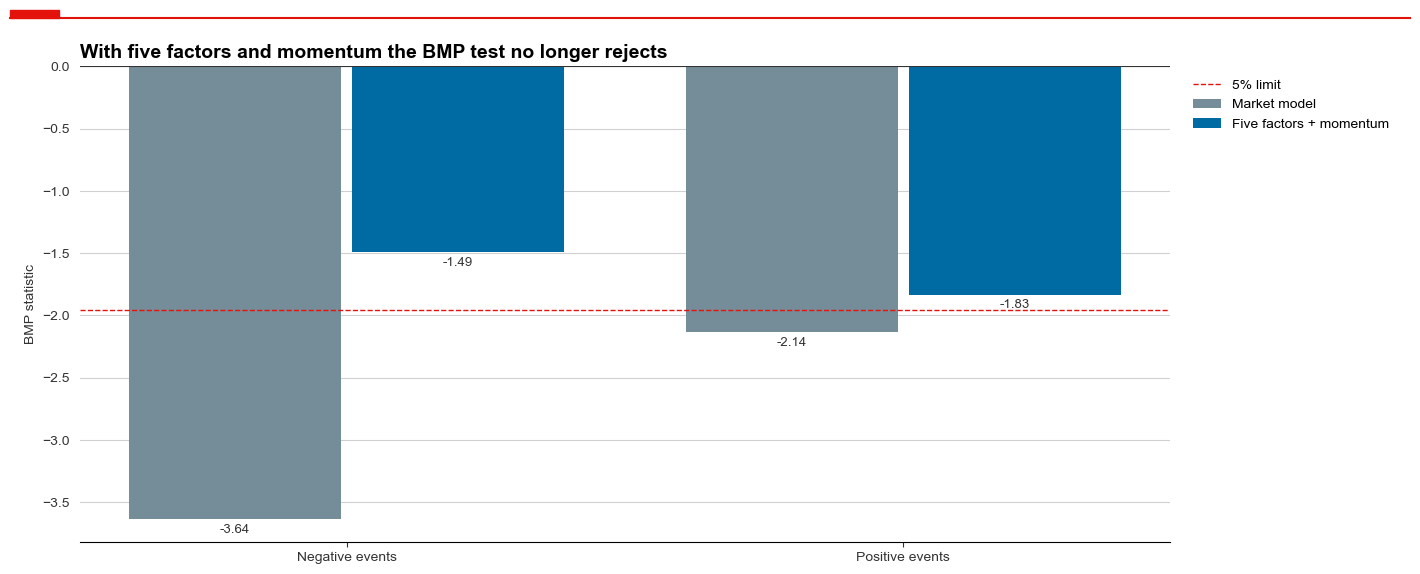

In [702]:
signs = ["negative", "positive"]
positions = np.arange(len(signs))

fig, ax = plt.subplots(figsize=(14, 5.5))
market_bars = ax.bar(positions - BAR_SHIFT,
                     main_results.loc["BMP statistic", signs],
                     width=BAR_WIDTH, color=GREY, label=BETA_NAMES["market"])
factor_bars = ax.bar(positions + BAR_SHIFT,
                     bmp_factors.loc["BMP statistic", signs],
                     width=BAR_WIDTH, color=ECONOMIST_COLORS[0],
                     label=BETA_NAMES["factors"])
for bars in [market_bars, factor_bars]:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9.5, color=DARK)

ax.axhline(-Z_95, color=ECONOMIST_RED, ls="--", lw=1, label="5% limit")
ax.axhline(0, color=DARK, lw=0.8)
ax.set_xticks(positions, ["Negative events", "Positive events"])
ax.set_ylabel("BMP statistic")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("With five factors and momentum the BMP test no longer rejects")
show()

**Comments – 6.2**
* **Negative events lose a little:** the mean is −0.38% winsorised and −0.46% raw, and the median −0.88%. Krüger (2015) finds −1.31% over the same window.

* **The mean cannot tell this from zero:** clustered by day 0, its p value is 0.115.
* **The BMP and sign tests reject:** the BMP statistic is −3.64, and 44.3% of CARs are positive against a normal 48.6%, a sign statistic of −3.98. Both treat events as independent, though. With clustering the p value of the BMP test rises to 0.033.

* **Only the plain BMP test rejects for both groups.** Positive events have a BMP statistic of −2.14 (p = 0.033), but with clustering their p value is 0.069, and their sign test does not reject (−1.05, p = 0.292), with 45.7% of CARs positive against a normal 48.6%. So the clustered BMP test and the sign test reject for negative events only, although there are far fewer positive events to test.

* **On Krüger's tests the pattern is his, at about a third of the size:** he reports −1.31% for negative events (t −6.57, sign −5.20) and −0.47% for positive ones (t −1.82, sign −1.66). Our raw means are −0.46% (BMP −3.64, sign −3.98) and −0.56% (BMP −2.14, sign −1.05).

* **But the BMP rejection comes from the market model** (chart): with the five factors and momentum the statistic is −1.49 (p = 0.135) for negative events and −1.83 (p = 0.067) for positive ones, with clustered p values of 0.302 and 0.093. So part of what the market model calls a reaction is exposure to other factors.

### 6.3 Negative against positive events
Both groups fall a little, so a negative mean alone says little. The difference between them removes what they share, which makes it the cleaner test, if good news has no effect of its own. That is not certain: Krüger (2015) finds a weakly negative reaction to positive events, and 123 of our reports carry both signs (3.1). We run the test as a regression of the CAR on a dummy, with standard errors clustered by day 0, and every split below uses the same function.

In [703]:
def compare_groups(table, is_first, first, second, column=MAIN_CAR):
    '''Compare two groups: means, intervals, counts and the difference.'''
    groups = pd.factorize(table["day_0"])[0]
    # The coefficient on the dummy is the gap between the two group means
    fit = ols(table[column], is_first.astype(float), clusters=groups)

    first_group = table[is_first]
    second_group = table[~is_first]
    first_mean, first_error = clustered_mean(first_group[column].values,
                                             first_group["day_0"])
    second_mean, second_error = clustered_mean(second_group[column].values,
                                               second_group["day_0"])
    return {
        "first": first, "second": second,
        "first mean": first_mean, "second mean": second_mean,
        "first half width": Z_95 * first_error,
        "second half width": Z_95 * second_error,
        "first events": len(first_group), "second events": len(second_group),
        "difference": fit.params[1], "error": fit.bse[1],
        "p value": fit.pvalues[1],
    }

In [704]:
def plot_groups(ax, result):
    '''Draw two groups as bars with intervals and the number of events.'''
    means = [result["first mean"], result["second mean"]]
    widths = [result["first half width"], result["second half width"]]
    colors = [ECONOMIST_COLORS[0], ECONOMIST_COLORS[1]]

    ax.bar([0, 1], means, yerr=widths, capsize=4, width=0.7, color=colors,
           ecolor=DARK)
    labels = [f"{result['first']}\nn = {result['first events']:,}",
              f"{result['second']}\nn = {result['second events']:,}"]

    ax.axhline(0, color=ECONOMIST_RED, ls="--", lw=1)
    ax.set_xticks([0, 1], labels)
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.01))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

In [705]:
def difference_title(name, result):
    '''Write a panel title with the difference and its p value.'''
    return (f"{name}: {result['difference'] * 100:+.2f} points "
            f"(p = {result['p value']:.3f})")

In [706]:
is_negative = signed_events["sign"] == "negative"
sign_market = compare_groups(signed_events, is_negative, "Negative", "Positive")
sign_factors = compare_groups(signed_events, is_negative, "Negative",
                              "Positive", column=FACTOR_CAR)
drift = kept_days[AR_MARKET].mean() * window_length
gap_half_width = Z_95 * sign_market["error"]
print(f"Drift of all event days over 21 days: {drift:+.2%}")
print(f"Difference: {sign_market['difference']:+.2%} ± {gap_half_width:.2%}")

Drift of all event days over 21 days: -0.43%
Difference: +0.17% ± 0.82%


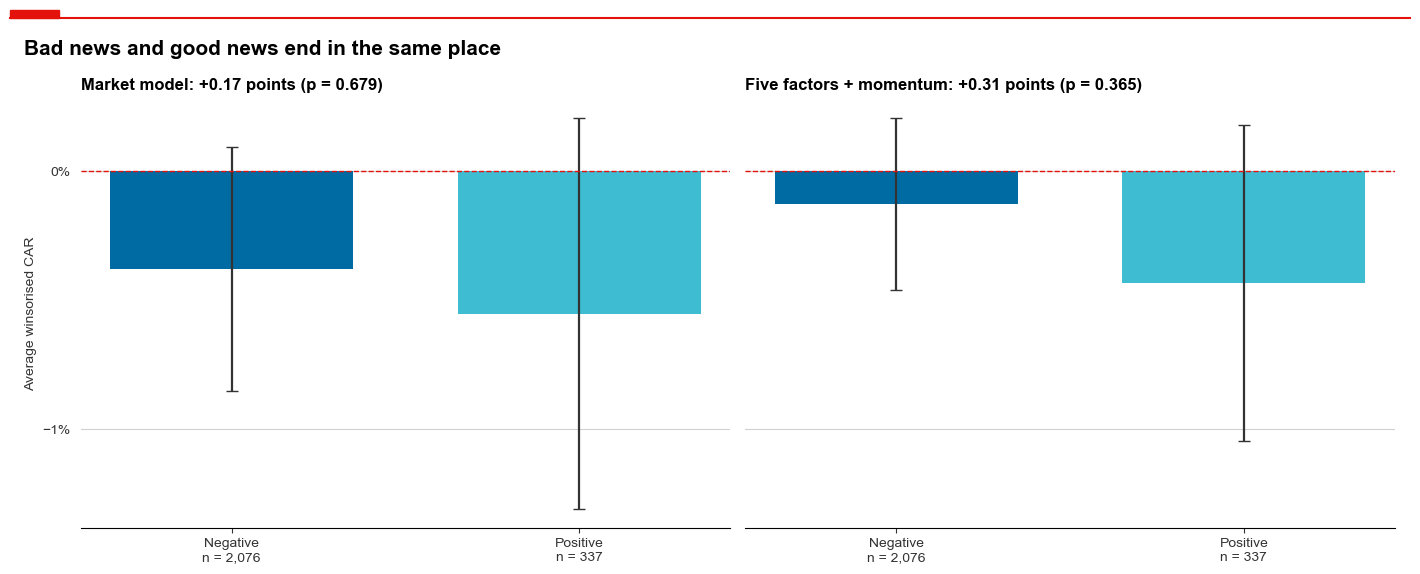

In [707]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
plot_groups(axes[0], sign_market)
axes[0].set_title(difference_title("Market model", sign_market), fontsize=12)
plot_groups(axes[1], sign_factors)
axes[1].set_title(difference_title("Five factors + momentum", sign_factors),
                  fontsize=12)
axes[0].set_ylabel("Average winsorised CAR")
show("Bad news and good news end in the same place")

The BMP and sign tests have a difference test too: the standardised CARs and the share of positive CARs, again as a regression on the dummy.

In [708]:
compared = signed_events.assign(
    standardised=standardised_cars(signed_events, MAIN_CAR),
    is_positive_car=(signed_events[MAIN_CAR] > 0).astype(float),
)
is_negative_event = compared["sign"] == "negative"

rows = []
for name, column in [("CAR", MAIN_CAR), ("Standardised CAR", "standardised"),
                     ("Share of positive CARs", "is_positive_car")]:
    result = compare_groups(compared, is_negative_event, "Negative", "Positive",
                            column=column)
    rows.append({"measure": name, "negative": result["first mean"],
                 "positive": result["second mean"],
                 "difference": result["difference"],
                 "p value": result["p value"]})

difference_tests = pd.DataFrame(rows).set_index("measure")
difference_tests.style.format("{:+.4f}", subset=["negative", "positive",
                                                 "difference"]).format(
    "{:.3f}", subset=["p value"])

,negative,positive,difference,p value
measure,,,,
CAR,-0.0038,-0.0055,+0.0017,0.679
Standardised CAR,-0.0787,-0.1155,+0.0368,0.591
Share of positive CARs,+0.4427,+0.4570,-0.0143,0.668


**Is the fall about events at all?** The −0.43% of all event days cannot answer this, because four of five event days belong to negative events. So we compare with days that have no link to the reports: we move every event date to a random day of the same year, and compute the same CAR for the same banks. Events on one date move together, so the random means keep the clustering of the real ones.

In [709]:
def day_cars(bank):
    '''Compute the market model CAR of a bank for every possible day 0.'''
    y, factors = model_data(bank, "market")
    parameters = rolling["market", BASE_WINDOW][bank].shift(GAP_DAYS)
    # center=True: each sum runs over the 21 days around its day 0
    return_sum = y.rolling(window_length, center=True).sum()
    market_sum = factors["market"].rolling(window_length, center=True).sum()
    return (return_sum - window_length * parameters["alpha"]
            - parameters["market"] * market_sum)


cars_by_day = pd.DataFrame({bank: day_cars(bank) for bank in event_banks})

# Check: on the real day 0 this gives our CARs
real_cars = [cars_by_day.at[row.day_0, row.bank]
             for row in car_table.itertuples()]
same_cars = np.allclose(real_cars, car_table[BASE_CAR])
print("Same as the CARs of Task #5:", same_cars)

Same as the CARs of Task #5: True


In [710]:
RANDOM_DRAWS = 1_000  # enough to read the tails of the random means


def random_means(table, low, high):
    '''Average the CARs after moving each date to a random day of its year.'''
    rng = np.random.default_rng(SEED)
    bank_columns = cars_by_day.columns.get_indexer(table["bank"])
    date_codes, dates = pd.factorize(table["day_0"])
    all_days = cars_by_day.index

    means = []
    for draw in range(RANDOM_DRAWS):
        new_days = np.zeros(len(dates), dtype=int)
        for year in np.unique(dates.year):
            is_year = dates.year == year
            days_of_year = np.flatnonzero(all_days.year == year)
            new_days[is_year] = rng.choice(days_of_year, is_year.sum())
        # A closed market or a bank not yet listed gives a missing CAR
        random_cars = cars_by_day.values[new_days[date_codes], bank_columns]
        means.append(np.nanmean(random_cars.clip(low, high)))
    return np.array(means)

In [711]:
low, high = main_cars.min(), main_cars.max()  # the limits of the main test
draws = {"negative": random_means(negative_events, low, high),
         "positive": random_means(positive_events, low, high)}

rows = []
for sign, means in draws.items():
    real_mean = main_results.loc["mean", sign]
    rows.append({
        "real mean": real_mean,
        "random mean": means.mean(),
        "random sd": means.std(),
        "draws at or below the real mean": (means <= real_mean).mean(),
    })

random_table = pd.DataFrame(rows, index=draws)
random_table.style.format({
    "real mean": "{:+.2%}",
    "random mean": "{:+.2%}",
    "random sd": "{:.2%}",
    "draws at or below the real mean": "{:.1%}",
})

,real mean,random mean,random sd,draws at or below the real mean
negative,-0.38%,-0.34%,0.23%,44.6%
positive,-0.55%,-0.34%,0.40%,30.4%


In [712]:
def plot_random_means(ax, means, real_mean, color, title):
    '''Show the random means with the real mean as a line.'''
    ax.hist(means, bins=30, color=LIGHT_GREY)
    ax.axvline(0, color=DARK, lw=0.8)
    ax.axvline(real_mean, color=color, lw=2)
    annotate(ax, f"real mean {real_mean:+.2%}", (real_mean, ax.get_ylim()[1]),
             offset=(-6, -10), bbox=WHITE_BOX)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax.set_xlabel("Mean winsorised CAR of random days")
    ax.set_title(title, fontsize=12)

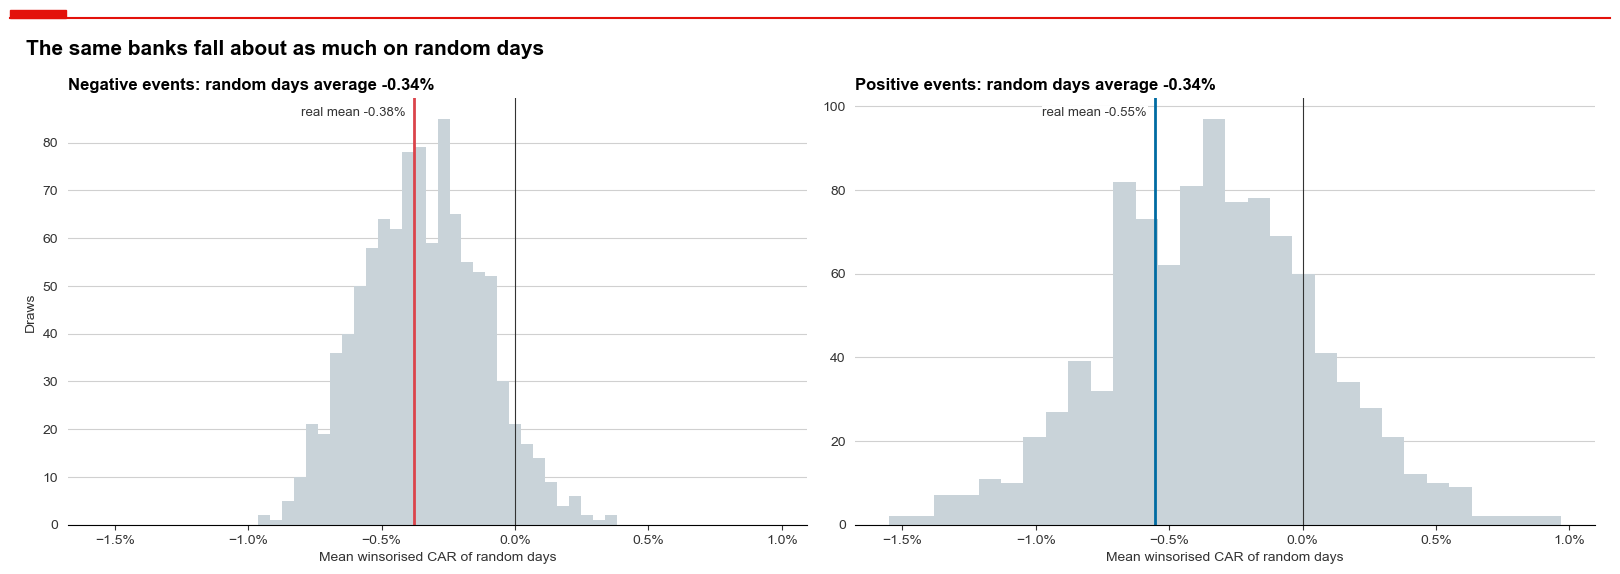

In [713]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True)
for ax, sign in zip(axes, draws):
    random_mean = random_table.loc[sign, "random mean"]
    plot_random_means(ax, draws[sign], random_table.loc[sign, "real mean"],
                      SENTIMENT_COLORS[sign],
                      f"{sign.capitalize()} events: random days average "
                      f"{random_mean:+.2%}")
axes[0].set_ylabel("Draws")
show("The same banks fall about as much on random days")

How much could the test of negative against positive events see? We set it against Krüger's gap, whose standard error follows from his means and t statistics.

In [714]:
# Krüger (2015), Tables 3 and 4: mean CAR and t statistic over [-10, +10]
KRUGER_NEGATIVE = -0.0131
KRUGER_POSITIVE = -0.0047
KRUGER_NEGATIVE_T = -6.57
KRUGER_POSITIVE_T = -1.82
POWER_TARGET = 0.8  # the usual standard for a well powered test

kruger_gap = KRUGER_NEGATIVE - KRUGER_POSITIVE
# Separate groups of events, so their variances add up
kruger_error = np.sqrt((KRUGER_NEGATIVE / KRUGER_NEGATIVE_T) ** 2
                       + (KRUGER_POSITIVE / KRUGER_POSITIVE_T) ** 2)
our_gap, our_error = sign_market["difference"], sign_market["error"]

gap_distance = our_gap - kruger_gap
distance_error = np.sqrt(our_error ** 2 + kruger_error ** 2)
gap_p_value = p_value(gap_distance / distance_error)

# Power of a two sided test at 5% against a gap of Krüger's size
shift_in_errors = abs(kruger_gap) / our_error
power = (stats.norm.sf(Z_95 - shift_in_errors)
         + stats.norm.cdf(-Z_95 - shift_in_errors))
smallest_gap = (Z_95 + stats.norm.ppf(POWER_TARGET)) * our_error

print(f"Krüger's gap: {kruger_gap:+.2%} ± {Z_95 * kruger_error:.2%}")
print(f"Our gap: {our_gap:+.2%} ± {Z_95 * our_error:.2%}")
print(f"Distance between the gaps: {gap_distance:+.2%}, p = {gap_p_value:.3f}")
print(f"Power against Krüger's gap: {power:.0%}")
print(f"Gap needed for {POWER_TARGET:.0%} power: {smallest_gap:.2%}")

Krüger's gap: -0.84% ± 0.64%
Our gap: +0.17% ± 0.82%
Distance between the gaps: +1.01%, p = 0.056
Power against Krüger's gap: 52%
Gap needed for 80% power: 1.17%


**Comments – 6.3**
* **Random days fall about as much:** moved to random days of the same year, the same banks end at −0.34% on average, against −0.38% for negative events and −0.55% for positive ones. 44.6% of the draws lie at or below the negative mean, and 30.4% at or below the positive one. So the fall is not special to event days. A random day can lie close to a real event, since banks are hit so often, so this is no event free benchmark.

* **The −0.43% of all event days proves little by itself:** four of five event days belong to negative events, so it cannot tell us about a drift apart from them. The random days can.

* **The difference between the groups shows nothing:** negative minus positive is +0.17 points (p = 0.679) in the market model and +0.31 (p = 0.365) with the factors. The BMP and sign versions agree, with p values of 0.591 and 0.668.

* **The sign of the gap tells us little:** the means put negative events above positive ones, but the median (−0.88% against −0.68%) and the share of positive CARs (44.3% against 45.7%) put them below.

* **This is no proof of a zero effect:** Krüger's gap of −0.84 points has a 95% interval of ± 0.64, from his t statistics, which overlaps our +0.17 ± 0.82, and the two gaps differ with p = 0.056. He also studies other firms, years and news. With our standard error the test finds a gap of his size only 52% of the time, and it needs 1.17 points for 80% power.

### 6.4 Splits of the negative events
Every split below uses the same function and the winsorised CARs of the negative events. First the five levels of the Sigwatch label, as bars only: we test sign and intensity, not each level.

In [715]:
# Labels of the five Sigwatch levels
LEVEL_NAMES = {-2: "-2", -1: "-1", 0: "0", 1: "+1", 2: "+2"}

rows = []
for level, group in car_table.groupby("sentiment"):
    mean, error = clustered_mean(group[MAIN_CAR].values, group["day_0"])
    rows.append({"mean": mean, "half_width": Z_95 * error,
                 "events": len(group)})

level_means = pd.DataFrame(rows, index=sorted(car_table["sentiment"].unique()))
level_colors = [SENTIMENT_COLORS["negative"], SENTIMENT_COLORS["negative"],
                SENTIMENT_COLORS["neutral"], SENTIMENT_COLORS["positive"],
                SENTIMENT_COLORS["positive"]]

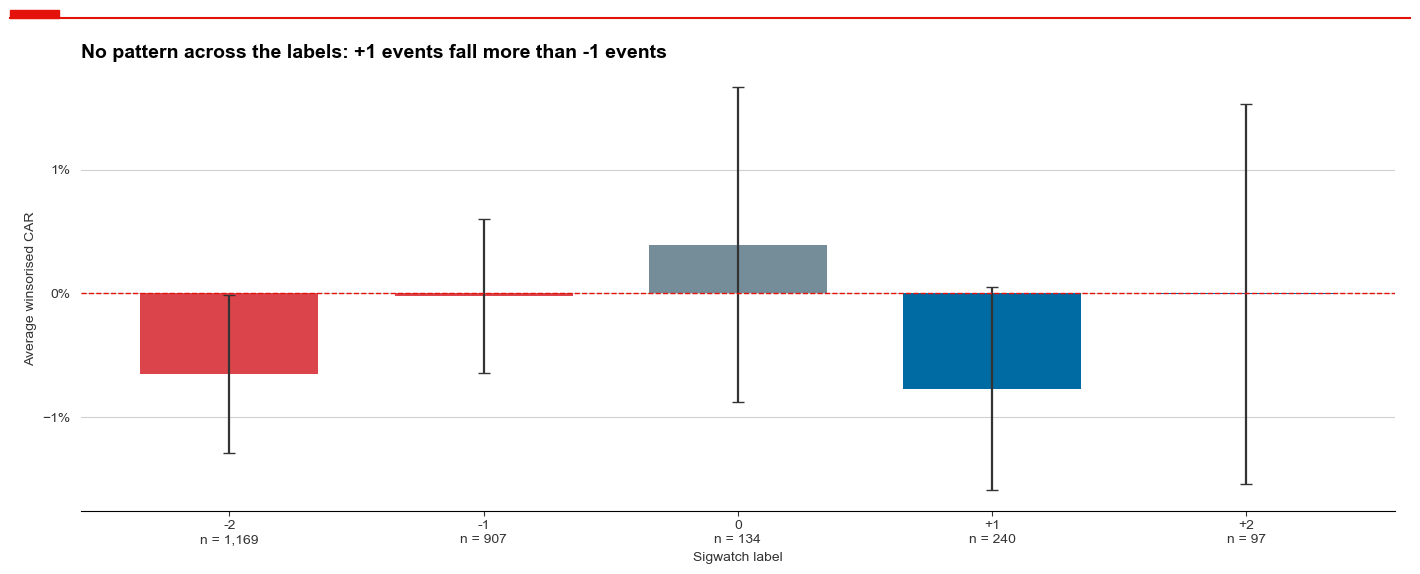

In [716]:
fig, ax = plt.subplots(figsize=(14, 5.5))
positions = np.arange(len(level_means))
ax.bar(positions, level_means["mean"], yerr=level_means["half_width"],
       capsize=4, width=0.7, color=level_colors, ecolor=DARK)
level_labels = [f"{LEVEL_NAMES[level]}\nn = {row['events']:,.0f}"
                for level, row in level_means.iterrows()]
ax.axhline(0, color=ECONOMIST_RED, ls="--", lw=1)
ax.set_xticks(positions, level_labels)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.01))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Sigwatch label")
ax.set_ylabel("Average winsorised CAR")
ax.set_title("No pattern across the labels: +1 events fall more than -1 "
             "events")
show()

In [717]:
print(level_means["mean"].map("{:+.2%}".format).to_string())

-2    -0.66%
-1    -0.02%
 0    +0.39%
 1    -0.77%
 2    -0.01%


Now the splits. A headline event has prominence 4, and a high reach NGO has an NGO power of 2 or more. A split by press coverage would need Task #1, which we did not build.

In [718]:
HIGH_REACH = 2  # NGO power of 2 or more counts as high reach

climate = "Climate and fossil fuels"

splits = {
    "COP21": compare_groups(negative_events, negative_events["day_0"] > COP21,
                            "After", "Up to"),
    "Trump election": compare_groups(negative_events,
                                     negative_events["day_0"] > TRUMP,
                                     "After", "Up to"),
    "Issue": compare_groups(negative_events,
                            negative_events["issue_group"] == climate,
                            "Climate", "Other"),
    "Prominence": compare_groups(negative_events,
                                 negative_events["prominence"] == 4,
                                 "Headline", "Other"),
    "Intensity": compare_groups(negative_events,
                                negative_events["sentiment"] == -2,
                                "-2", "-1"),
    "NGO power": compare_groups(negative_events,
                                negative_events["ngo_power"] >= HIGH_REACH,
                                "High reach", "Low reach"),
}

The model scores of Task #3 are the last split: the harshest third of the reports against the mildest third, next to the Sigwatch intensity above.

In [719]:
def score_split(negative_events, column):
    '''Compare the harshest and the mildest third of a model score.'''
    scored = negative_events.dropna(subset=[column])
    lower, upper = scored[column].quantile([1 / 3, 2 / 3])
    # The extremes only: the middle third would blur the comparison
    extremes = scored[(scored[column] <= lower) | (scored[column] >= upper)]
    return compare_groups(extremes, extremes[column] <= lower, "Harshest",
                          "Mildest")


if "finbert_score" in negative_events:
    splits["FinBERT"] = score_split(negative_events, "finbert_score")
    splits["Twitter-RoBERTa"] = score_split(negative_events, "roberta_score")
else:
    print("The split on the model scores is skipped: Task #3 did not run.")

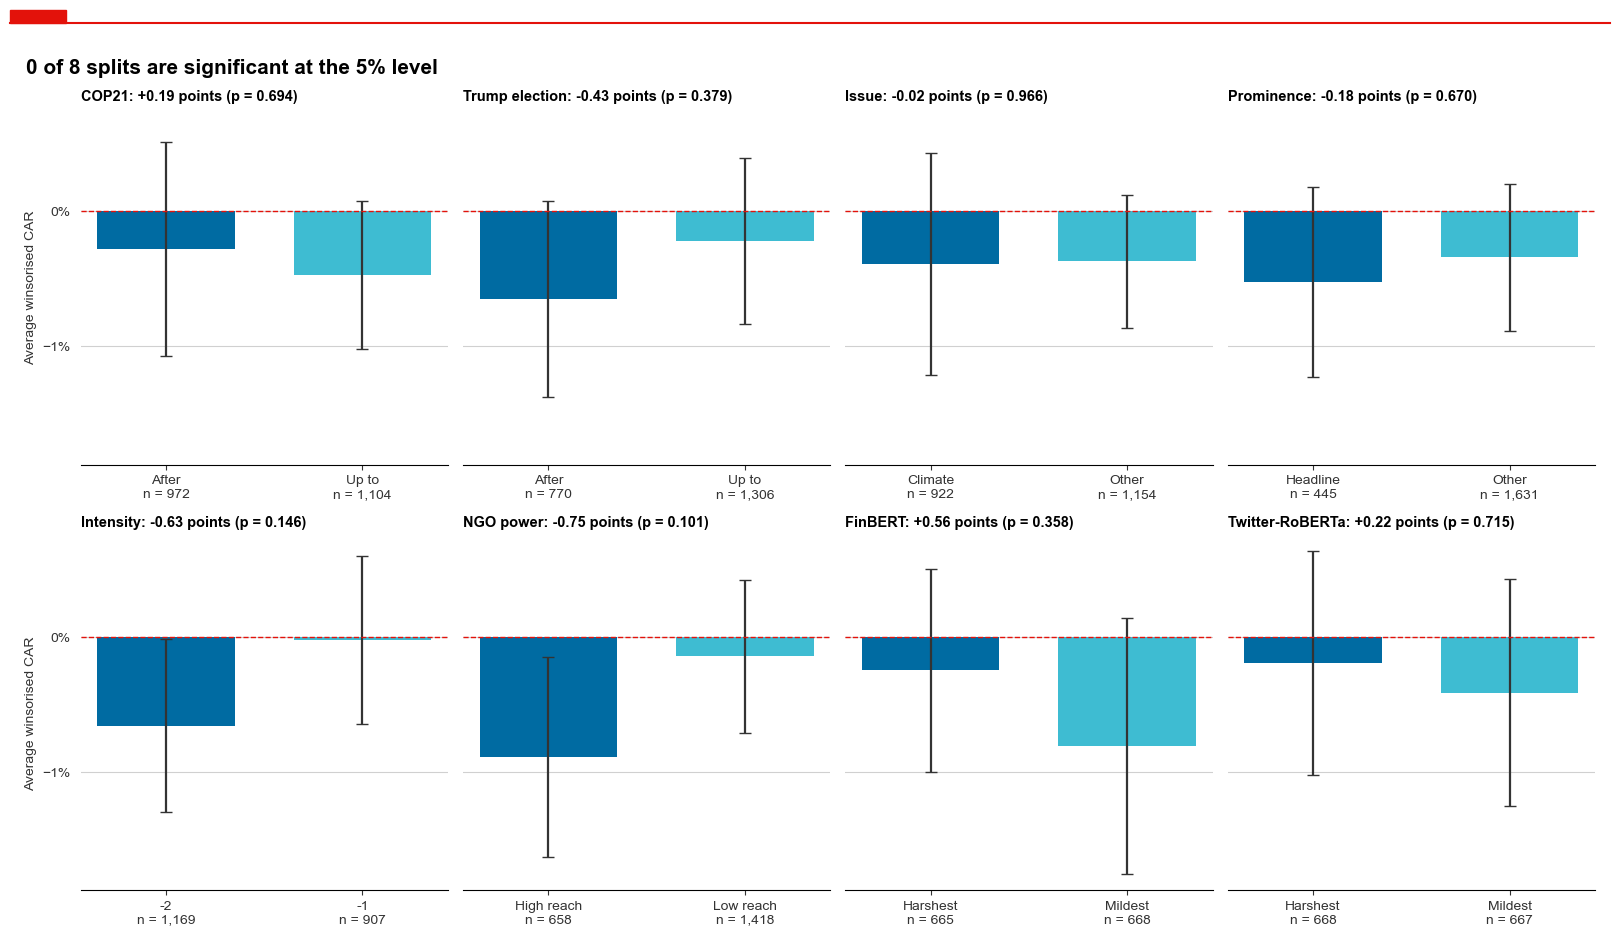

In [720]:
fig, axes = plt.subplots(2, 4, figsize=(16, 9), sharey=True)
for ax, (name, result) in zip(axes.flat, splits.items()):
    plot_groups(ax, result)
    ax.set_title(difference_title(name, result), fontsize=10.5)
for ax in axes.flat[len(splits):]:
    ax.set_visible(False)
axes[0, 0].set_ylabel("Average winsorised CAR")
axes[1, 0].set_ylabel("Average winsorised CAR")
significant = sum(result["p value"] < ALPHA for result in splits.values())
show(f"{significant} of {len(splits)} splits are significant at the 5% level")

In [721]:
split_table = pd.DataFrame(splits).T
split_columns = ["first", "second", "first mean", "second mean", "difference",
                 "p value", "first events", "second events"]

tests_run = len(splits) + 1  # the splits and negative against positive
p_values = [result["p value"] for result in splits.values()]
all_p_values = [*p_values, sign_market["p value"]]
splits_below = sum(value < ALPHA for value in all_p_values)
print(f"Group comparisons: {tests_run}, false alarms expected at 5%: "
      f"{tests_run * ALPHA:.1f}, found below 5%: {splits_below}")

split_table[split_columns].style.format({
    "first mean": "{:+.2%}", "second mean": "{:+.2%}", "difference": "{:+.2%}",
    "p value": "{:.3f}", "first events": "{:,}", "second events": "{:,}",
})

Group comparisons: 9, false alarms expected at 5%: 0.5, found below 5%: 0


,first,second,first mean,second mean,difference,p value,first events,second events
COP21,After,Up to,-0.28%,-0.47%,+0.19%,0.694,972,"1,104"
Trump election,After,Up to,-0.65%,-0.22%,-0.43%,0.379,770,"1,306"
Issue,Climate,Other,-0.39%,-0.37%,-0.02%,0.966,922,"1,154"
Prominence,Headline,Other,-0.52%,-0.34%,-0.18%,0.670,445,"1,631"
Intensity,-2,-1,-0.66%,-0.02%,-0.63%,0.146,"1,169",907
NGO power,High reach,Low reach,-0.89%,-0.14%,-0.75%,0.101,658,"1,418"
FinBERT,Harshest,Mildest,-0.25%,-0.81%,+0.56%,0.358,665,668
Twitter-RoBERTa,Harshest,Mildest,-0.19%,-0.41%,+0.22%,0.715,668,667


**Comments – 6.4**
* **No split separates the negative events:** none of the eight differences reaches 5%, and negative against positive does not either. The largest are NGO power (−0.75 points, p = 0.101) and intensity (−0.63, p = 0.146), both in the expected direction, but we cannot tell them from noise.

* **Period, issue and prominence show nothing either:** events after the Trump election lose 0.43 points more (p = 0.379), climate campaigns differ from others by −0.02 points (p = 0.966), and headline events by −0.18 points (p = 0.670).

* **The model scores do no better than the label** (Task #3): the harshest third of reports does not fall more than the mildest, with +0.56 points for FinBERT (p = 0.358) and +0.22 for Twitter-RoBERTa (p = 0.715). So Sigwatch stays our measure of sign.

* **The five levels show no order:** −2 is at −0.66%, but +1 at −0.77%, below −1 at −0.02%.

* **Many tests:** we report all 9 group comparisons. We chose them before running them, but after seeing Task #5. At 5% we would expect 0.5 false alarms, and we find none.

* **Small groups:** the number of events stands on every bar, and we merge +1 and +2 into positive. Wide intervals mean we cannot tell, not that the effect is zero.

* **COP21 is no clean experiment:** we write "after COP21", not "because of COP21". Events after it fall by 0.19 points less, with p = 0.694, and the placebo in 6.5 shows how far a date alone can move this.

* **The coding change of 2016:** Sigwatch's labels seem to change in 2016, right around the COP21 split, and 2010 is coded differently too (D1.5). A before and after comparison could partly pick up the coding, so we trust the sign of an event more than its exact level, and we rerun without 2010 to 2012 in 6.5.

### 6.5 Robustness
We rerun the main test in several ways. For each check we show the mean of the negative events, and on the right the difference between negative and positive events, which removes the common drift.

In [722]:
def checked_row(name, table, column):
    '''Compute the mean of the negative events and the sign difference.'''
    negative = table[table["sign"] == "negative"]
    mean, error = clustered_mean(negative[column].values, negative["day_0"])
    result = compare_groups(table, table["sign"] == "negative", "Negative",
                            "Positive", column=column)
    return {
        "check": name,
        "events": len(negative),
        "mean": mean,
        "half width": Z_95 * error,
        "difference": result["difference"],
        "difference half width": Z_95 * result["error"],
        "p value": result["p value"],
    }

In [723]:
# 2010 is coded differently, and the early years hold the euro crisis
from_2013 = signed_events["year"] >= 2013
us_banks_only = signed_events["region"] == "US"

checks = [
    ("Main test", signed_events, MAIN_CAR),
    ("Raw CARs, not winsorised", signed_events, BASE_CAR),
    ("Five factors + momentum", signed_events, FACTOR_CAR),
    ("Window [-5, +5]", signed_events, "w market [-5, +5]"),
    ("Window [-10, -1]", signed_events, "w market [-10, -1]"),
    ("Window [0, +10]", signed_events, "w market [0, +10]"),
    ("Estimation window of 120 days", signed_events, "w market 120 days"),
    # Late listed banks have no 500 day window, so they drop out here
    ("Estimation window of 500 days",
     signed_events.dropna(subset="w market 500 days"), "w market 500 days"),
    ("US banks only", signed_events[us_banks_only], MAIN_CAR),
    ("Without 2010 to 2012", signed_events[from_2013], MAIN_CAR),
    ("5 day rule of the do file",
     signed_events[~signed_events["conflict_5_days"]], MAIN_CAR),
    ("Without the Brexit vote in the window",
     signed_events[~signed_events["brexit_in_window"]], MAIN_CAR),
    ("Without overlapping windows", signed_events[~signed_events["overlap"]],
     MAIN_CAR),
]

In [724]:
robustness = pd.DataFrame([checked_row(*check) for check in checks])
robustness = robustness.set_index("check")

means_without_zero = robustness["mean"].abs() > robustness["half width"]
print(f"Means without zero: {means_without_zero.sum()} of {len(robustness)}")
print(f"Lowest p value of the differences: {robustness['p value'].min():.3f}")

Means without zero: 3 of 13
Lowest p value of the differences: 0.259


In [725]:
def plot_checks(ax, table, value, width, color, title):
    '''Draw one dot per check with its 95% interval and a zero line.'''
    positions = np.arange(len(table))[::-1]  # first check on top
    ax.errorbar(table[value], positions, xerr=table[width], fmt="o", ms=7,
                color=color, ecolor=color, capsize=3)
    ax.axvline(0, color=ECONOMIST_RED, ls="--", lw=1)
    ax.set_yticks(positions, table.index)
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.005))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    vertical_grid(ax)
    ax.set_title(title, fontsize=12)

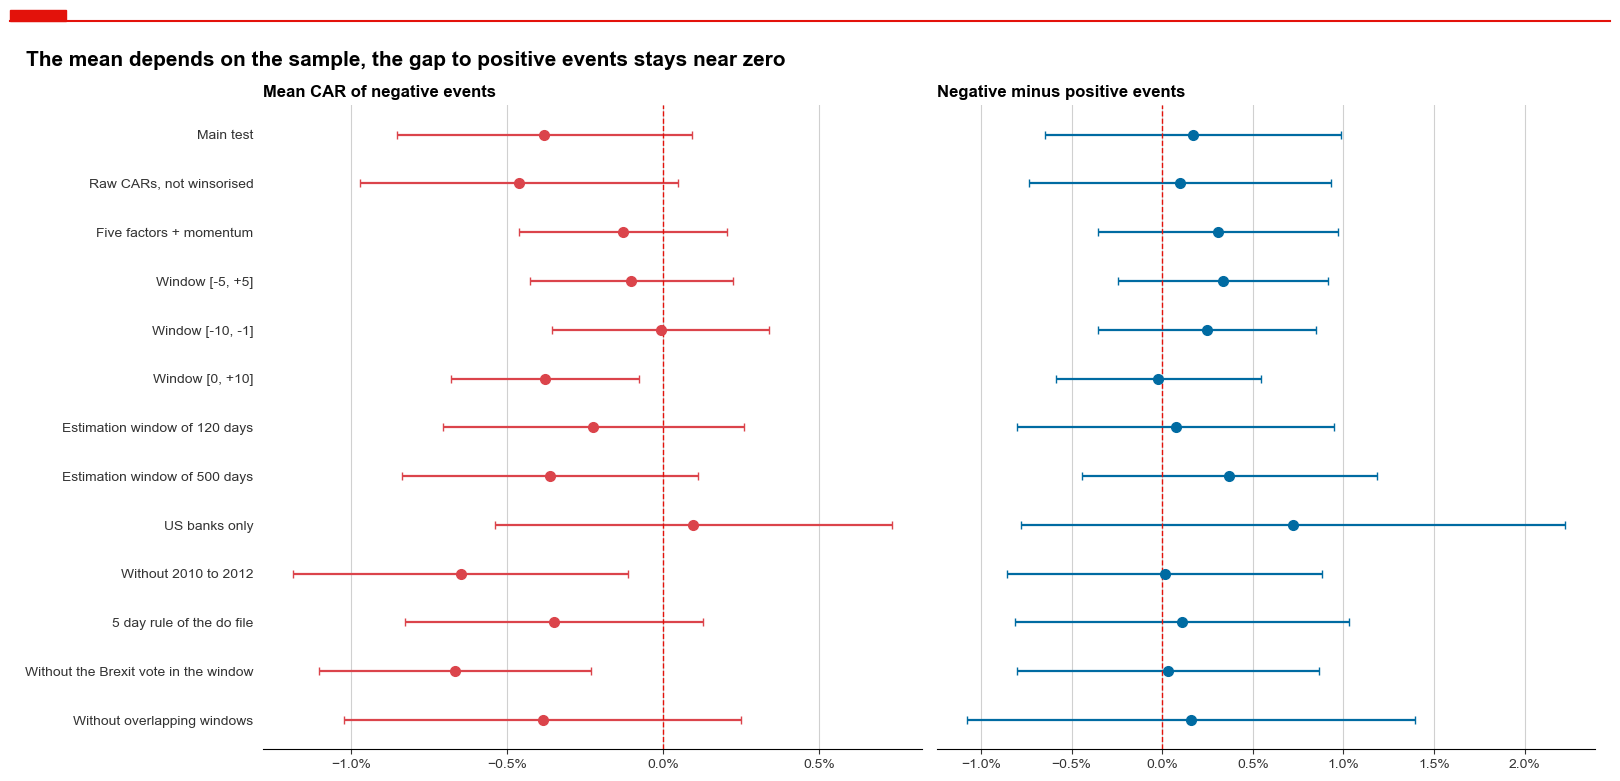

In [726]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharey=True)
plot_checks(axes[0], robustness, "mean", "half width",
            SENTIMENT_COLORS["negative"], "Mean CAR of negative events")
plot_checks(axes[1], robustness, "difference", "difference half width",
            ECONOMIST_COLORS[0], "Negative minus positive events")
show("The mean depends on the sample, the gap to positive events stays near "
     "zero")

In [727]:
robustness.style.format({"events": "{:,}", "mean": "{:+.2%}",
                         "half width": "{:.2%}", "difference": "{:+.2%}",
                         "difference half width": "{:.2%}",
                         "p value": "{:.3f}"})

,events,mean,half width,difference,difference half width,p value
check,,,,,,
Main test,"2,076",-0.38%,0.47%,+0.17%,0.82%,0.679
"Raw CARs, not winsorised","2,076",-0.46%,0.51%,+0.10%,0.84%,0.817
Five factors + momentum,"2,076",-0.13%,0.33%,+0.31%,0.66%,0.365
"Window [-5, +5]","2,076",-0.10%,0.33%,+0.33%,0.58%,0.259
"Window [-10, -1]","2,076",-0.01%,0.35%,+0.25%,0.60%,0.424
"Window [0, +10]","2,076",-0.38%,0.30%,-0.02%,0.57%,0.939
Estimation window of 120 days,"2,076",-0.22%,0.48%,+0.07%,0.87%,0.868
Estimation window of 500 days,"2,069",-0.36%,0.47%,+0.37%,0.81%,0.374
US banks only,663,+0.10%,0.64%,+0.72%,1.50%,0.345


The COP21 split needs its own check. We move the date one year back, to 12 December 2014, and keep only events up to the real COP21, so that the real date cannot shape the placebo. A difference at the false date would mean the split picks up something else.

COP21, 12 Dec 2015: +0.19%, p = 0.694
Placebo, 12 Dec 2014: -1.08%, p = 0.051


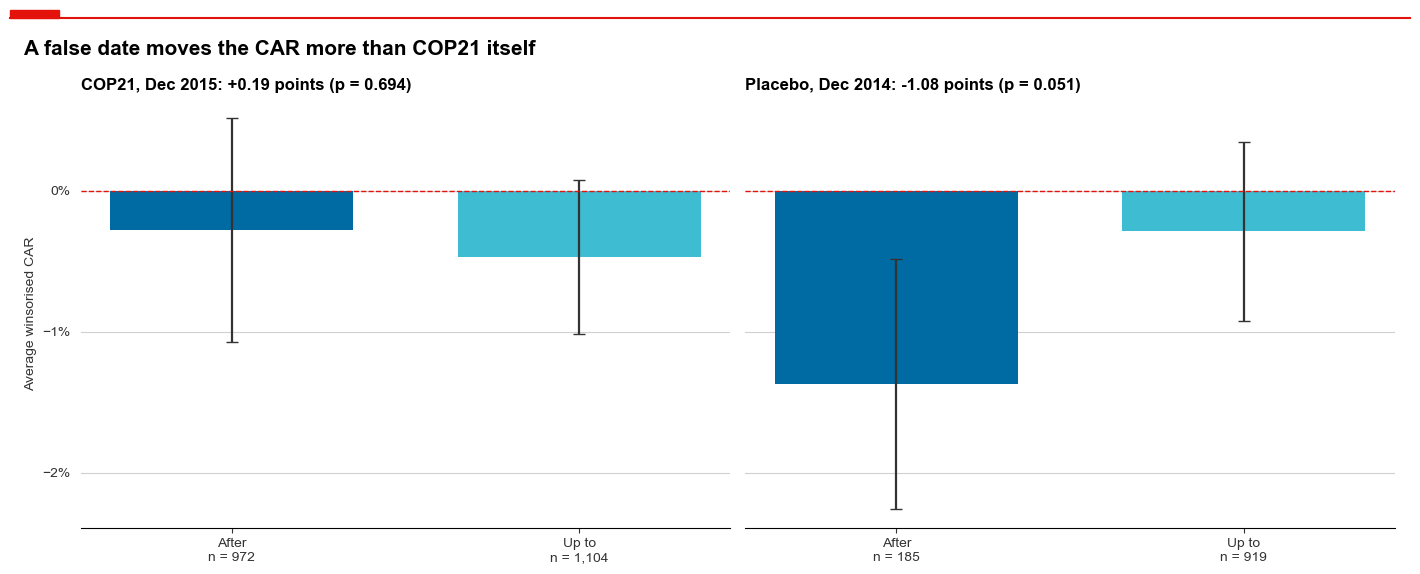

In [728]:
PLACEBO_DATE = COP21 - pd.DateOffset(years=1)

# Only events up to the real COP21, which cannot then shape the placebo
before_cop21 = negative_events[negative_events["day_0"] <= COP21]
placebo = compare_groups(before_cop21, before_cop21["day_0"] > PLACEBO_DATE,
                         "After", "Up to")

real_split = splits["COP21"]
print(f"COP21, 12 Dec 2015: {real_split['difference']:+.2%}, "
      f"p = {real_split['p value']:.3f}")
print(f"Placebo, 12 Dec 2014: {placebo['difference']:+.2%}, "
      f"p = {placebo['p value']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
plot_groups(axes[0], real_split)
axes[0].set_title(difference_title("COP21, Dec 2015", real_split), fontsize=12)
plot_groups(axes[1], placebo)
axes[1].set_title(difference_title("Placebo, Dec 2014", placebo), fontsize=12)
axes[0].set_ylabel("Average winsorised CAR")
show("A false date moves the CAR more than COP21 itself")

**Comments – 6.5**
* **The difference holds in every check:** in all 13 rows the gap between negative and positive events covers zero, and its lowest p value is 0.259.

* **The mean depends on the sample:** it covers zero in 10 of 13 checks. It does not over $[0, +10]$ (−0.38%), without 2010 to 2012 (−0.65%) and without the Brexit vote in the window (−0.67%). In all three the difference stays near zero, so the test against good news does not change.

* **The Brexit check tells the same story:** without the 297 Brexit events the mean is more negative, but the gap to positive events is +0.03 points.

* **US banks show nothing at all:** +0.10%, with no currency issue.

* **Overlapping windows change little:** on the 791 negative events without an overlap the mean stays at −0.39%, with a wider interval.

* **The placebo is a warning:** at a false date one year before COP21 the gap is −1.08 points (p = 0.051), larger than at COP21 itself (+0.19, p = 0.694). Date splits can move this much by chance, or with other news, on 185 events.

* **Other news stays a limit:** we have no news filter (no Factiva), so a campaign can coincide with earnings or a crisis. The median, the sign test and the rerun without 2010 to 2012 reduce this, but they do not remove it.

**Result of Task #6.** Negative events fall on the tests of Krüger (2015), at about a third of his size (raw mean −0.46% against −1.31%). But the mean does not reject with clustered errors (p = 0.115), the BMP test does not reject with the five factors (p = 0.135), and random days of the same banks end at −0.34%. We also cannot separate the fall from good news: the difference is +0.17 points (p = 0.679), it stays near zero in all 13 checks, and none of our 9 group comparisons reaches 5%. This is no proof of a zero effect, since our test has 52% power against Krüger's gap.

## Optional Task #7 – Political preferences
Do campaigns hit harder where people care more about climate change? The slide asks for green voting data. We use a survey instead, because it asks the same question in Europe and in the US: the share of people who call global climate change a very serious problem.

### 7.1 Climate concern per country
Six of our countries are in the survey: four euro area countries, the UK and the US. The values fall into two groups, with a gap between 45% and 53%, so we chose a limit of 50% after seeing them.

In [729]:
# Share saying global climate change is a very serious problem, in percent
# Source: Pew Research Center, Spring 2015 Global Attitudes survey, Q32
CLIMATE_CONCERN = {"US": 45, "UK": 41, "France": 56, "Germany": 55, "Italy": 55,
                   "Spain": 53}
CONCERN_LIMIT = 50  # high concern above this share

concern = pd.Series(CLIMATE_CONCERN)
is_high_concern = concern > CONCERN_LIMIT
concern_groups = is_high_concern.map({True: "High", False: "Low"})

For each country we count the events of Day 1 and its banks. Countries with more listed banks collect more events, so we also show the events per bank.

In [730]:
country_table = pd.DataFrame({
    "concern": concern,
    "group": concern_groups,
    "events": events["country"].value_counts().reindex(concern.index),
    "banks": events.groupby("country")["bank"].nunique().reindex(concern.index),
})
country_table["events per bank"] = (country_table["events"]
                                    / country_table["banks"])

covered = country_table["events"].sum() / len(events)
concern_correlation = country_table["concern"].corr(country_table["events"])
print(f"Events in the six countries: {covered:.0%} of all events")
print(f"Correlation of concern and events: {concern_correlation:.2f}")
country_table.sort_values("concern").style.format({"events per bank": "{:.0f}"})

Events in the six countries: 84% of all events
Correlation of concern and events: -0.82


,concern,group,events,banks,events per bank
UK,41,Low,585,7,84
US,45,Low,779,24,32
Spain,53,High,231,8,29
Germany,55,High,219,3,73
Italy,55,High,57,4,14
France,56,High,344,4,86


In [731]:
GROUP_POINT_COLORS = {"High": ECONOMIST_COLORS[0], "Low": ECONOMIST_COLORS[1]}


def plot_concern(ax, country_table):
    '''Show climate concern against the campaigns of each country.'''
    for group, color in GROUP_POINT_COLORS.items():
        rows = country_table[country_table["group"] == group]
        ax.scatter(rows["concern"], rows["events"], s=90, color=color,
                   edgecolors="black", label=f"{group} concern", zorder=3)

    for country, row in country_table.iterrows():
        annotate(ax, country, (row["concern"], row["events"]), offset=(0, 13))

    ax.axvline(CONCERN_LIMIT, color=DARK, ls="--", lw=1)
    ax.set_ylim(0, country_table["events"].max() * 1.15)  # room for the labels
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_xlabel("People calling climate change a very serious problem, 2015")
    ax.set_ylabel("Campaign events on banks, 2010 to 2018")
    ax.legend(loc="upper right")

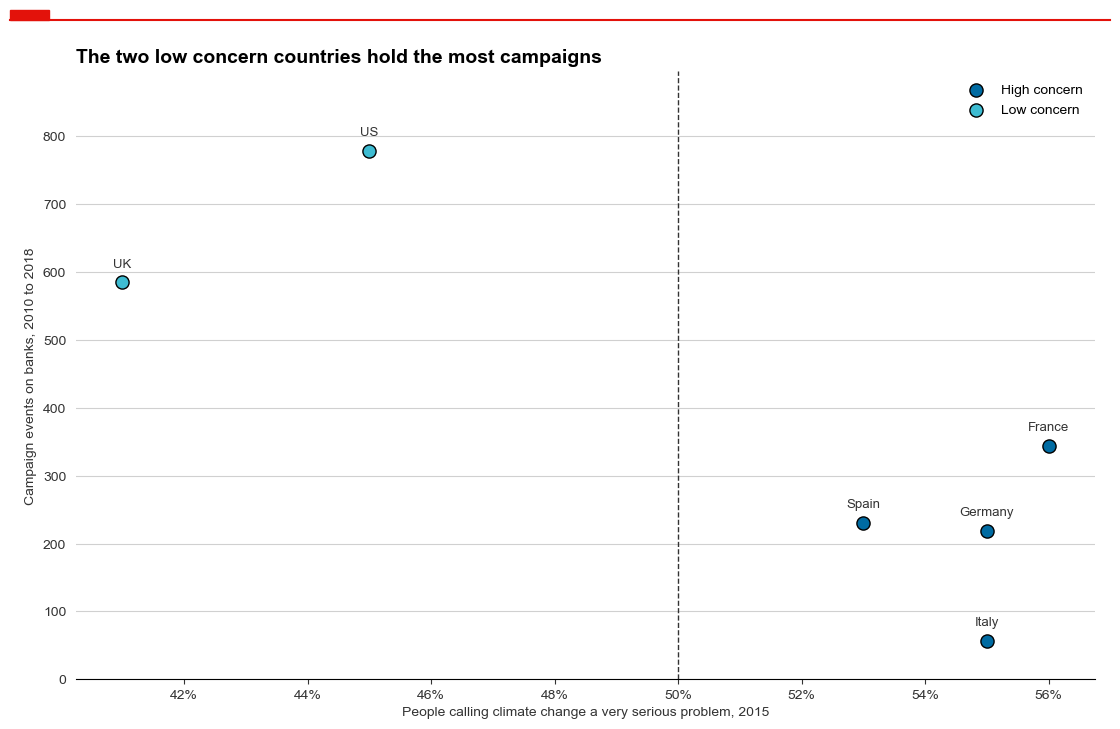

In [732]:
fig, ax = plt.subplots(figsize=(11, 7))
plot_concern(ax, country_table)
ax.set_title("The two low concern countries hold the most campaigns")
show()

**Comments – 7.1**
* **The six countries cover most of our sample:** 84% of all events. The Netherlands, Sweden, Belgium and the small countries are not in this comparison.

* **The two groups are clear:** the US and the UK stand at 41% to 45%, the four continental countries at 53% to 56%.

* **Campaigns are not where concern is:** the two low concern countries hold the most events (US 779, UK 585), and the correlation is −0.82, on six points only.

* **This mostly reflects the number of banks:** per bank, France (86) and the UK (84) lead, followed by Germany (73), the US (32), Spain (29) and Italy (14), so high and low concern countries mix.

### 7.2 Do banks react more in high concern countries?
This is a split of Task #6, with the same function: the winsorised CARs of negative events over $[-10, +10]$, market model, high against low concern.

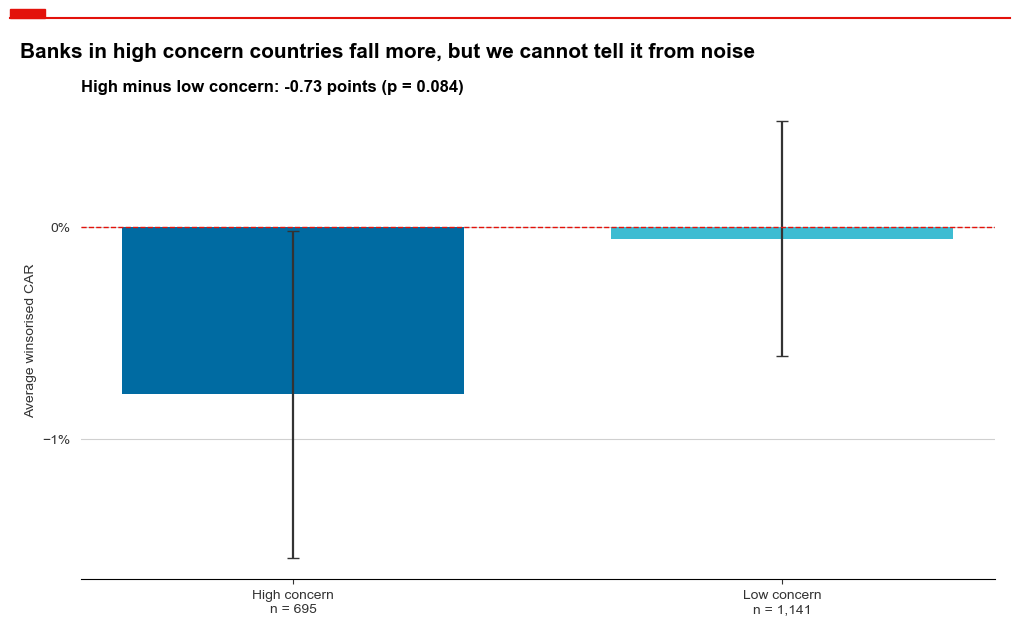

In [733]:
in_survey = negative_events["country"].isin(concern.index)
concern_events = negative_events[in_survey]
event_concern = concern_events["country"].map(concern_groups)

concern_split = compare_groups(concern_events, event_concern == "High",
                               "High concern", "Low concern")

fig, ax = plt.subplots(figsize=(10, 6))
plot_groups(ax, concern_split)
ax.set_ylabel("Average winsorised CAR")
ax.set_title(difference_title("High minus low concern", concern_split),
             fontsize=12)
show("Banks in high concern countries fall more, but we cannot tell it from "
     "noise")

With six countries one of them can decide the result, so we look at each country, and at the split without Italy, which has the lowest mean and the fewest events.

In [734]:
cars_by_country = concern_events.groupby("country")[MAIN_CAR]
country_cars = cars_by_country.agg(["mean", "count"])
country_cars = country_cars.loc[concern.sort_values().index]

without_italy = concern_events[concern_events["country"] != "Italy"]
group_without_italy = without_italy["country"].map(concern_groups)
split_without_italy = compare_groups(without_italy,
                                     group_without_italy == "High",
                                     "High concern", "Low concern")

print(f"Without Italy: {split_without_italy['difference']:+.2%}, "
      f"p = {split_without_italy['p value']:.3f}")
country_cars.style.format({"mean": "{:+.2%}", "count": "{:,}"})

Without Italy: -0.58%, p = 0.167


,mean,count
UK,-0.27%,478
US,+0.10%,663
Spain,-0.26%,193
Germany,-0.73%,191
Italy,-2.88%,47
France,-0.85%,264


**Comments – 7.2**
* **The gap has the expected sign:** banks in high concern countries lose −0.79% after negative events, against −0.06% in low concern countries, a gap of −0.73 points. With p = 0.084 we cannot tell it from noise.

* **One country carries much of it:** Italy stands at −2.88% on only 47 events. Without Italy the gap falls to −0.58 points (p = 0.167).

* **High concern is not one group:** Spain (−0.26%) sits next to the UK (−0.27%), while Germany (−0.73%) and France (−0.85%) stand lower.

* **Six countries only:** clustering by day 0 treats these as about 1,800 events, but concern varies across six countries, so the interval is too narrow.

* **The split equals continental against Anglo Saxon:** high concern means the four continental countries, low concern the US and the UK. Banking systems, regulation, markets and currencies differ in the same way, so we cannot isolate attitudes to climate change.

* **So the result is suggestive at best.** It came after the 9 comparisons of Task #6, and it does not change our answer.

## Conclusion
One figure carries our answer. The left panel sets our raw CAR paths next to the published means of Krüger (2015). The right panel shows the comparisons on winsorised CARs: the 9 of Task #6 and the one of Task #7, which came later.

In [735]:
all_comparisons = {"Negative minus positive": sign_market}
for name, result in splits.items():
    label = f"{name}: {result['first']} minus {result['second']}"
    all_comparisons[label] = result
all_comparisons["Climate concern: High minus Low"] = concern_split

comparisons = pd.DataFrame(all_comparisons).T
comparisons["half width"] = Z_95 * comparisons["error"].astype(float)
comparisons["difference"] = comparisons["difference"].astype(float)

is_crossing = comparisons["difference"].abs() <= comparisons["half width"]
crossing_zero = is_crossing.sum()
below_five = (comparisons["p value"] < ALPHA).sum()

print(f"Comparisons: {len(comparisons)}, crossing zero: {crossing_zero}, "
      f"below 5%: {below_five}")
print(f"Lowest p value: {comparisons['p value'].min():.3f}")

Comparisons: 10, crossing zero: 10, below 5%: 0
Lowest p value: 0.084


In [736]:
def plot_kruger(ax, value, color, label):
    '''Mark a mean CAR of Krüger (2015) at day +10, with its label.'''
    ax.scatter(EVENT_END, value, marker="D", s=70, color=color,
               edgecolors="black", zorder=4)
    annotate(ax, f"{value:+.2%}  Krüger (2015), {label}", (EVENT_END, value))

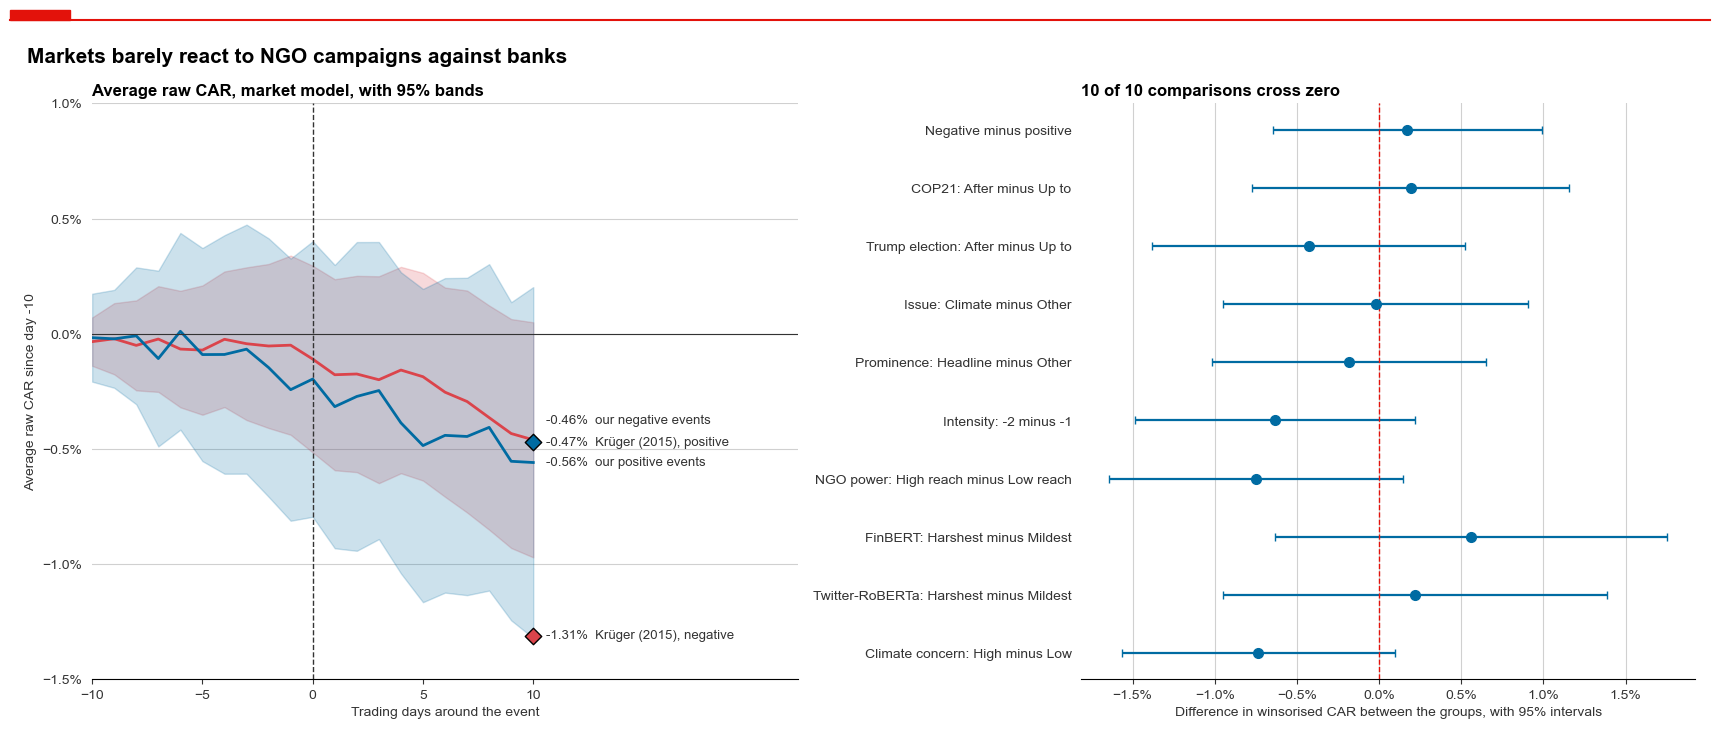

In [737]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7),
                         gridspec_kw={"width_ratios": [1.15, 1]})

# The labels at day +10 sit close together, so the first one moves up
for sign, shift in [("negative", 14), ("positive", 0)]:
    plot_car_path(axes[0], paths["market", sign], SENTIMENT_COLORS[sign],
                  f"our {sign} events", label_shift=shift)
plot_kruger(axes[0], KRUGER_NEGATIVE, SENTIMENT_COLORS["negative"], "negative")
plot_kruger(axes[0], KRUGER_POSITIVE, SENTIMENT_COLORS["positive"], "positive")
format_car_axis(axes[0], "Average raw CAR, market model, with 95% bands")
axes[0].set_xlim(EVENT_START, EVENT_END + 12)  # room for the labels
axes[0].set_ylabel("Average raw CAR since day -10")

plot_checks(axes[1], comparisons, "difference", "half width",
            ECONOMIST_COLORS[0],
            f"{crossing_zero} of {len(comparisons)} comparisons cross zero")
axes[1].set_xlabel("Difference in winsorised CAR between the groups, "
                   "with 95% intervals")
show("Markets barely react to NGO campaigns against banks")

**Our answer.** Markets barely react to NGO campaigns against banks. On the tests of Krüger (2015) negative events do fall, with a BMP statistic of −3.64 and a sign statistic of −3.98. But the reaction is about a third of his: a raw mean CAR of −0.46%, or 35% of his −1.31%. And we cannot separate it from good news: positive events end at −0.56%, and on winsorised CARs the difference is +0.17 points (p = 0.679).

**What this rests on.** The fall of negative events depends on the test. With clustered errors the mean does not reject (p = 0.115), with five factors the BMP statistic is −1.49 (p = 0.135), and random days of the same banks end at −0.34%. The gap to good news stays near zero: 10 of 10 comparisons cross zero, 0 fall below 5%, and the difference is significant in 0 of the 12 robustness checks (lowest p value 0.259). This is no proof of a zero effect: our test has 52% power against Krüger's gap of −0.84 points, and his interval of ± 0.64 points overlaps our +0.17 ± 0.82.

**Possible reasons.** Banks may be targeted so often that one report is no news: the median event has 12 others of the same bank in its estimation window. Sigwatch dates can also lag the real news, so a reaction may fall before our window.

**With more time.** We would add a news filter (Factiva), to remove earnings and crises from the event windows. We would build Tasks #1 and #2, to see which campaigns reach the press and social media. And we would test the links in the Sigwatch files and read the NGO web pages, to score the full reports.

## References
* Boehmer, E., Musumeci, J. and Poulsen, A. (1991), Event-study methodology under conditions of event-induced variance, *Journal of Financial Economics* 30, 253–272.
* Cowan, A. (1992), Nonparametric event study tests, *Review of Quantitative Finance and Accounting* 2, 343–358.
* Fama, E. and French, K. (2015), A five-factor asset pricing model, *Journal of Financial Economics* 116, 1–22.
* Koenig, P. (2017), Notes on Sigwatch's NGO campaign database, preprint, halshs-01671758.
* Krüger, P. (2015), Corporate goodness and shareholder wealth, *Journal of Financial Economics* 115, 304–329.
* Pew Research Center (2015), Global Concern about Climate Change, Broad Support for Limiting Emissions, 5 November.